# Alien pilot · behavioral signatures & identifiability dashboard
**Strategy:** (1) Isolate behavioral signatures by question type; (2) relate signatures within participants, with uncertainty and trial-denominator checks; (3) ask which signatures HOLMES distinguishes as α and ρ vary. This is exploratory pilot analysis, not confirmatory inference.

**Inputs:** current Gorilla CSV, `spec.json`, and `holmes_inheritance_model_v1.py` in this folder. **Run all:** fast descriptive analyses by default; set `RUN_MODEL_FITS=True` in Setup for optional model analysis. Each run refreshes data, including new participants.

In [81]:
# SETUP
import sys, importlib, re
from pathlib import Path
from dataclasses import dataclass
from itertools import product, combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import t
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", context="notebook")

# Find newest/largest cumulative Gorilla export.
DATA_FILE = Path("pilot_aliens_data/data_exp_283900-v2_task-1hkb1.csv")
if not DATA_FILE.exists():
    candidates = list(Path(".").rglob("*283900*.csv"))
    if len(candidates)==1: DATA_FILE=candidates[0]
if not DATA_FILE.exists():
    raise FileNotFoundError(f"Original Gorilla CSV is needed: {DATA_FILE}. Place it in pilot_aliens_data/ or set DATA_FILE explicitly.")
print("Data:", DATA_FILE)

# HOLMES module.

try:
    import holmes_inheritance_model_v1 as HOLMES
except ModuleNotFoundError:
    import importlib.util
    matches=list(Path('.').glob('holmes_inheritance_model_v1*.py'))
    if len(matches)!=1: raise FileNotFoundError('Place the supplied HOLMES .py file beside this notebook.')
    spec=importlib.util.spec_from_file_location('holmes_inheritance_model_v1', matches[0]); HOLMES=importlib.util.module_from_spec(spec); spec.loader.exec_module(HOLMES)
print("HOLMES:", HOLMES.__file__)

# Task/model constants.
FAMILY_SIZES = [8, 2, 4, 8]                    # alien, resource, gem, gadget
RESOURCE = np.array([0,0,0,0, 1,1,1,1])
GEM      = np.array([0,0,1,1, 2,2,3,3])
GADGET   = np.arange(8)
ALIENS   = [f"A{i}" for i in range(1,9)]
PAIRS    = list(combinations(ALIENS, 2))
FAM_CODE = {"resource":1, "gem":2, "gadget":3}

import json
SPEC_FILE=Path('spec.json')
if not SPEC_FILE.exists():
    raise FileNotFoundError('Place spec.json next to the notebook.')
SPEC=json.loads(SPEC_FILE.read_text(encoding='utf-8'))
SCHEDULES={s['key']:pd.DataFrame(s['rows']) for s in SPEC['spreadsheets']}


Data: pilot_aliens_data/data_exp_283900-v2_task-1hkb1.csv
HOLMES: /Users/ines/Library/CloudStorage/OneDrive-Personal/GitHub/HOLMES_2026/holmes_inheritance_model_v1.py


## 1 · Parse and audit the cumulative export
Source of truth: raw Gorilla rows; retain partial participants and flag missing responses. Ordering uses original event indices.

In [82]:
# HUMAN DATA -> TRIALS, GROUPINGS, PAIRWISE, PARTICIPANTS
raw = pd.read_csv(DATA_FILE)
raw["event"] = pd.to_numeric(raw["Event Index"], errors="coerce")
raw["private_id"] = pd.to_numeric(raw["Participant Private ID"], errors="coerce").astype("Int64").astype("string")
ids = sorted(raw["private_id"].dropna().unique())
raw["subject"] = raw["private_id"].map({pid:f"P{i+1:03d}" for i,pid in enumerate(ids)})
raw["rt_s"] = pd.to_numeric(raw["Reaction Time"], errors="coerce")/1000

LEARN = {"basic_resources_trial":"resource","precious_gems_trial":"gem","gadget_trial":"gadget"}
PROBE = {"rt_probes_blue_trial":"resource","rt_probes_orange_trial":"gem","rt_probes_black_trial":"gadget"}
CHECKPOINT_NAMES = {1:"Baseline",2:"Post-learning",3:"Post-single probes",4:"Post-multi probes",5:"Final"}
STAGE_ORDER = ["Resource 1","Gem 1","Gadget","Gem 2","Resource 2",
               "Resource probe","Gem probe","Gadget probe","Multi probe"]

def parse_choice_rows(displays, trial_type):
    d = raw[raw["subject"].notna() & raw["Display"].isin(displays) & (raw["Response Type"]=="response")].copy()
    if trial_type=="learning": d = d[d["Screen"].eq("keyboard_response")]
    d["trial_type"], d["family"] = trial_type, d["Display"].map(displays)
    d["alien"] = d["Spreadsheet: alien_stim"].str.extract(r"(A\d+)", expand=False)
    d["choice"], d["answer"] = d["Response"].astype("string"), d["Spreadsheet: answer"].astype("string")
    d["correct"] = pd.to_numeric(d["Correct"], errors="coerce")
    d["task_trial"] = pd.to_numeric(d["Trial Number"], errors="coerce")
    return d

learning = parse_choice_rows(LEARN, "learning")
learning["stage"] = np.select(
    [(learning.family=="resource")&(learning.task_trial<=16),
     (learning.family=="resource")&(learning.task_trial>16),
     (learning.family=="gem")&(learning.task_trial<=18),
     (learning.family=="gem")&(learning.task_trial>18),
     learning.family=="gadget"],
    ["Resource 1","Resource 2","Gem 1","Gem 2","Gadget"], default="Unknown")

single = parse_choice_rows(PROBE, "single_probe")
single["stage"] = single["family"].str.capitalize()+" probe"

multi = raw[raw["subject"].notna() & raw["Display"].eq("rt_probes_multi") & raw["Response Type"].eq("response")].copy()
multi["trial_type"], multi["family"], multi["stage"] = "multi_probe", "multi", "Multi probe"
multi["alien"] = multi["Spreadsheet: alien_stim"].str.extract(r"(A\d+)", expand=False)
multi["choice"], multi["answer"] = multi["Response"].astype("string"), multi["Spreadsheet: answer"].astype("string")
multi["correct"] = pd.to_numeric(multi["Correct"], errors="coerce")
multi["task_trial"] = pd.to_numeric(multi["Trial Number"], errors="coerce")

KEEP = ["subject","private_id","event","trial_type","stage","family","task_trial","alien","choice","answer","correct","rt_s"]
TRIALS = pd.concat([learning[KEEP], single[KEEP], multi[KEEP]], ignore_index=True).sort_values(["subject","event"]).reset_index(drop=True)

# Explicit groupings: retain final placement of each alien within checkpoint.
moves = raw[raw["subject"].notna() & raw["Display"].eq("explicit_grouping_trial") & raw["Response Type"].eq("response")].copy()
xy = moves["Response"].str.extract(r"^(A\d+)\.pngH(\d+)$")
moves["alien"], moves["box"] = xy[0], pd.to_numeric(xy[1], errors="coerce")
moves["checkpoint"] = pd.to_numeric(moves["Trial Number"], errors="coerce")
moves["checkpoint_name"] = moves["checkpoint"].map(CHECKPOINT_NAMES)
GROUPINGS = (moves.dropna(subset=["alien","box"]).sort_values(["subject","checkpoint","event"])
             .groupby(["subject","checkpoint","alien"], as_index=False).tail(1)
             [["subject","checkpoint","checkpoint_name","alien","box","event"]]
             .sort_values(["subject","checkpoint","alien"]).reset_index(drop=True))
GROUPING_SUMMARY = GROUPINGS.groupby(["subject","checkpoint","checkpoint_name"], as_index=False).agg(
    n_aliens=("alien","nunique"), n_groups=("box","nunique"))

# Pairwise representation.
RESOURCE_GROUP = {a:int(a[1:])>4 for a in ALIENS}
GEM_GROUP = {"A1":0,"A2":0,"A3":1,"A4":1,"A5":2,"A6":2,"A7":3,"A8":3}
rows = []
for (sid,cp),d in GROUPINGS.groupby(["subject","checkpoint"]):
    pos = dict(zip(d.alien,d.box))
    for a,b in PAIRS:
        if a not in pos or b not in pos: continue
        sr, sg = RESOURCE_GROUP[a]==RESOURCE_GROUP[b], GEM_GROUP[a]==GEM_GROUP[b]
        typ = "same_gem" if sg else ("same_resource_diff_gem" if sr else "different_resource")
        rows.append((sid,cp,CHECKPOINT_NAMES[int(cp)],a,b,int(pos[a]==pos[b]),typ))
PAIRWISE = pd.DataFrame(rows, columns=["subject","checkpoint","checkpoint_name","alien_1","alien_2","same_group","pair_type"])
PAIRWISE_PROFILE = PAIRWISE.groupby(["subject","checkpoint","checkpoint_name","pair_type"], as_index=False).agg(
    p_same=("same_group","mean"), n_pairs=("same_group","size"))
PAIRWISE_WIDE = (PAIRWISE_PROFILE.pivot(index=["subject","checkpoint","checkpoint_name"], columns="pair_type", values="p_same")
                 .reset_index().rename(columns={"same_gem":"gem_cohesion",
                     "same_resource_diff_gem":"resource_cohesion","different_resource":"cross_resource_merge"}))

# One row per participant.
STAGE = TRIALS.groupby(["subject","stage"], as_index=False).agg(
    n=("correct","size"), accuracy=("correct","mean"), median_rt_s=("rt_s","median"))
STAGE["stage"] = pd.Categorical(STAGE["stage"], categories=STAGE_ORDER, ordered=True)
clean = lambda x: re.sub(r"[^a-z0-9]+","_",str(x).lower()).strip("_")

base = TRIALS.groupby("subject").agg(overall_accuracy=("correct","mean"), overall_median_rt=("rt_s","median"))
la = TRIALS[TRIALS.trial_type.eq("learning")].groupby("subject")["correct"].mean().rename("learning_accuracy")
pa = TRIALS[TRIALS.trial_type.isin(["single_probe","multi_probe"])].groupby("subject")["correct"].mean().rename("probe_accuracy")
acc = STAGE.pivot(index="subject", columns="stage", values="accuracy"); acc.columns=[f"acc_{clean(c)}" for c in acc.columns]
rt  = STAGE.pivot(index="subject", columns="stage", values="median_rt_s"); rt.columns=[f"rt_{clean(c)}" for c in rt.columns]
ng  = GROUPING_SUMMARY.pivot(index="subject", columns="checkpoint_name", values="n_groups"); ng.columns=[f"n_groups_{clean(c)}" for c in ng.columns]
pw  = PAIRWISE_WIDE.pivot(index="subject", columns="checkpoint_name",
                          values=["gem_cohesion","resource_cohesion","cross_resource_merge"])
pw.columns=[f"{clean(m)}_{clean(cp)}" for m,cp in pw.columns]
PARTICIPANTS = base.join(la).join(pa).join(acc).join(rt).join(ng).join(pw).reset_index()

print(f"N={PARTICIPANTS.subject.nunique()} participants")
display(PARTICIPANTS)

N=9 participants


,subject,overall_accuracy,overall_median_rt,learning_accuracy,probe_accuracy,acc_resource_1,acc_gem_1,acc_gadget,acc_gem_2,acc_resource_2,...,resource_cohesion_baseline,resource_cohesion_final,resource_cohesion_post_learning,resource_cohesion_post_multi_probes,resource_cohesion_post_single_probes,cross_resource_merge_baseline,cross_resource_merge_final,cross_resource_merge_post_learning,cross_resource_merge_post_multi_probes,cross_resource_merge_post_single_probes
0,P001,0.485075,4.11160,0.500000,0.458333,0.5000,0.222222,0.541667,0.666667,0.50,...,0.000,0.00,0.00,0.000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000
1,P002,0.492537,3.02140,0.337209,0.770833,0.3750,0.388889,0.083333,0.458333,0.75,...,0.000,0.00,0.00,0.000,0.000,0.1250,0.1250,0.1250,0.1250,0.1250
2,P003,0.313433,4.24425,0.337209,0.270833,0.3750,0.111111,0.166667,0.708333,0.00,...,0.000,0.00,0.00,0.000,0.000,0.2500,0.0000,0.2500,0.2500,0.2500
3,P004,0.358209,2.50485,0.267442,0.520833,0.5000,0.333333,0.125000,0.208333,0.25,...,0.500,0.00,0.00,0.000,0.000,0.0000,0.2500,0.1875,0.5000,0.1250
4,P005,0.171642,2.44503,0.186047,0.145833,0.0625,0.055556,0.166667,0.416667,0.00,...,0.000,0.00,0.00,0.000,0.125,0.1250,0.0000,0.1250,0.0000,0.1250
5,P006,0.484848,3.17030,0.418605,0.608696,0.5625,0.388889,0.208333,0.583333,0.25,...,0.125,0.00,0.00,0.125,0.125,0.2500,0.3125,0.2500,0.3125,0.3125
6,P007,0.425373,1.73760,0.197674,0.833333,0.1250,0.166667,0.083333,0.375000,0.25,...,0.000,0.25,0.25,0.125,0.250,0.2500,0.3750,0.3125,0.1875,0.3125
7,P008,0.277778,4.29246,0.325581,0.175000,0.3125,0.444444,0.250000,0.250000,0.75,...,0.000,0.25,0.00,0.000,0.000,0.1875,0.2500,0.1250,0.0625,0.0625
8,P009,0.335821,3.00390,0.186047,0.604167,0.4375,0.111111,0.083333,0.166667,0.25,...,0.250,0.00,0.00,0.125,0.500,0.5000,0.1250,0.2500,0.3125,0.5000


In [83]:
# Coverage, exclusions, and raw-response audit; never silently drop participants.
print('Subjects in raw / trials / grouping:', raw.subject.nunique(), TRIALS.subject.nunique(), GROUPINGS.subject.nunique())
coverage=TRIALS.groupby(['subject','trial_type','family']).agg(n=('choice','size'),missing_choice=('choice',lambda s:s.isna().sum()),missing_alien=('alien',lambda s:s.isna().sum())).reset_index()
display(coverage)
expected=GROUPINGS.groupby(['subject','checkpoint']).alien.nunique().rename('n_aliens').reset_index()
display(expected.assign(complete=lambda x:x.n_aliens.eq(8)))
assert TRIALS.event.notna().all(), 'Missing event ordering: review raw export.'
assert not TRIALS.duplicated(['subject','event']).any(), 'Repeated event IDs: verify event parsing.'

Subjects in raw / trials / grouping: 9 9 9


,subject,trial_type,family,n,missing_choice,missing_alien
0,P001,learning,gadget,24,0,0
1,P001,learning,gem,42,0,0
2,P001,learning,resource,20,0,0
3,P001,multi_probe,multi,24,0,0
4,P001,single_probe,gadget,8,0,0
...,...,...,...,...,...,...
58,P009,learning,resource,20,0,0
59,P009,multi_probe,multi,24,0,0
60,P009,single_probe,gadget,8,0,0
61,P009,single_probe,gem,8,0,0


,subject,checkpoint,n_aliens,complete
0,P001,1.0,8,True
1,P001,2.0,8,True
2,P001,3.0,8,True
3,P001,4.0,8,True
4,P001,5.0,7,False
5,P002,1.0,8,True
6,P002,2.0,8,True
7,P002,3.0,8,True
8,P002,4.0,8,True
9,P002,5.0,8,True


## 1b · Complete question-type inventory
Gorilla's event log has multiple rows per question. The table counts actual response-bearing trials, **not all event rows**. Compare against `spec.json`'s `pilot` schedule to flag question families that were designed but not administered. Do not pool unrelated scoring rules.

,events,participants,valid_responses,min_trials,median_trials,max_trials,scheduled_pilot_rows,pilot_coverage
basic_resources_instructions,0.0,0.0,0.0,NaN,NaN,NaN,1,not observed
basic_resources_instructions_round_two,0.0,0.0,0.0,NaN,NaN,NaN,1,not observed
basic_resources_trial,180.0,9.0,180.0,20.0,20.0,20.0,20,observed
closing_screen,0.0,0.0,0.0,NaN,NaN,NaN,1,not observed
explicit_grouping_instructions,0.0,0.0,0.0,NaN,NaN,NaN,5,not observed
explicit_grouping_trial,371.0,9.0,371.0,5.0,5.0,5.0,5,observed
gadget_instructions,0.0,0.0,0.0,NaN,NaN,NaN,1,not observed
gadget_trial,216.0,9.0,216.0,24.0,24.0,24.0,24,observed
grouping_instructions,0.0,0.0,0.0,NaN,NaN,NaN,1,not observed
grouping_trial,141.0,9.0,141.0,8.0,8.0,8.0,8,observed


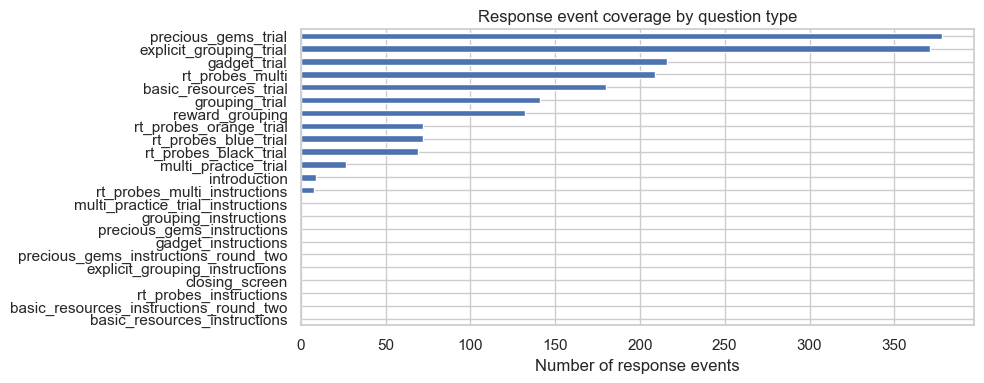

Defined in other schedules but not in pilot: ['combinations2_test', 'combinations3_test', 'combinations_instructions', 'combinations_test', 'grouping_trial_3', 'hierarchy_test_instructions', 'hierarchy_test_trial', 'level_two_round_two_test', 'radioactive_trial_round_two']


In [84]:
# Trial coverage: count unique participant + trial number within each Display.
responses=raw[raw.subject.notna() & raw['Response Type'].eq('response')].copy()
COVERAGE=(responses.groupby('Display').agg(events=('event','size'),participants=('subject','nunique'),
    valid_responses=('Response','count')).sort_values('events',ascending=False))
counts=(responses.groupby(['Display','subject'])['Trial Number'].nunique().groupby('Display')
        .agg(min_trials='min',median_trials='median',max_trials='max'))
COVERAGE=COVERAGE.join(counts)
pilot=SCHEDULES['pilot']; pilot_counts=pilot['display'].value_counts().rename('scheduled_pilot_rows')
COVERAGE=COVERAGE.join(pilot_counts,how='outer').fillna({'events':0,'participants':0,'valid_responses':0,'scheduled_pilot_rows':0})
COVERAGE['pilot_coverage']=np.where(COVERAGE.events.gt(0),'observed','not observed')
display(COVERAGE)
fig,ax=plt.subplots(figsize=(10,4)); COVERAGE.sort_values('events').events.plot.barh(ax=ax)
ax.set(title='Response event coverage by question type',xlabel='Number of response events');plt.tight_layout();plt.show()
# Trial definitions present outside the pilot design are NOT presumed administered.
other=sorted(set(SCHEDULES['Spreadsheet1'].get('display',pd.Series(dtype=str)).dropna())|
             set(SCHEDULES['Spreadsheet2'].get('display',pd.Series(dtype=str)).dropna())|
             set(SCHEDULES['Spreadsheet3'].get('display',pd.Series(dtype=str)).dropna()))
print('Defined in other schedules but not in pilot:', sorted(set(other)-set(pilot.display.dropna())))

## 2 · Fast cohort overview
These panels update automatically as participants are appended. **Chance:** resource 1/2, gem 1/4, gadget 1/8; all repeated-trial summaries are descriptive.

Participants: 9 | learning trials: 774 | single probes: 213


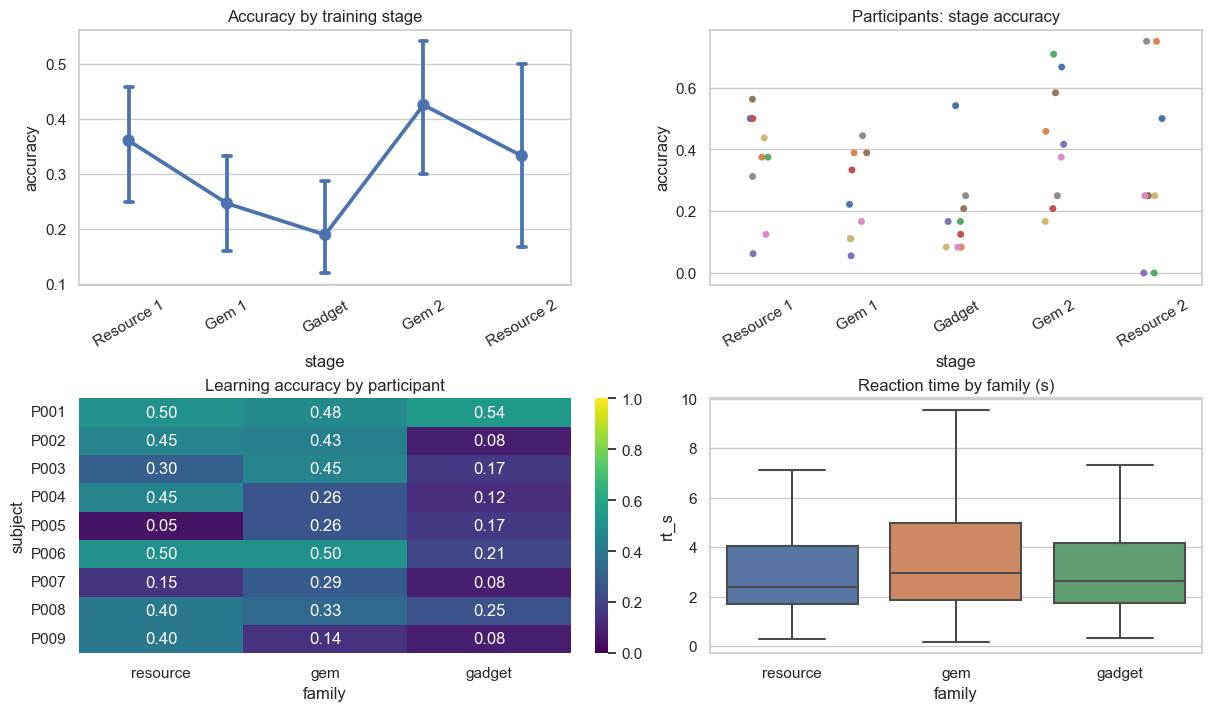

family,resource,gem,gadget
subject,,,
P001,0.50,0.476,0.542
P002,0.45,0.429,0.083
P003,0.30,0.452,0.167
P004,0.45,0.262,0.125
P005,0.05,0.262,0.167
P006,0.50,0.500,0.208
P007,0.15,0.286,0.083
P008,0.40,0.333,0.250
P009,0.40,0.143,0.083


In [85]:
CHANCE={'resource':.5,'gem':.25,'gadget':.125}
learning=TRIALS[TRIALS.trial_type.eq('learning')].copy()
learning['chance']=learning.family.map(CHANCE)
print(f"Participants: {TRIALS.subject.nunique()} | learning trials: {len(learning):,} | single probes: {sum(TRIALS.trial_type.eq('single_probe')):,}")
fig,axs=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
order=['Resource 1','Gem 1','Gadget','Gem 2','Resource 2']
ss=STAGE[STAGE.stage.isin(order)].copy();ss['stage']=ss.stage.astype(str)
sns.pointplot(data=ss,x='stage',y='accuracy',order=order,errorbar=('ci',95),ax=axs[0,0],capsize=.08)
axs[0,0].tick_params(axis='x',rotation=30);axs[0,0].set_title('Accuracy by training stage')
sns.stripplot(data=ss,x='stage',y='accuracy',order=order,hue='subject',ax=axs[0,1],size=5,legend=False)
axs[0,1].tick_params(axis='x',rotation=30);axs[0,1].set_title('Participants: stage accuracy')
acc=learning.groupby(['subject','family']).correct.mean().unstack().reindex(columns=list(CHANCE))
sns.heatmap(acc,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='viridis',ax=axs[1,0]);axs[1,0].set_title('Learning accuracy by participant')
sns.boxplot(data=learning,x='family',y='rt_s',order=list(CHANCE),ax=axs[1,1],showfliers=False)
axs[1,1].set_title('Reaction time by family (s)')
plt.show()
display(acc.round(3))

## 3 · Exposure-based learning curves and confusions
Exact prior exposures are computed from the *participant’s schedule* before each choice. Show chance lines and individual trajectories; never interpret 0 exposures as transfer without qualifying training history.

In [86]:
KEYS=["A","S","D","F","H","J","K","L"]
KEYMAP={
    "resource":{"A":0,"H":1},
    "gem":{"S":0,"F":1,"J":2,"L":3},
    "gadget":{"A":0,"S":1,"D":2,"F":3,"H":4,"J":5,"K":6,"L":7},
}

def subject_task(sid):
    d=(TRIALS[
        (TRIALS.subject==sid) &
        TRIALS.trial_type.isin(["learning","single_probe"])
    ].sort_values("event").copy())

    # HOLMES feature-family indices:
    # 0 = alien identity, 1 = resource, 2 = gem, 3 = gadget
    fam_code={"resource":1,"gem":2,"gadget":3}
    truth={1:RESOURCE,2:GEM,3:GADGET}

    s=pd.DataFrame({
        "trial":np.arange(1,len(d)+1),
        "phase":d.stage.astype(str).to_numpy(),
        "trial_type":np.where(d.trial_type.eq("learning"),"learning","probe"),
        "alien":d.alien.str.extract(r"(\d+)",expand=False).astype(int).to_numpy()-1,
        "family_name":d.family.astype(str).str.lower().to_numpy(),
        "choice":d.choice.astype(str).to_numpy()
    })

    # sanity check before mapping
    bad=set(s.family_name)-set(fam_code)
    if bad:
        raise ValueError(f"Unexpected family labels for {sid}: {bad}")

    s["query_family"]=s.family_name.map(fam_code).astype(int)
    s["has_feedback"]=s.trial_type.eq("learning")
    s["true_value"]=[
        int(truth[f][a])
        for a,f in zip(s.alien,s.query_family)
    ]

    a=s.alien.to_numpy(int)
    data=np.vstack([a,RESOURCE[a],GEM[a],GADGET[a]])

    fb=np.zeros_like(data,bool)
    pred=np.zeros_like(data,bool)
    fb[0]=pred[0]=True

    w=np.ones_like(data,float)

    for t,r in s.iterrows():
        q=int(r.query_family)

        if r.has_feedback:
            fb[q,t]=True

        if q==2:
            w[2,t]=2.
        elif q==3:
            w[0,t],w[3,t]=3.,2.

        if r.trial_type=="probe":
            w[0,t]=3.

    task=dict(
        schedule=s,
        data=data,
        feedback_mask=fb,
        prediction_mask=pred,
        family_weights=w
    )

    if WEIGHT_SCHEME == "unit": task["family_weights"][:]=1.
    return s,task

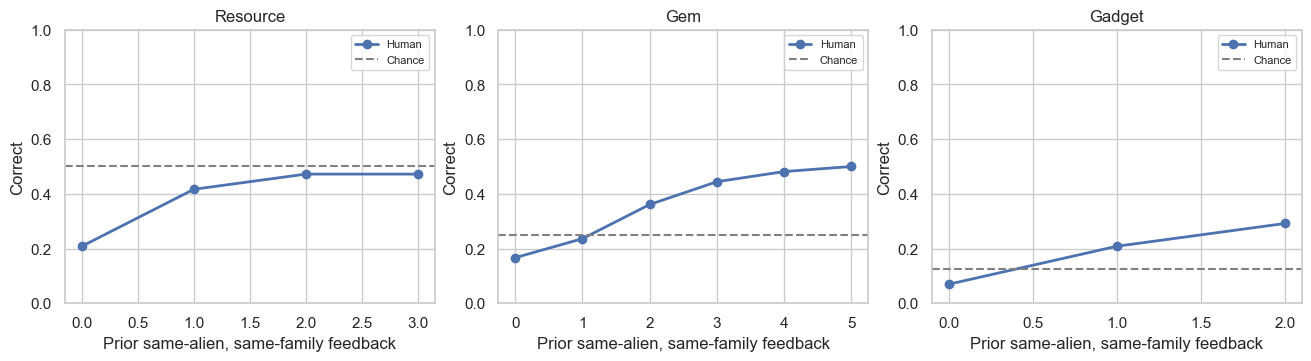

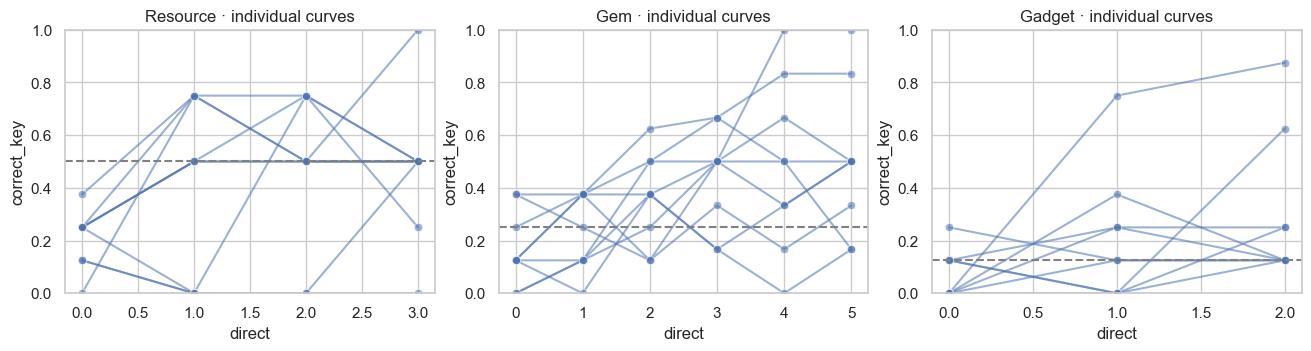

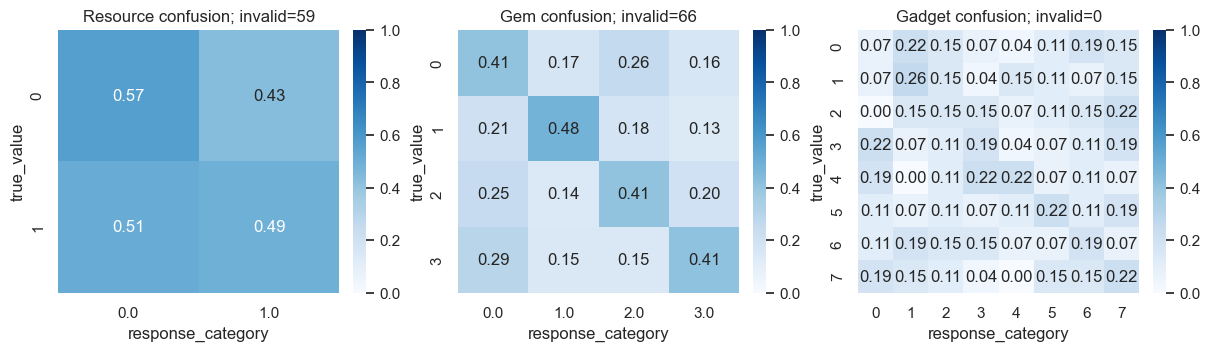

In [87]:
def exposure_history(s):
    counts=np.zeros((8,3),int); records=[]
    for r in s.itertuples(index=False):
        a=int(r.alien);q=['resource','gem','gadget'].index(r.family_name)
        same_gem=(GEM==GEM[a])&(np.arange(8)!=a)
        resource_only=(RESOURCE==RESOURCE[a])&(GEM!=GEM[a])
        records.append(dict(direct=int(counts[a,q]),direct_resource=int(counts[a,0]),
            direct_gem=int(counts[a,1]),direct_gadget=int(counts[a,2]),
            partner_resource=int(counts[same_gem,0].sum()),
            partner_gem=int(counts[same_gem,1].sum()),
            resource_other=int(counts[resource_only,0].sum()),
            higher_level_anchor=int(counts[(GEM==GEM[a])&(np.arange(8)!=a),0].sum())))
        if r.has_feedback: counts[a,q]+=1
    return pd.DataFrame(records)
HISTORY=[]
for sid in sorted(TRIALS.subject.dropna().unique()):
    s,task=subject_task(sid); h=exposure_history(s)
    s=s.copy();s['subject']=sid
    s['correct_key']=[int(str(r.choice) in KEYMAP[r.family_name] and KEYMAP[r.family_name][str(r.choice)]==r.true_value) for r in s.itertuples()]
    HISTORY.append(pd.concat([s,h],axis=1))
HISTORY=pd.concat(HISTORY,ignore_index=True)
LEARN_H=HISTORY[HISTORY.has_feedback].copy()
fig,axs=plt.subplots(1,3,figsize=(13,3.5),constrained_layout=True)
for ax,f in zip(axs,CHANCE):
    d=LEARN_H[LEARN_H.family_name==f].copy()
    g=d.groupby('direct').correct_key.agg(['mean','size']).reset_index()
    ax.plot(g.direct,g['mean'],marker='o',lw=2,label='Human')
    ax.axhline(CHANCE[f],ls='--',c='gray',label='Chance')
    ax.set_ylim(0,1);ax.set_title(f.title());ax.set_xlabel('Prior same-alien, same-family feedback');ax.set_ylabel('Correct');ax.legend(fontsize=8)
plt.show()
fig,axs=plt.subplots(1,3,figsize=(13,3.4),constrained_layout=True)
for ax,f in zip(axs,CHANCE):
    d=LEARN_H[LEARN_H.family_name==f]
    gg=d.groupby(['subject','direct']).correct_key.mean().reset_index()
    sns.lineplot(data=gg,x='direct',y='correct_key',units='subject',estimator=None,alpha=.55,ax=ax,marker='o',legend=False)
    ax.axhline(CHANCE[f],ls='--',c='gray');ax.set_ylim(0,1);ax.set_title(f'{f.title()} · individual curves')
plt.show()
# Response confusion: actual outcome category versus selected category, invalid excluded and counted.
fig,axs=plt.subplots(1,3,figsize=(12,3.4),constrained_layout=True)
for ax,f in zip(axs,CHANCE):
    d=LEARN_H[LEARN_H.family_name==f].copy()
    d['response_category']=d.choice.map(KEYMAP[f]);matrix=pd.crosstab(d.true_value,d.response_category,normalize='index')
    sns.heatmap(matrix,annot=True,fmt='.2f',cmap='Blues',vmin=0,vmax=1,ax=ax)
    ax.set_title(f'{f.title()} confusion; invalid={d.response_category.isna().sum()}')
plt.show()

## 4 · Schedule-defined upward transfer
Primary readout: **first resource response with zero prior resource feedback but lower-level experience**. Separate these from initial untrained trials and later resource probes. A trial with lower-level exposure is *eligible* for transfer, but identifying the resource may depend on other learned links. Raw performance and anchor availability are reported separately.

Schedule-defined eligible upward-transfer events: 6


,subject,phase,trial_type,alien,direct_gem,direct_gadget,partner_resource,correct_key
83,P001,Resource 2,learning,1,6,3,4,1
305,P003,Resource 2,learning,7,6,3,4,0
414,P004,Resource 2,learning,1,6,3,4,0
632,P006,Resource 2,learning,2,3,3,3,0
742,P007,Resource 2,learning,7,6,3,4,1
744,P007,Resource 2,learning,1,6,3,4,0


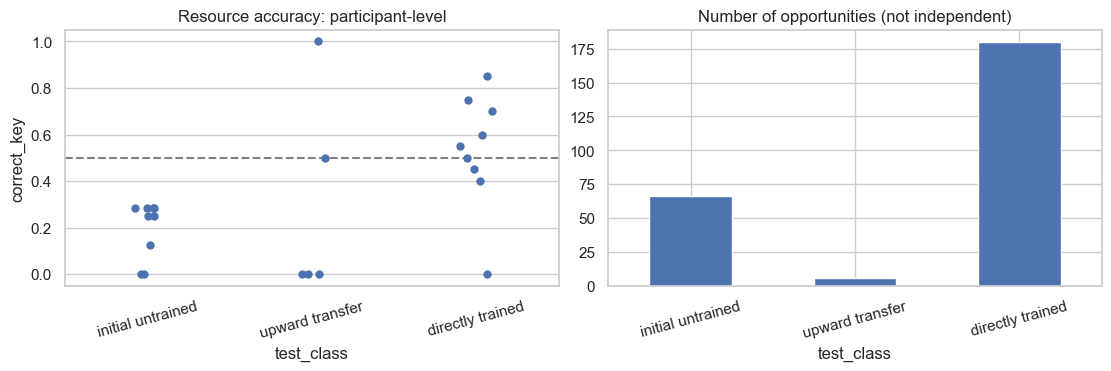

Transfer with any previously trained resource sibling: 6 / 6
No statistical claims from sparse first-transfer opportunities.


In [88]:
HISTORY['upward_resource']=HISTORY.family_name.eq('resource') & HISTORY.direct_resource.eq(0) & ((HISTORY.direct_gem+HISTORY.direct_gadget)>0)
HISTORY['initial_resource']=HISTORY.family_name.eq('resource') & HISTORY.direct_resource.eq(0) & ~HISTORY.upward_resource
HISTORY['trained_resource']=HISTORY.family_name.eq('resource') & HISTORY.direct_resource.gt(0)
HISTORY['test_class']=np.select([HISTORY.upward_resource,HISTORY.initial_resource,HISTORY.trained_resource],
                               ['upward transfer','initial untrained','directly trained'],default='other')
T=HISTORY[HISTORY.family_name.eq('resource')].copy()
transfer=T[T.upward_resource].copy()
print('Schedule-defined eligible upward-transfer events:',len(transfer))
display(transfer[['subject','phase','trial_type','alien','direct_gem','direct_gadget','partner_resource','correct_key']])
fig,axs=plt.subplots(1,2,figsize=(11,3.6),constrained_layout=True)
summ=T.groupby(['subject','test_class']).correct_key.mean().reset_index()
sns.stripplot(data=summ,x='test_class',y='correct_key',order=['initial untrained','upward transfer','directly trained'],ax=axs[0],size=6)
axs[0].axhline(.5,ls='--',c='gray');axs[0].tick_params(axis='x',rotation=15);axs[0].set_title('Resource accuracy: participant-level')
T.test_class.value_counts().reindex(['initial untrained','upward transfer','directly trained'],fill_value=0).plot.bar(ax=axs[1])
axs[1].tick_params(axis='x',rotation=15);axs[1].set_title('Number of opportunities (not independent)')
plt.show()
# Informative upstream evidence should be audited separately, not inferred from outcome labels.
print('Transfer with any previously trained resource sibling:',int((transfer.partner_resource>0).sum()),'/',len(transfer))
print('No statistical claims from sparse first-transfer opportunities.')

## 5 · Explicit grouping across five checkpoints
Look separately at gem siblings, resource-sharing non-siblings, and cross-resource pairs. All-separate grouping is shown as a benchmark, not evidence of correctly learned hierarchy.

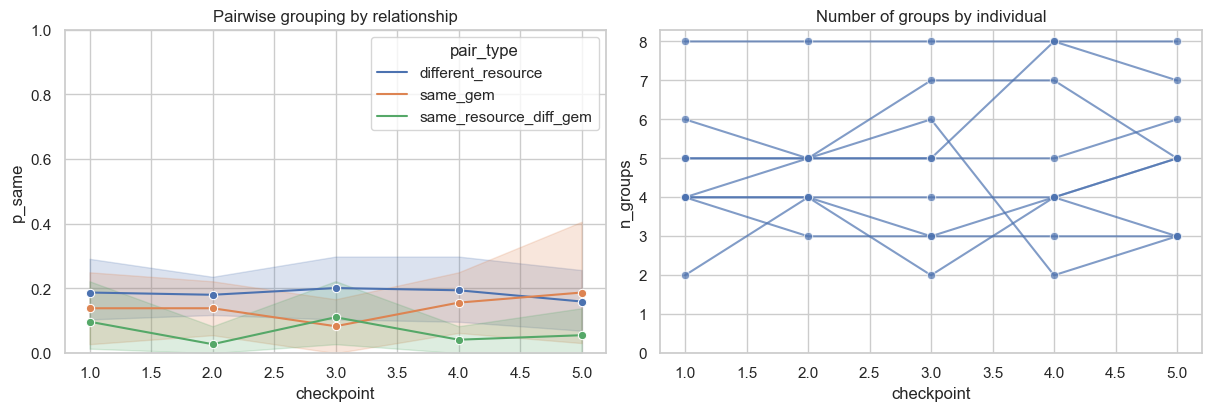

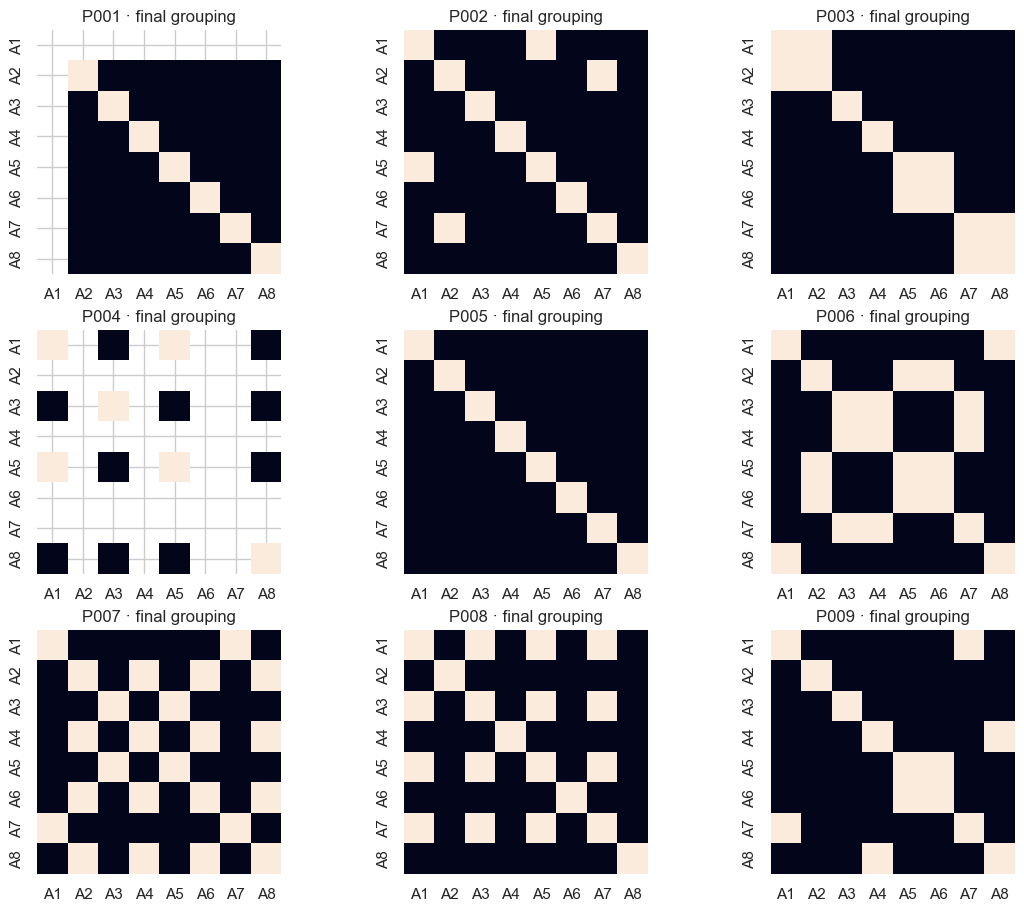

In [89]:
fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
sns.lineplot(data=PAIRWISE_PROFILE,x='checkpoint',y='p_same',hue='pair_type',marker='o',ax=axs[0],errorbar=('ci',95))
axs[0].set_ylim(0,1);axs[0].set_title('Pairwise grouping by relationship')
sns.lineplot(data=GROUPING_SUMMARY,x='checkpoint',y='n_groups',units='subject',estimator=None,marker='o',alpha=.7,ax=axs[1])
axs[1].set_title('Number of groups by individual');axs[1].set_ylim(0,8.3)
plt.show()
final_cp=GROUPINGS.checkpoint.max()
sids=sorted(GROUPINGS.subject.dropna().unique()); nc=3;nr=int(np.ceil(len(sids)/nc))
fig,axs=plt.subplots(nr,nc,figsize=(11,3*nr),constrained_layout=True);axs=np.asarray(axs).ravel()
for ax,sid in zip(axs,sids):
    d=GROUPINGS[(GROUPINGS.subject==sid)&(GROUPINGS.checkpoint==final_cp)]
    pos=dict(zip(d.alien,d.box));matrix=np.full((8,8),np.nan)
    for i,a in enumerate(ALIENS):
        for j,b in enumerate(ALIENS):
            if a in pos and b in pos:matrix[i,j]=float(pos[a]==pos[b])
    sns.heatmap(matrix,vmin=0,vmax=1,cbar=False,xticklabels=ALIENS,yticklabels=ALIENS,ax=ax,square=True)
    ax.set_title(f'{sid} · final grouping')
for ax in axs[len(sids):]:ax.axis('off')
plt.show()

## 6 · Reward → alien set probes
Accuracy must be evaluated relative to each target-set size (4, 2, or 1). Plot both set-size error and identity accuracy; expected random overlap conditions on the number of selections.

In [90]:
# ============================================================
# REWARD -> ALIEN SET PROBE
# ============================================================

gt=raw[raw.Display=="grouping_trial"].copy()

def parse_answer(x):
    return set(re.findall(r"A\d+",str(x)))

rows=[]
for (sid,tr),d in gt.groupby(["subject","Trial Number"]):
    d=d.sort_values("event")
    clicks=d.loc[d["Response Type"].eq("response"),"Response"].dropna()
    clicks=[re.search(r"A\d+",x).group() for x in clicks if re.search(r"A\d+",x)]

    # clicks toggle selection
    selected=set()
    for a in clicks:
        selected.remove(a) if a in selected else selected.add(a)

    r=d.iloc[0]
    target=parse_answer(r["Spreadsheet: answer"])
    reward=r.get("Spreadsheet: reward_name",np.nan)

    inter=len(selected&target); union=len(selected|target)
    rows.append(dict(
        subject=sid,trial=int(tr),reward=reward,
        level={4:"resource",2:"gem",1:"gift"}.get(len(target),"other"),
        target=tuple(sorted(target)),selected=tuple(sorted(selected)),
        n_target=len(target),n_selected=len(selected),
        exact=int(selected==target),
        precision=inter/len(selected) if selected else np.nan,
        recall=inter/len(target) if target else np.nan,
        jaccard=inter/union if union else 1,
        false_positive=len(selected-target),
        missed=len(target-selected)
    ))

SET_PROBES=pd.DataFrame(rows)
display(SET_PROBES.head(12))

,subject,trial,reward,level,target,selected,n_target,n_selected,exact,precision,recall,jaccard,false_positive,missed
0,P001,1,Opal,gem,"(A3, A4)","(A2,)",2,1,0,0.000000,0.00,0.000000,1,2
1,P001,2,Gravity Boots,gift,"(A5,)","(A4,)",1,1,0,0.000000,0.00,0.000000,1,1
2,P001,3,Shelter,resource,"(A5, A6, A7, A8)","(A4,)",4,1,0,0.000000,0.00,0.000000,1,4
3,P001,4,Food,resource,"(A1, A2, A3, A4)","(A2, A6, A8)",4,3,0,0.333333,0.25,0.166667,2,3
4,P001,5,Universal Translator,gift,"(A6,)","(A8,)",1,1,0,0.000000,0.00,0.000000,1,1
5,P001,6,Rubies,gem,"(A5, A6)","(A4, A5)",2,2,0,0.500000,0.50,0.333333,1,1
6,P001,7,Diamonds,gem,"(A7, A8)","(A7,)",2,1,0,1.000000,0.50,0.500000,0,1
7,P001,8,Gold,gem,"(A1, A2)","(A6, A8)",2,2,0,0.000000,0.00,0.000000,2,2
8,P002,1,Gold,gem,"(A1, A2)","(A2,)",2,1,0,1.000000,0.50,0.500000,0,1
9,P002,2,Rubies,gem,"(A5, A6)","(A5,)",2,1,0,1.000000,0.50,0.500000,0,1


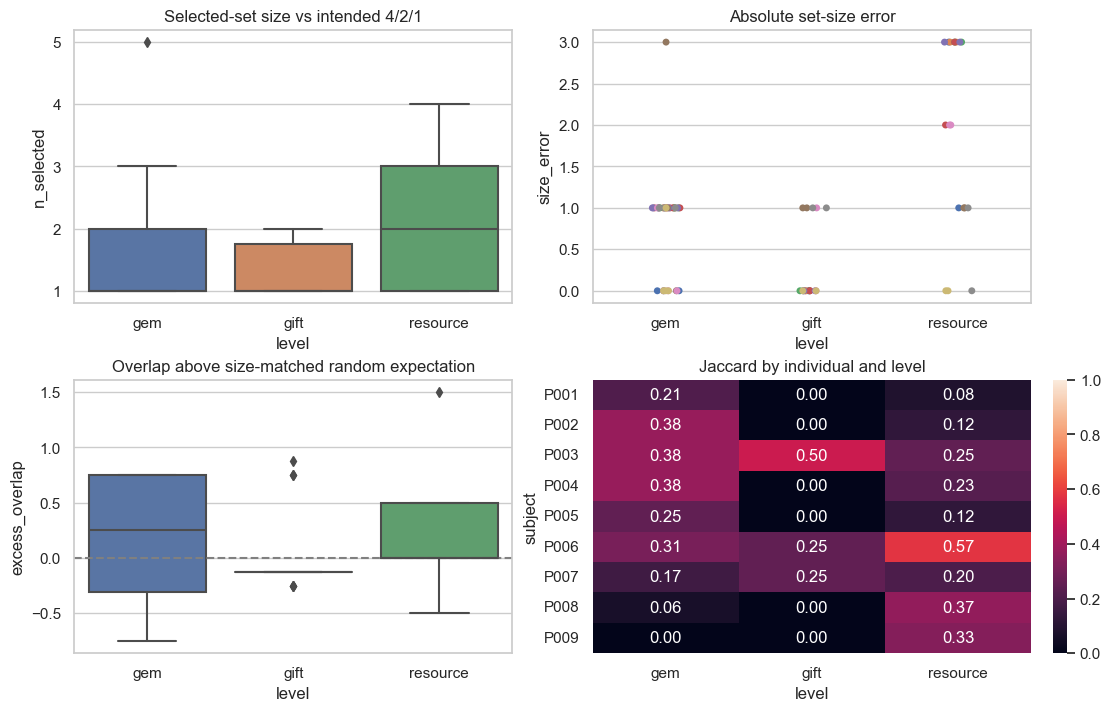

In [91]:
SET_PROBES['size_error']=(SET_PROBES.n_selected-SET_PROBES.n_target).abs()
SET_PROBES['overlap']=(SET_PROBES.n_target-SET_PROBES.missed)
SET_PROBES['expected_overlap']=SET_PROBES.n_target*SET_PROBES.n_selected/8
SET_PROBES['excess_overlap']=SET_PROBES.overlap-SET_PROBES.expected_overlap
fig,axs=plt.subplots(2,2,figsize=(11,7),constrained_layout=True)
sns.boxplot(data=SET_PROBES,x='level',y='n_selected',ax=axs[0,0]);axs[0,0].set_title('Selected-set size vs intended 4/2/1')
sns.stripplot(data=SET_PROBES,x='level',y='size_error',hue='subject',legend=False,ax=axs[0,1]);axs[0,1].set_title('Absolute set-size error')
sns.boxplot(data=SET_PROBES,x='level',y='excess_overlap',ax=axs[1,0]);axs[1,0].axhline(0,ls='--',c='gray');axs[1,0].set_title('Overlap above size-matched random expectation')
sns.heatmap(SET_PROBES.groupby(['subject','level']).jaccard.mean().unstack(),annot=True,fmt='.2f',vmin=0,vmax=1,ax=axs[1,1]);axs[1,1].set_title('Jaccard by individual and level')
plt.show()

## 7 · Multi-outcome probe diagnostics
Distinguish selecting the correct outcome *panels* from selecting the correct *keys*.

In [92]:
# ============================================================
# MULTI-PROBE ERROR DECOMPOSITION
# ============================================================

PANEL_FAMILY={"Left":"resource","Right":"gem","Down":"gift"}
TOK=re.compile(r"Left|Right|Down|[ASDFHJKL]")

def parse_multi(x):
    t=TOK.findall(str(x))
    if len(t)!=4: return None
    return [(t[0],t[1]),(t[2],t[3])]

mp=raw[(raw.Display=="rt_probes_multi")&
       (raw["Response Type"]=="response")].copy()

rows=[]
for _,r in mp.iterrows():
    ans=parse_multi(r["Spreadsheet: answer"])
    rsp=parse_multi(r.Response)
    if ans is None or rsp is None: continue

    amap=dict(ans) if len({p for p,k in ans})==2 else {}
    rmap=dict(rsp) if len({p for p,k in rsp})==2 else {}

    target_panels=set(amap)
    chosen_panels=set(rmap)

    n_panel=len(target_panels&chosen_panels)
    n_pair=len(set(ans)&set(rsp))
    correct_panels=(target_panels==chosen_panels)
    exact=(set(ans)==set(rsp))

    if exact:
        err="Exact"
    elif correct_panels:
        wrong=sum(rmap[p]!=amap[p] for p in target_panels)
        err=f"Correct panels, {wrong} wrong key"+("" if wrong==1 else "s")
    elif n_panel==1:
        err="Only 1 correct panel"
    else:
        err="Wrong panels"

    rows.append(dict(
        subject=r.subject,trial=int(r["Trial Number"]),
        alien=r["Spreadsheet: alien_stim"],
        answer=r["Spreadsheet: answer"],response=r.Response,
        relation="+".join(sorted(PANEL_FAMILY[p] for p in target_panels)),
        exact=int(exact),
        correct_panel_pair=int(correct_panels),
        n_correct_panels=n_panel,
        n_correct_panel_keys=n_pair,
        error_type=err,
        rt_s=pd.to_numeric(r["Reaction Time"],errors="coerce")/1000
    ))

MULTI_DETAIL=pd.DataFrame(rows)
display(MULTI_DETAIL)

,subject,trial,alien,answer,response,relation,exact,correct_panel_pair,n_correct_panels,n_correct_panel_keys,error_type,rt_s
0,P001,1,A2.png,RightSDownS,LeftADownA,gem+gift,0,0,1,0,Only 1 correct panel,22.7890
1,P001,2,A7.png,LeftHRightL,RightLDownK,gem+resource,0,0,1,1,Only 1 correct panel,22.1681
2,P001,3,A5.png,LeftHRightJ,RightJDownH,gem+resource,0,0,1,1,Only 1 correct panel,17.7776
3,P001,4,A6.png,RightJDownJ,RightJDownJ,gem+gift,1,1,2,2,Exact,20.6803
4,P001,5,A4.png,LeftADownF,LeftFDownF,gift+resource,0,1,2,1,"Correct panels, 1 wrong key",18.7125
...,...,...,...,...,...,...,...,...,...,...,...,...
204,P009,20,A4.png,RightFDownF,RightKDownH,gem+gift,0,1,2,0,"Correct panels, 2 wrong keys",11.4499
205,P009,21,A1.png,RightSDownA,RightSDownS,gem+gift,0,1,2,1,"Correct panels, 1 wrong key",11.0148
206,P009,22,A1.png,LeftARightS,LeftARightS,gem+resource,1,1,2,2,Exact,3.2065
207,P009,23,A4.png,LeftARightF,LeftARightK,gem+resource,0,1,2,1,"Correct panels, 1 wrong key",6.3810


In [93]:
MULTI_SUMMARY=(MULTI_DETAIL.groupby("subject")
    .agg(
        exact=("exact","mean"),
        correct_panels=("correct_panel_pair","mean"),
        mean_correct_panel_keys=("n_correct_panel_keys","mean"),
        median_rt=("rt_s","median")
    ).reset_index())

display(MULTI_SUMMARY.round(3))

,subject,exact,correct_panels,mean_correct_panel_keys,median_rt
0,P001,0.333,0.500,1.083,12.885
1,P002,0.583,0.792,1.583,7.850
2,P003,0.000,0.167,0.292,2.859
3,P004,0.250,0.375,1.125,4.578
4,P005,0.000,0.125,0.125,0.309
5,P006,0.500,1.000,1.455,9.061
6,P007,0.708,0.875,1.583,6.505
7,P008,0.158,0.895,0.842,17.353
8,P009,0.458,0.917,1.375,6.094


In [94]:
# Correct-key rate conditional on the panel actually being chosen (component-level).
# This differs from the strict conjunction 'both keys correct' score.
def component_keys(x):
    parsed=parse_multi(x)
    return dict(parsed) if parsed and len(set(p for p,k in parsed))==2 else {}
component=[]
for _,r in mp.iterrows():
    target=component_keys(r['Spreadsheet: answer']);selected=component_keys(r.Response)
    if not target or not selected: continue
    for panel,true_key in target.items():
        if panel in selected:
            component.append(dict(subject=r.subject,panel=panel,correct=int(selected[panel]==true_key)))
COMPONENT_ACCURACY=pd.DataFrame(component)
if len(COMPONENT_ACCURACY):display(COMPONENT_ACCURACY.groupby(['subject','panel']).correct.agg(['mean','size']))
print('Multi responses parsed:',len(MULTI_DETAIL),'of',len(mp))

mean  size
subject panel                
P001    Down   0.642857    14
        Left   0.700000    10
        Right  0.909091    11
P002    Down   0.545455    11
        Left   1.000000    15
        Right  1.000000    16
P003    Down   0.000000     1
        Left   0.181818    11
        Right  0.384615    13
P004    Down   1.000000     1
        Left   0.812500    16
        Right  0.700000    10
P005    Down   0.000000     1
        Left   0.200000    10
        Right  0.125000     8
P006    Down   0.666667    15
        Left   0.500000    14
        Right  1.000000    15
P007    Down   0.692308    13
        Left   0.937500    16
        Right  0.933333    15
P008    Down   0.300000    10
        Left   0.769231    13
        Right  0.230769    13
P009    Down   0.333333    15
        Left   1.000000    16
        Right  0.800000    15

Multi responses parsed: 209 of 209


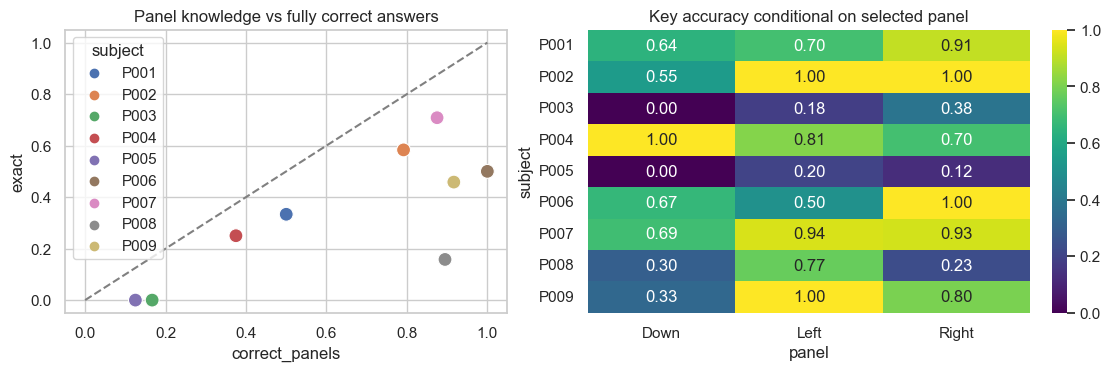

In [95]:
fig,axs=plt.subplots(1,2,figsize=(11,3.6),constrained_layout=True)
sns.scatterplot(data=MULTI_SUMMARY,x='correct_panels',y='exact',hue='subject',s=100,ax=axs[0]);axs[0].plot([0,1],[0,1],'--',color='gray');axs[0].set_title('Panel knowledge vs fully correct answers')
if len(COMPONENT_ACCURACY):
    cc=COMPONENT_ACCURACY.groupby(['subject','panel']).correct.mean().unstack()
    sns.heatmap(cc,annot=True,fmt='.2f',cmap='viridis',vmin=0,vmax=1,ax=axs[1]);axs[1].set_title('Key accuracy conditional on selected panel')
plt.show()

## 8 · Probe signatures not captured by simple accuracy
**Practice:** 3 compound-response trials verify interface fluency. **Combination geometry:** compare resource+gem, resource+gadget, gem+gadget while preserving component-level scores. **Response behavior:** detect omissions and implausibly fast submissions instead of silently excluding anyone.

,practice_n,practice_accuracy,practice_rt
subject,,,
P001,3,0.667,5.398
P002,3,0.000,9.728
P003,3,0.333,7.906
P004,3,0.333,10.144
P005,3,0.333,10.863
P006,3,1.000,4.168
P007,3,0.667,7.035
P008,3,0.667,10.857
P009,3,1.000,4.938


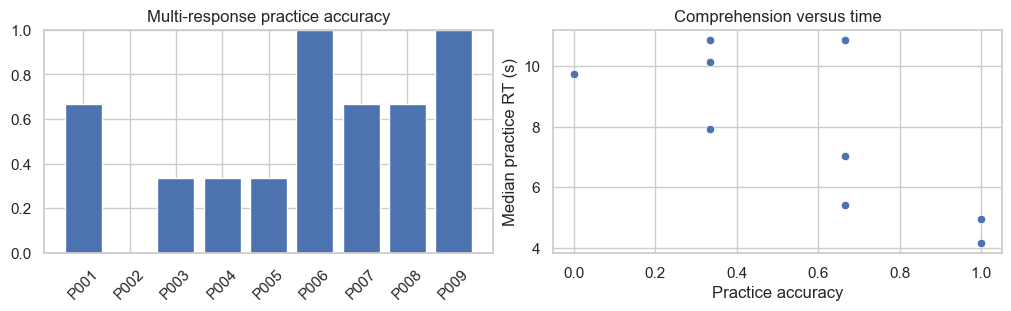

,subject,relation,n,exact,correct_panels,n_key_pairs,median_rt
0,P001,gem+gift,8,0.625,0.750,1.250,13.963
1,P001,gem+resource,8,0.375,0.375,1.250,12.676
2,P001,gift+resource,8,0.000,0.375,0.750,12.885
3,P002,gem+gift,8,0.625,1.000,1.625,13.173
4,P002,gem+resource,8,1.000,1.000,2.000,4.700
5,P002,gift+resource,8,0.125,0.375,1.125,6.754
6,P003,gem+gift,8,0.000,0.000,0.250,4.949
7,P003,gem+resource,8,0.000,0.500,0.500,2.570
8,P003,gift+resource,8,0.000,0.000,0.125,2.473
9,P004,gem+gift,8,0.000,0.125,0.875,5.650


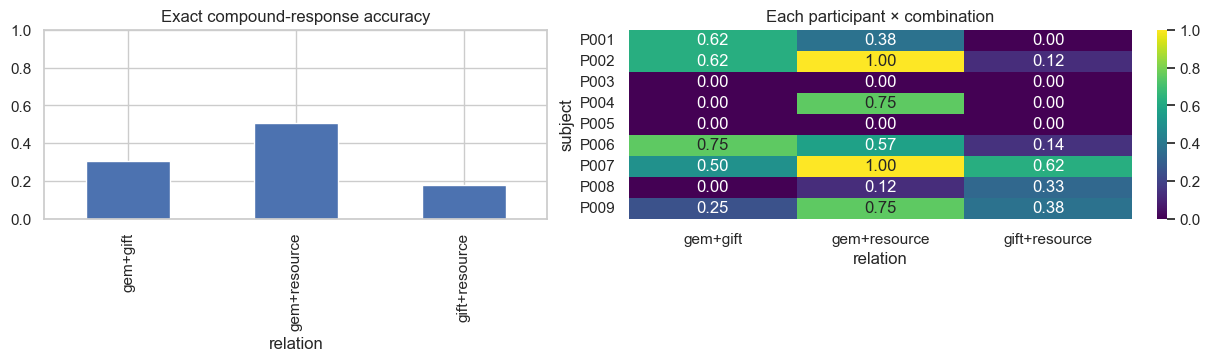

Multi-response sample sizes by subject:


,n,exact,median_rt
subject,,,
P001,24,0.333333,12.88480
P002,24,0.583333,7.85005
P003,24,0.000000,2.85865
P004,24,0.250000,4.57760
P005,24,0.000000,0.30894
P006,22,0.500000,9.06145
P007,24,0.708333,6.50506
P008,19,0.157895,17.35320
P009,24,0.458333,6.09445


,n,median,below_250ms,below_500ms
subject,,,,
P001,134,4.11160,0,0
P002,134,3.02140,0,0
P003,134,4.24425,0,1
P004,134,2.50485,0,0
P005,134,2.44503,4,20
P006,132,3.17030,0,0
P007,134,1.73760,0,13
P008,126,4.29246,1,1
P009,134,3.00390,0,0


In [96]:
# Compound-response practice: include both exact match and RT; outcomes reflect raw Gorilla scoring.
practice=raw[(raw.Display=='multi_practice_trial') & raw['Response Type'].eq('response') & raw.subject.notna()].copy()
practice['correct_exact']=(practice.Response.astype('string').str.strip().str.upper()==
                            practice['Spreadsheet: answer'].astype('string').str.strip().str.upper()).astype(int)
PRACTICE=practice[['subject','Trial Number','Response','Spreadsheet: answer','correct_exact','rt_s']].copy()
PS=PRACTICE.groupby('subject').agg(practice_n=('correct_exact','size'),practice_accuracy=('correct_exact','mean'),practice_rt=('rt_s','median'))
display(PS.round(3))
fig,axs=plt.subplots(1,2,figsize=(10,3),constrained_layout=True)
axs[0].bar(PS.index.astype(str),PS.practice_accuracy);axs[0].set(ylim=(0,1),title='Multi-response practice accuracy');axs[0].tick_params(axis='x',rotation=45)
sns.scatterplot(x=PS.practice_accuracy,y=PS.practice_rt,ax=axs[1]);axs[1].set(xlabel='Practice accuracy',ylabel='Median practice RT (s)',title='Comprehension versus time');plt.show()

# Compound question signatures by combination of attribute levels.
COMPONENTS=(MULTI_DETAIL.groupby(['subject','relation']).agg(n=('exact','size'),exact=('exact','mean'),
                 correct_panels=('correct_panel_pair','mean'),n_key_pairs=('n_correct_panel_keys','mean'),
                 median_rt=('rt_s','median')).reset_index())
display(COMPONENTS.round(3))
fig,axs=plt.subplots(1,2,figsize=(12,3.5),constrained_layout=True)
COMPONENTS.groupby('relation').exact.mean().plot.bar(ax=axs[0]);axs[0].set(ylim=(0,1),title='Exact compound-response accuracy')
sns.heatmap(COMPONENTS.pivot(index='subject',columns='relation',values='exact'),
            annot=True,fmt='.2f',vmin=0,vmax=1,cmap='viridis',ax=axs[1]);axs[1].set_title('Each participant × combination');plt.show()

# Component-level conditional accuracy, with denominators; distinguish 1/1 from 15/15.
CP=MULTI_DETAIL.copy()
print('Multi-response sample sizes by subject:')
display(CP.groupby('subject').agg(n=('exact','size'),exact=('exact','mean'),median_rt=('rt_s','median')))
# RT screen: flag, do not exclude automatically; this is an event log, so confirm display semantics.
RT_FLAGS=(TRIALS.groupby('subject').agg(n=('rt_s','count'),median=('rt_s','median'),
                below_250ms=('rt_s',lambda x:int((x<.25).sum())),
                below_500ms=('rt_s',lambda x:int((x<.5).sum()))))
display(RT_FLAGS)

## 9 · Reward grouping as an independent representational readout
Reconstruct the **last recorded reward location** from dragging events when available. Classify reward pairs by their actual level (resources, gems, unique gadgets); compare against alien-pair grouping at the last checkpoint. Missing placements remain missing. Inspect raw events if fewer than the expected 14 reward items are recovered.

In [97]:
# The reward grouping display uses 14 drag objects (2 resources, 4 gems, 8 gadgets).
rg=raw[(raw.Display=='reward_grouping') & raw.subject.notna()].copy()
print('Reward grouping response examples:')
display(rg[rg['Response Type'].eq('response')][['subject','Trial Number','Response','Tag','Component Name']].head(12))

# Support filename-based entries and group-box suffixes without inferring grouping from display position.
import re
pat=re.compile(r'(?P<item>[^,; ]+\.png)H(?P<box>[1-8])',flags=re.IGNORECASE)
placements=[]
for r in rg[rg['Response Type'].eq('response')].itertuples(index=False):
    response=str(getattr(r,'Response'))
    for match in pat.finditer(response):
        placements.append((r.subject,int(r.event),match.group('item').lower(),int(match.group('box'))))
REWARD_PLACEMENTS=pd.DataFrame(placements,columns=['subject','event','item','box'])
if len(REWARD_PLACEMENTS):
    REWARD_PLACEMENTS=REWARD_PLACEMENTS.sort_values('event').drop_duplicates(['subject','item'],keep='last')
    display(REWARD_PLACEMENTS.groupby('subject').agg(n_items=('item','nunique'),n_groups=('box','nunique')))
    reward_defs=SCHEDULES['pilot'].loc[lambda d:d.display.eq('reward_grouping')]
    named_cols=['alien_stim','alien_stim2','alien_stim3','alien_stim4','alien_item','alien_item_8',
                'alien_item_2','alien_item_3','alien_item_4','alien_item_5','alien_item_6','alien_item_7',
                'reward','secondary_reward']
    files=set(str(v).lower() for v in reward_defs.reindex(columns=named_cols).values.ravel() if pd.notna(v) and str(v).endswith('.png'))
    print('Expected reward assets:',len(files),'observed:',REWARD_PLACEMENTS.item.nunique())
else:
    print('Drag response syntax differs from expected <asset>.pngH<box>; inspect raw responses before scoring.')

Reward grouping response examples:


,subject,Trial Number,Response,Tag,Component Name
452,P001,1.0,ruby.pngH1,NaN,Draggable
453,P001,1.0,opal.pngH5,NaN,Draggable
454,P001,1.0,food.pngH2,NaN,Draggable
455,P001,1.0,shelter.pngH6,NaN,Draggable
456,P001,1.0,diamond.pngH3,NaN,Draggable
457,P001,1.0,gravity_boots.pngH7,NaN,Draggable
458,P001,1.0,universal_translator.pngH4,NaN,Draggable
459,P001,1.0,memory_crystal.pngH8,NaN,Draggable
460,P001,1.0,gold.pngH8,NaN,Draggable
903,P002,1.0,food.pngH4,NaN,Draggable


,n_items,n_groups
subject,,
P001,9,8
P002,14,3
P003,14,3
P004,14,3
P005,14,8
P006,14,6
P007,14,8
P008,14,3
P009,14,8


Expected reward assets: 14 observed: 14


## 10 · Isolated behavioral signatures, uncertainty, and convergence
All signatures are subject-level and explicitly carry denominators. Correlations across nine participants are descriptive, potentially influenced by shared response demands; **do not** interpret them as independent model-identification evidence. Pairwise-complete correlations display N.

,learn_resource,n_learn_resource,learn_gem,n_learn_gem,learn_gadget,n_learn_gadget,gem_cohesion,resource_cohesion,cross_resource_merge,set_resource_jaccard,set_gem_jaccard,set_gift_jaccard,set_size_abs_error,multi_exact,multi_panel_selection,multi_correct_components,practice_accuracy,median_rt,transfer_correct,n_transfer
subject,,,,,,,,,,,,,,,,,,,,
P001,0.50,20,0.476,42,0.542,24,0.00,0.00,0.000,0.083,0.208,0.00,0.750,0.333,0.500,0.542,0.667,4.112,1.0,1
P002,0.45,20,0.429,42,0.083,24,0.00,0.00,0.125,0.125,0.375,0.00,1.250,0.583,0.792,0.792,0.000,3.021,NaN,0
P003,0.30,20,0.452,42,0.167,24,0.75,0.00,0.000,0.250,0.375,0.50,1.250,0.000,0.167,0.146,0.333,4.244,0.0,1
P004,0.45,20,0.262,42,0.125,24,NaN,0.00,0.250,0.225,0.375,0.00,1.125,0.250,0.375,0.562,0.333,2.505,0.0,1
P005,0.05,20,0.262,42,0.167,24,0.00,0.00,0.000,0.125,0.250,0.00,1.250,0.000,0.125,0.062,0.333,2.445,NaN,0
P006,0.50,20,0.500,42,0.208,24,0.50,0.00,0.312,0.575,0.308,0.25,1.125,0.500,1.000,0.727,1.000,3.170,0.0,1
P007,0.15,20,0.286,42,0.083,24,0.00,0.25,0.375,0.200,0.167,0.25,0.750,0.708,0.875,0.792,0.667,1.738,0.5,2
P008,0.40,20,0.333,42,0.250,24,0.00,0.25,0.250,0.367,0.062,0.00,0.750,0.158,0.895,0.421,0.667,4.292,NaN,0
P009,0.40,20,0.143,42,0.083,24,0.25,0.00,0.125,0.333,0.000,0.00,0.125,0.458,0.917,0.688,1.000,3.004,NaN,0


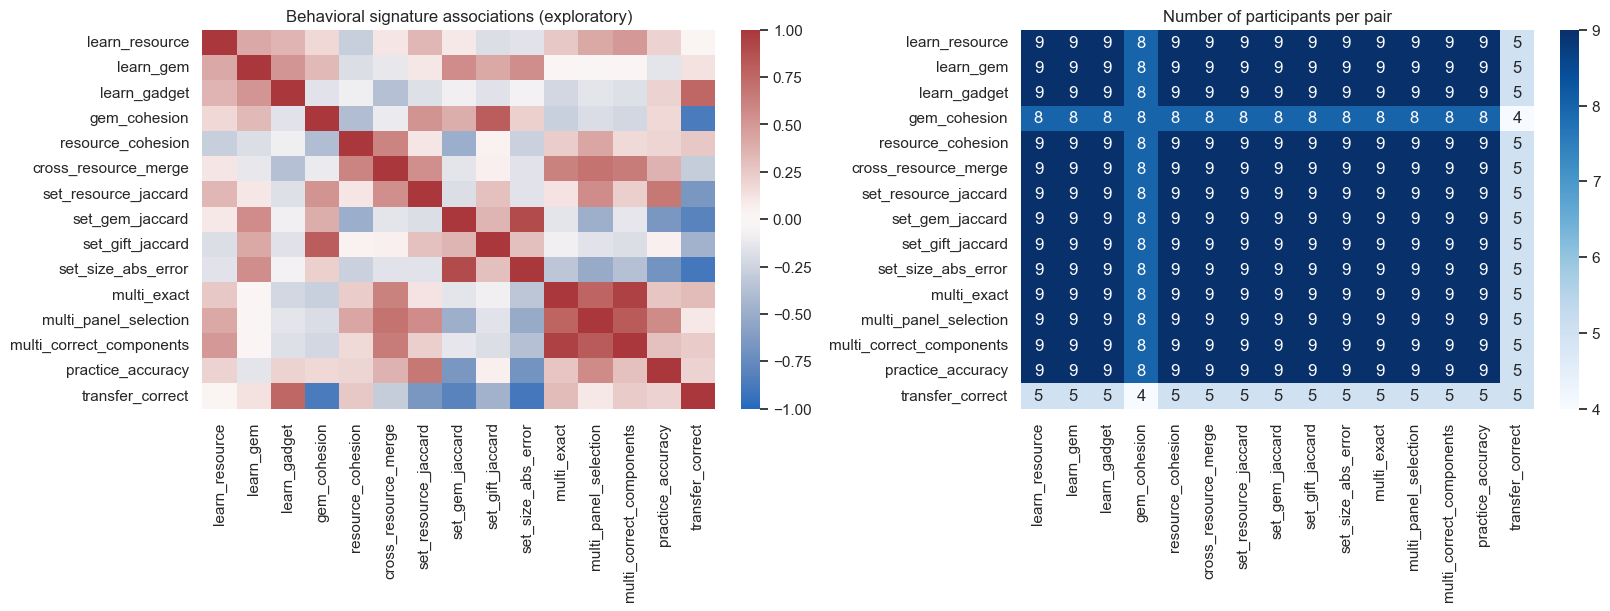

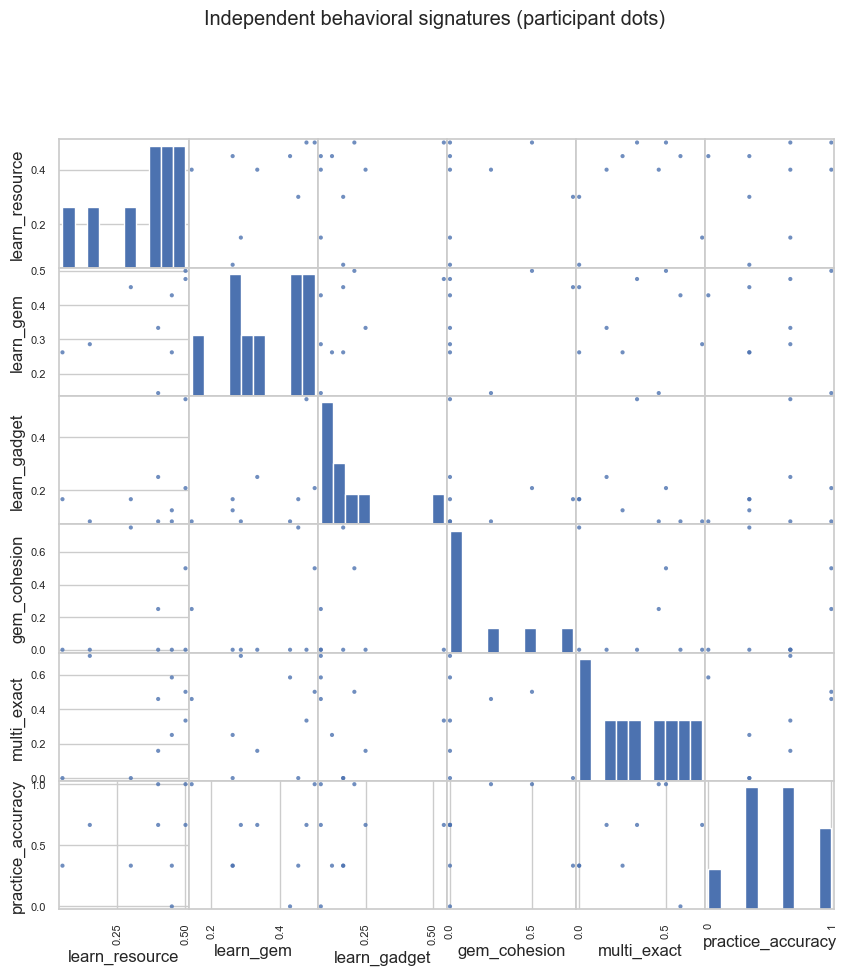

In [98]:
# Subject-level signature matrix; each component kept distinct instead of one overall accuracy.
SIGNATURES=PARTICIPANTS[['subject']].drop_duplicates().set_index('subject')
fam=LEARN_H.groupby(['subject','family_name']).correct_key.agg(['mean','size'])
for f in ['resource','gem','gadget']:
    if f in fam.index.get_level_values('family_name'):
        SIGNATURES[f'learn_{f}']=fam.xs(f,level='family_name')['mean']
        SIGNATURES[f'n_learn_{f}']=fam.xs(f,level='family_name')['size']
for rel,label in [('same_gem','gem_cohesion'),('same_resource_diff_gem','resource_cohesion'),
                  ('different_resource','cross_resource_merge')]:
    part=PAIRWISE_PROFILE[(PAIRWISE_PROFILE.checkpoint==PAIRWISE_PROFILE.checkpoint.max()) &
                          PAIRWISE_PROFILE.pair_type.eq(rel)]
    SIGNATURES[label]=part.set_index('subject').p_same
if len(SET_PROBES):
    for lvl in ['resource','gem','gift']:
        q=SET_PROBES[SET_PROBES.level.eq(lvl)]
        SIGNATURES[f'set_{lvl}_jaccard']=q.groupby('subject').jaccard.mean()
    SIGNATURES['set_size_abs_error']=SET_PROBES.assign(err=lambda d:(d.n_selected-d.n_target).abs()).groupby('subject').err.mean()
if len(MULTI_DETAIL):
    mg=MULTI_DETAIL.groupby('subject')
    SIGNATURES['multi_exact']=mg.exact.mean()
    SIGNATURES['multi_panel_selection']=mg.correct_panel_pair.mean()
    SIGNATURES['multi_correct_components']=mg.n_correct_panel_keys.mean()/2
SIGNATURES['practice_accuracy']=PS.practice_accuracy
SIGNATURES['median_rt']=TRIALS.groupby('subject').rt_s.median()
SIGNATURES['transfer_correct']=transfer.groupby('subject').correct_key.mean()
SIGNATURES['n_transfer']=transfer.groupby('subject').correct_key.size().fillna(0)
SIGNATURES['n_transfer']=SIGNATURES.n_transfer.fillna(0).astype(int)
display(SIGNATURES.round(3))

# Correlation N is crucial: transfer may exist for only a handful of subjects.
variables=[c for c in SIGNATURES if c not in ['median_rt','n_transfer'] and not c.startswith('n_learn_')]
X=SIGNATURES[variables].apply(pd.to_numeric,errors='coerce')
cor=X.corr(min_periods=4); n_pair=X.notna().astype(int).T.dot(X.notna().astype(int))
fig,axs=plt.subplots(1,2,figsize=(16,6),constrained_layout=True)
sns.heatmap(cor,cmap='vlag',vmin=-1,vmax=1,center=0,ax=axs[0]);axs[0].set_title('Behavioral signature associations (exploratory)')
sns.heatmap(n_pair,annot=True,fmt='d',cmap='Blues',ax=axs[1]);axs[1].set_title('Number of participants per pair')
plt.show()
# Pairwise scatter matrix for a small interpretable subset.
core=[c for c in ['learn_resource','learn_gem','learn_gadget','gem_cohesion','multi_exact','practice_accuracy'] if c in X]
if len(core)>1:
    pd.plotting.scatter_matrix(X[core],figsize=(10,10),diagonal='hist',alpha=.8)
    plt.suptitle('Independent behavioral signatures (participant dots)',y=1.01);plt.show()

## 12 · HOLMES: focused α × ρ fit (optional)
Fix ω, κ, decision rule, and depth decay

In [ ]:
FIXED_DECAY = 0.0
BETA, LAPSE = 1.0, 0.02
MODEL_SEED = 13
N_PARTICLES = 10  # main fit; increase for publication-quality sensitivity

# Only alpha and rho are free in the focused fit; omega is fixed.
ALPHAS = np.array([0.06, 0.15, 0.35, 0.80, 1.60])
RHOS = np.array([0.0, 0.5, 0.85, 0.97])
FIXED_OMEGA = 0.6
GRID = list(product(ALPHAS, RHOS))

@dataclass(frozen=True)
class ModelParams:
    rho: float = 0.5
    kappa: float = 20.0
    max_depth: int = 5
    max_children: int = 5
    max_nodes: object = None
    def kwargs(self, alpha, omega, decay=FIXED_DECAY):
        return dict(alpha=float(alpha), omega=float(omega), depth_decay=float(decay),
                    rho=self.rho, kappa=self.kappa, max_depth=self.max_depth,
                    max_children=self.max_children, max_nodes=self.max_nodes)

DEFAULTS = ModelParams()

def response_probs(p, beta=BETA, lapse=LAPSE):
    p = np.clip(np.asarray(p, float), 1e-12, None)**beta
    p /= p.sum()
    return (1-lapse)*p + lapse/len(p)



In [108]:

# Switch on computationally heavy sections intentionally.

RUN_MODEL_FITS = True       # 20 grid points x each participant

RUN_REPRESENTATIONS = False  # choice-fit predictions + cross-task checks

RUN_ABLATIONS = False      # rho and depth sensitivity (expensive)

RUN_RECOVERY = False       # independent-seed simulation recovery (expensive)

RUN_PARTICLE_CHECK = False # repeated seeds / particle counts (expensive)

WEIGHT_SCHEME = 'original' # or 'unit'; assumptions are explicitly tested below


In [109]:
# Model wrapper, response mapping, and optional alternative sampling parameters.
def model_fit(task, alpha, omega, rho=.5, kappa=20., particles=N_PARTICLES, seed=MODEL_SEED, max_depth=5):
    return HOLMES.run_model(task['data'],FAMILY_SIZES,task['feedback_mask'],task['prediction_mask'],
        alpha=float(alpha),omega=float(omega),rho=float(rho),kappa=float(kappa),
        depth_decay=FIXED_DECAY,max_depth=max_depth,max_children=5,
        family_weights=task['family_weights'],n_particles=particles,random_seed=seed, max_nodes=100000)

def outcome_prediction(fit, task, t):
    return np.asarray(fit['pred_probs'][int(task['schedule'].iloc[t].query_family)][t],float)

def keyboard_prob(p, family, key, beta=BETA, lapse=LAPSE):
    # Eight response keys assumed possible. Invalid key gets lapse-only probability.
    p=np.clip(np.asarray(p,float),1e-12,1)**beta; p=p/p.sum()
    return max(lapse/8 + ((1-lapse)*p[KEYMAP[family][key]] if key in KEYMAP[family] else 0),1e-12)

def model_loglik(fit,task,beta=BETA,lapse=LAPSE):
    s=task['schedule']; values=[]
    for t,r in s.iterrows():
        values.append(np.log(keyboard_prob(outcome_prediction(fit,task,t),r.family_name,str(r.choice),beta,lapse)) if r.choice in KEYS else np.nan)
    return np.asarray(values)

Fitted P001 alpha=0.06 rho=0.00 loglik=-242.736
Fitted P001 alpha=0.06 rho=0.50 loglik=-176.090
Fitted P001 alpha=0.06 rho=0.85 loglik=-177.397
Fitted P001 alpha=0.06 rho=0.97 loglik=-188.868
Fitted P001 alpha=0.15 rho=0.00 loglik=-243.094
Fitted P001 alpha=0.15 rho=0.50 loglik=-179.992
Fitted P001 alpha=0.15 rho=0.85 loglik=-169.596
Fitted P001 alpha=0.15 rho=0.97 loglik=-186.499
Fitted P001 alpha=0.35 rho=0.00 loglik=-241.932
Fitted P001 alpha=0.35 rho=0.50 loglik=-166.355
Fitted P001 alpha=0.35 rho=0.85 loglik=-171.532
Fitted P001 alpha=0.35 rho=0.97 loglik=-186.415
Fitted P001 alpha=0.80 rho=0.00 loglik=-239.590
Fitted P001 alpha=0.80 rho=0.50 loglik=-163.905
Fitted P001 alpha=0.80 rho=0.85 loglik=-167.943
Fitted P001 alpha=0.80 rho=0.97 loglik=-185.306
Fitted P001 alpha=1.60 rho=0.00 loglik=-239.677
Fitted P001 alpha=1.60 rho=0.50 loglik=-163.400
Fitted P001 alpha=1.60 rho=0.85 loglik=-166.047
Fitted P001 alpha=1.60 rho=0.97 loglik=-184.494
Fitted P002 alpha=0.06 rho=0.00 loglik=-

,subject,alpha,rho,loglik,n_scored
0,P001,1.60,0.50,-163.400,110
1,P002,0.06,0.50,-221.244,110
2,P003,0.80,0.85,-251.739,110
3,P004,0.35,0.85,-185.687,110
4,P005,0.80,0.85,-335.859,110
5,P006,0.80,0.85,-200.044,110
6,P007,1.60,0.85,-188.155,110
7,P008,0.80,0.97,-245.234,107
8,P009,0.15,0.85,-236.022,110


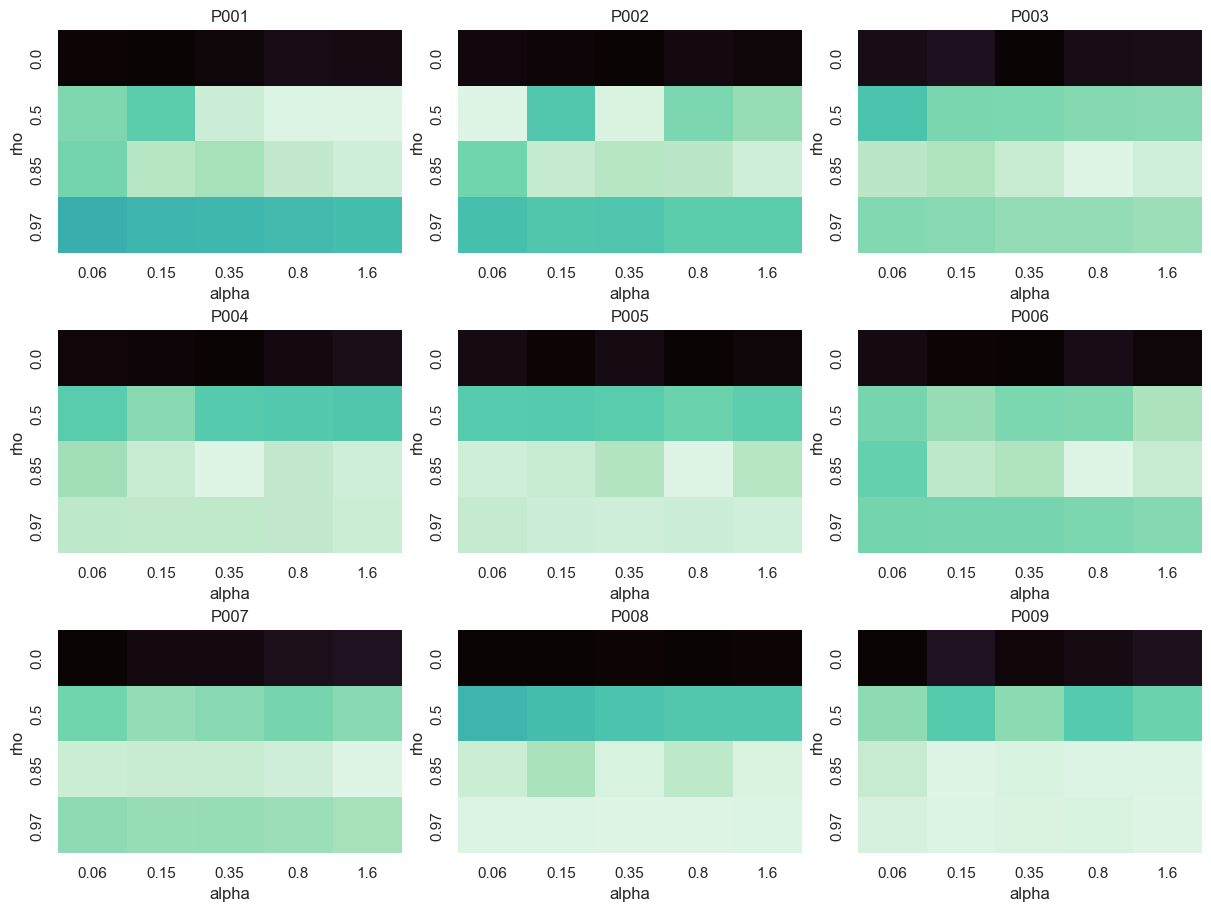

In [111]:
def fit_alpha_rho(sid):
    s,task=subject_task(sid); rows=[]
    for alpha,rho in GRID:
        fit=model_fit(task,alpha,FIXED_OMEGA,rho=rho)
        print(f"Fitted {sid} alpha={alpha:.2f} rho={rho:.2f} loglik={float(np.nansum(model_loglik(fit,task))):.3f}")
        ll=model_loglik(fit,task)
        rows.append(dict(subject=sid,alpha=alpha,rho=rho,
                         loglik=float(np.nansum(ll)),n_scored=int(np.isfinite(ll).sum())))
    return pd.DataFrame(rows)
if RUN_MODEL_FITS:
    SURFACES={sid:fit_alpha_rho(sid) for sid in sorted(TRIALS.subject.dropna().unique())}
    SURFACE=pd.concat(SURFACES.values(),ignore_index=True)
    FITS=SURFACE.loc[SURFACE.groupby('subject').loglik.idxmax()].reset_index(drop=True)
    display(FITS.round(3))
    fig,axs=plt.subplots(int(np.ceil(len(SURFACES)/3)),3,figsize=(12,3*int(np.ceil(len(SURFACES)/3))),constrained_layout=True)
    axs=np.asarray(axs).ravel()
    for ax,(sid,g) in zip(axs,SURFACES.items()):
        zz=g.pivot(index='rho',columns='alpha',values='loglik');sns.heatmap(zz,ax=ax,cmap='mako',cbar=False)
        ax.set_title(sid)
    for ax in axs[len(SURFACES):]:ax.axis('off')
    plt.show()

## 11 · Parameter identifiability through signatures, not likelihood alone
HOLMES fitting still varies only **α and ρ**; ω, κ and depth decay remain fixed. Fit learning choices and evaluate signatures independently. The optional simulation grid below asks which behavioral contrasts respond differently to α and ρ, and whether two settings produce practically indistinguishable signatures.

In [ ]:
# Mechanism-oriented observables: model end-state reach, predictions by outcome family,
# resource zero-shot predictions on the participant's actual schedule.
# These are descriptive model features, not a probabilistic observation model for grouping.
def model_signature(fit,task):
    s=task['schedule']; out={}
    for fam in ['resource','gem','gadget']:
        k=np.flatnonzero(s.family_name.eq(fam).to_numpy())
        out['p_correct_'+fam]=float(np.mean([outcome_prediction(fit,task,int(t))[int(s.iloc[t].true_value)]
                                               for t in k])) if len(k) else np.nan
    # At last training state, depth is reported as the fraction of particles at each level.
    pl=np.asarray(fit['path_lengths'])
    weights=np.asarray(fit['particle_weights'])
    final=pl[:,-1] if pl.ndim==2 else pl
    for level in [1,2,3,4]:
        out['reached_'+str(level)]=float(np.sum(weights*(final>=level)))
    return out

RUN_SIGNATURE_GRID = True  # Extra computational work beyond fitting.
if RUN_MODEL_FITS and RUN_SIGNATURE_GRID:
    rows=[]
    for sid in sorted(TRIALS.subject.dropna().unique()):
        s,task=subject_task(sid)
        for alpha,rho in GRID:
            fit=model_fit(task,alpha,FIXED_OMEGA,rho=rho)
            row=dict(subject=sid,alpha=alpha,rho=rho,**model_signature(fit,task))
            rows.append(row)
    MODEL_SIGNATURE_GRID=pd.DataFrame(rows)
    metric_cols=[c for c in MODEL_SIGNATURE_GRID if c.startswith(('p_correct_','reached_'))]
    fig,axs=plt.subplots(len(metric_cols),2,figsize=(10,2.5*len(metric_cols)),constrained_layout=True)
    for i,m in enumerate(metric_cols):
        zz=MODEL_SIGNATURE_GRID.groupby(['rho','alpha'])[m].mean().unstack()
        sns.heatmap(zz,ax=axs[i,0],cmap='viridis',annot=True,fmt='.2f');axs[i,0].set_title(m)
        vals=MODEL_SIGNATURE_GRID.groupby(['alpha','rho'])[m].mean()
        axs[i,1].hist(vals.dropna());axs[i,1].set_title(f'Grid-wide spread: {m}')
    plt.show()
    # Discriminability after scaling each signature to comparable units.
    cent=MODEL_SIGNATURE_GRID.groupby(['alpha','rho'])[metric_cols].mean().dropna()
    z=(cent-cent.mean())/cent.std(ddof=0).replace(0,np.nan)
    dist=np.sqrt(((z.to_numpy()[:,None,:]-z.to_numpy()[None,:,:])**2).sum(axis=2))
    upper=dist[np.triu_indices_from(dist,k=1)]
    print('Parameter-pair separability (standardized Euclidean; descriptive):')
    print(pd.Series(upper).describe().round(3))
else:
    print('Optional model signature grid not executed; set RUN_MODEL_FITS and RUN_SIGNATURE_GRID to True.')

## 13 · Model-predicted trajectories and transfer (optional)
Compare humans with the **response-transformed predicted correctness** as well as the latent correct-category probability. These are not interchangeable. For true transfer, evaluate the prediction before the first direct resource feedback.

In [103]:
if RUN_MODEL_FITS:
    predictions=[]
    for r in FITS.itertuples():
        s,task=subject_task(r.subject);f=model_fit(task,r.alpha,FIXED_OMEGA,rho=r.rho)
        hh=HISTORY[HISTORY.subject==r.subject].reset_index(drop=True)
        for t,row in s.iterrows():
            p=outcome_prediction(f,task,t);fam=row.family_name
            true_key=next(k for k,v in KEYMAP[fam].items() if v==row.true_value)
            predictions.append(dict(subject=r.subject,trial=t,family=fam,direct=int(hh.iloc[t].direct),
                class_transfer=bool(hh.iloc[t].upward_resource),
                human=int(hh.iloc[t].correct_key),latent_p=float(p[row.true_value]),
                response_p=keyboard_prob(p,fam,true_key)))
    PRED=pd.DataFrame(predictions)
    fig,axs=plt.subplots(1,3,figsize=(12,3.5),constrained_layout=True)
    for ax,f in zip(axs,CHANCE):
        d=PRED[PRED.family==f].groupby('direct')[['human','response_p','latent_p']].mean()
        d.plot(ax=ax,marker='o');ax.axhline(CHANCE[f],color='gray',ls='--')
        ax.set_title(f.title());ax.set_ylim(0,1);ax.set_xlabel('Previous direct exposure')
    plt.show()
    display(PRED[(PRED.family=='resource')&PRED.class_transfer].round(3))

## 14 · Sensitivity and design diagnostics (optional)
Hold the fitted α, ρ, and all other parameters fixed while varying depth decay. This is **not** a refitted model comparison. Identify transfer probes where plausible models disagree and prioritize those for the next pilot.

In [104]:
RUN_DECAY_SENSITIVITY=False
if RUN_MODEL_FITS and RUN_DECAY_SENSITIVITY:
    rows=[]
    for r in FITS.itertuples():
        s,task=subject_task(r.subject)
        mask=HISTORY[(HISTORY.subject==r.subject)].upward_resource.to_numpy()
        for decay in [0.,.25,.5]:
            fit=HOLMES.run_model(task['data'],FAMILY_SIZES,task['feedback_mask'],task['prediction_mask'],
                alpha=float(r.alpha),omega=FIXED_OMEGA,rho=float(r.rho),kappa=20.,
                depth_decay=decay,max_depth=5,max_children=5,
                family_weights=task['family_weights'],n_particles=N_PARTICLES,random_seed=MODEL_SEED)
            pp=np.array([outcome_prediction(fit,task,t)[int(row.true_value)] for t,row in s.iterrows()])
            rows.append(dict(subject=r.subject,decay=decay,loglik=np.nansum(model_loglik(fit,task)),
                             n_transfer=int(mask.sum()),transfer_p=pp[mask].mean() if mask.any() else np.nan))
    DECAY=pd.DataFrame(rows);display(DECAY.round(3))
    fig,axs=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
    sns.lineplot(data=DECAY,x='decay',y='loglik',units='subject',estimator=None,marker='o',ax=axs[0])
    sns.lineplot(data=DECAY,x='decay',y='transfer_p',units='subject',estimator=None,marker='o',ax=axs[1])
    plt.show()
# Future-probe design: contrast transfer vs direct recall, gem sibling vs resource-only
# and include negative controls with no informative shared-ancestry evidence.

## Interpretation safeguards
- A **low log-loss** can describe a weak learner; always inspect accuracy, learning slopes, confusion, and transfer alongside fit.
- The critical upward-transfer condition is first resource prediction **after lower-level exposure, before resource feedback**, further stratified by whether cross-level links have been established.
- Model outcome probabilities and human key choices must be compared through the response rule.
- The probe schedule is not an independent test if feedback has occurred beforehand. Check historical exposure for each probe.
- The present fitted α affects branch proliferation **and** depth stopping; c1 modulates inheritance. Depth-decay comparisons should be interpreted as sensitivity checks, not individual-parameter recovery.
- This is a descriptive pilot dashboard, not population-level hypothesis testing. Participants contribute correlated observations.

**Design use:** prioritize probe types showing distinct participant variability, adequate trial coverage, and different predicted dependence on α versus ρ. Never treat model signature separability as human parameter recovery without an independently simulated recovery study.

## 15 · Model-only identifiability: α × ρ

**Question:** which response-level predictions and mechanistic signatures distinguish HOLMES parameter settings under the *actual administered schedule*? This is not a participant fit. Fix ω=0.6, κ=20, depth decay=0, and the observation rule from §12. Run a small diagnostic grid first, then increase resolution/particles/seeds. All plots use pre-feedback predictions; no truth labels are passed to model routing other than feedback that actually occurred. **Caution:** probe prediction vectors are not conditionally independent of latent trajectory uncertainty; synthetic response recovery below conditions on each fitted prediction table, rather than running a complete generative model of choice-dependent learning.

In [105]:
FIXED_DECAY = 0.0
BETA, LAPSE = 1.0, 0.02
MODEL_SEED = 13
N_PARTICLES = 10  # main fit; increase for publication-quality sensitivity

# Only alpha and rho are free in the focused fit; omega is fixed.
ALPHAS = np.array([0.06, 0.15, 0.35, 0.80, 1.60])
RHOS = np.array([0.0, 0.5, 0.85, 0.97])
FIXED_OMEGA = 0.6
GRID = list(product(ALPHAS, RHOS))

@dataclass(frozen=True)
class ModelParams:
    rho: float = 0.5
    kappa: float = 20.0
    max_depth: int = 5
    max_children: int = 5
    max_nodes: int = 10000
    def kwargs(self, alpha, omega, decay=FIXED_DECAY):
        return dict(alpha=float(alpha), omega=float(omega), depth_decay=float(decay),
                    rho=self.rho, kappa=self.kappa, max_depth=self.max_depth,
                    max_children=self.max_children, max_nodes=self.max_nodes)

DEFAULTS = ModelParams()

def response_probs(p, beta=BETA, lapse=LAPSE):
    p = np.clip(np.asarray(p, float), 1e-12, None)**beta
    p /= p.sum()
    return (1-lapse)*p + lapse/len(p)


In [106]:
# 15A. SETTINGS. Run independently of RUN_MODEL_FITS; schedule is participant-specific.
RUN_ID_GRID = True   # switch on when ready; even the quick grid can be slow
ID_ALPHAS = np.array([0.10, 0.4, 1.6]) if True else ALPHAS
ID_RHOS = np.array([0.0, 0.5, 0.9])
ID_SUBJECTS = sorted(TRIALS.subject.dropna().unique())[:1]  # add subjects to average across schedules
ID_SEEDS = [13]             # add [13,29,47] for particle-seed sensitivity
ID_PARTICLES = 10          # exploratory only; use >=100 for confirmation
ID_BETA, ID_LAPSE = BETA, LAPSE
# Compare only trials that occurred and have a valid outcome family/alien.

def model_response_vector(pred, fam, beta=ID_BETA, lapse=ID_LAPSE):
    """P(eight physical keyboard keys); sums to one including invalid keys."""
    v=np.clip(np.asarray(pred, float),1e-12,None)**beta; v=v/v.sum()
    out=np.full(len(KEYS), lapse/len(KEYS),float)
    for key,category in KEYMAP[fam].items(): out[KEYS.index(key)]+=(1-lapse)*v[category]
    return out

def model_feature_table(fit,task):
    """Each row is an administered single-outcome/learning trial; no trial update leakage."""
    s=task['schedule']; h=exposure_history(s)
    rows=[]; vectors=[]
    for t,r in s.iterrows():
        fam=str(r.family_name); pred=outcome_prediction(fit,task,t)
        response=model_response_vector(pred,fam)
        rows.append(dict(t=t,stage=str(r.phase),family=fam,alien=int(r.alien),
                         true_value=int(r.true_value),feedback=bool(r.has_feedback),
                         direct=int(h.iloc[t].direct),
                         upward=bool(fam=='resource' and h.iloc[t].direct_resource==0
                                     and h.iloc[t].direct_gem+h.iloc[t].direct_gadget>0),
                         p_true=float(pred[int(r.true_value)]),
                         p_choice_correct=float(sum(response[KEYS.index(k)]
                                for k,v in KEYMAP[fam].items() if v==int(r.true_value)))))
        vectors.append(response)
    return pd.DataFrame(rows),np.stack(vectors)

# Keep a separate null benchmark for each response family: uniform over eight physical keys.
# Response vectors are the objects used for confusability and synthetic recovery.


In [107]:
# 15B. FIT MODEL ON EACH SCHEDULE × PARAMETER × SEED; CACHE PRE-FEEDBACK RESPONSE DISTRIBUTIONS.
# Note: this does not fit α,ρ to human data. It samples the model's parameter-to-prediction mapping.
ID_PRED={}; ID_ROWS=[]
if RUN_ID_GRID:
    for sid in ID_SUBJECTS:
        s,task=subject_task(sid)
        for alpha,rho in product(ID_ALPHAS,ID_RHOS):
            print(f'Fitting {sid} α={alpha:.2f} ρ={rho:.2f} ...')
            for seed in ID_SEEDS:
                fit=model_fit(task,float(alpha),FIXED_OMEGA,rho=float(rho),
                              particles=ID_PARTICLES,seed=seed)
                table,probs=model_feature_table(fit,task)
                key=(sid,float(alpha),float(rho),seed)
                ID_PRED[key]=(table,probs)
                # Acquisition: comparison within each family at first vs 2+ previous direct feedback.
                row=dict(subject=sid,alpha=float(alpha),rho=float(rho),seed=seed)
                for fam in ['resource','gem','gadget']:
                    x=table[(table.family==fam)&table.feedback]
                    row['learn_'+fam+'_early']=x.loc[x.direct==0,'p_choice_correct'].mean()
                    row['learn_'+fam+'_late']=x.loc[x.direct>=2,'p_choice_correct'].mean()
                    row['learn_'+fam+'_gain']=row['learn_'+fam+'_late']-row['learn_'+fam+'_early']
                up=table[table.upward]
                row['resource_transfer']=up.p_choice_correct.mean() if len(up) else np.nan
                row['n_transfer']=len(up)
                # Marginal node reach is evaluated over the last recorded trial, not averaged over alien probes.
                paths=np.asarray(fit['path_lengths']); w=np.asarray(fit['particle_weights'])
                for d in [2,3,4]:
                    row[f'reach_depth_{d}']=float(np.dot(w,paths[:,-1]>=d))
                ID_ROWS.append(row)
    ID_GRID=pd.DataFrame(ID_ROWS)
    display(ID_GRID.round(3))
else:
    print('Set RUN_ID_GRID=True to build the optional sensitivity grid.')


Fitting P001 α=0.10 ρ=0.00 ...
Fitting P001 α=0.10 ρ=0.50 ...
Fitting P001 α=0.10 ρ=0.90 ...
Fitting P001 α=0.40 ρ=0.00 ...
Fitting P001 α=0.40 ρ=0.50 ...
Fitting P001 α=0.40 ρ=0.90 ...
Fitting P001 α=1.60 ρ=0.00 ...


KeyboardInterrupt: 

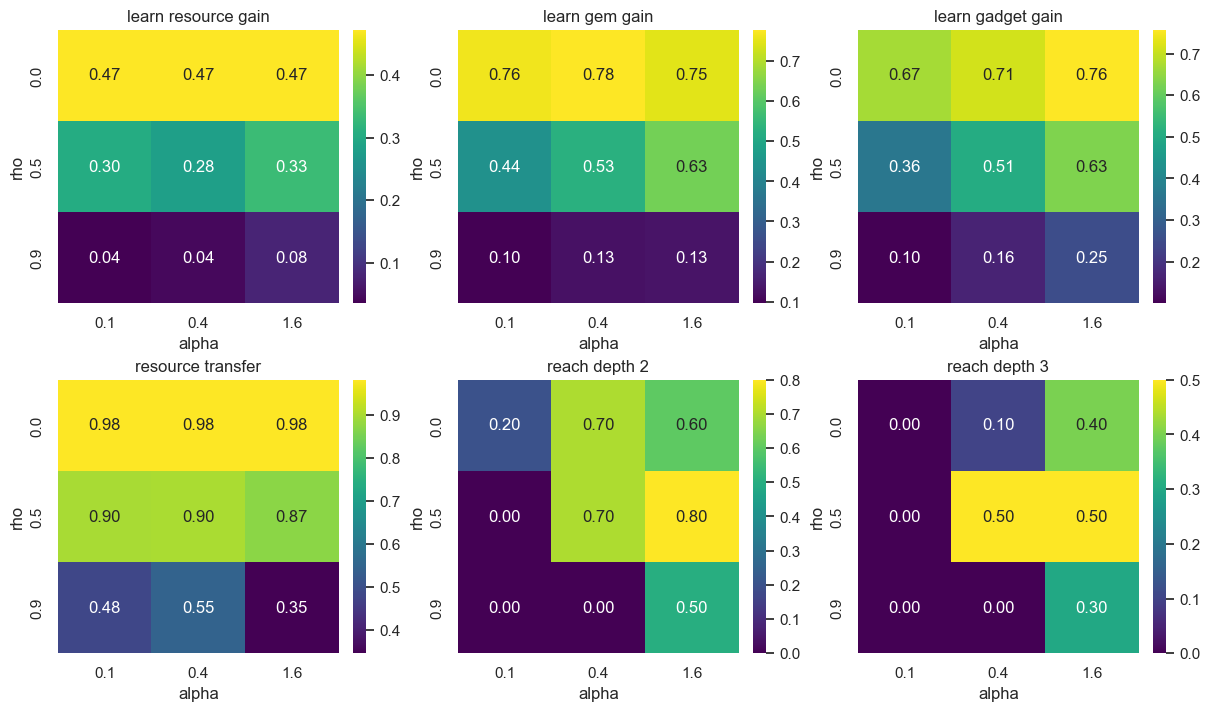

In [ ]:
# 15C. SIX HEATMAPS: LEARNING GAIN, TRANSFER, AND DEPTH. Missing transfer is displayed as missing.
if RUN_ID_GRID and len(ID_ROWS):
    metrics=['learn_resource_gain','learn_gem_gain','learn_gadget_gain',
             'resource_transfer','reach_depth_2','reach_depth_3']
    fig,axs=plt.subplots(2,3,figsize=(12,7),constrained_layout=True)
    for ax,m in zip(axs.flat,metrics):
        z=ID_GRID.groupby(['rho','alpha'])[m].mean().unstack()
        sns.heatmap(z,ax=ax,annot=True,fmt='.2f',cmap='viridis',vmin=0 if m.startswith('reach_') else None)
        ax.set_title(m.replace('_',' '))
    plt.show()
    # Within-run dispersion reveals the Monte Carlo approximation's numerical instability.
    if len(ID_SEEDS)>1:
        print('Median seed-related SD (averaged within parameter cell):')
        display(ID_GRID.groupby(['subject','alpha','rho'])[metrics].std().median().round(3))


## 16 · Signature redundancy and *response-distribution* confusability

Heatmaps establish sensitivity but not parameter identifiability. For identical schedules, compare the **entire eight-key predicted response distribution on every administered learning or single-outcome probe**. Jensen–Shannon divergence is finite for all predictions and is zero only when response probabilities match. Parameter pairs near each other are expected to be close; the nearest-*far-parameter* comparison deliberately excludes local neighbors. Do not treat the signature summaries as independent observations.

In [ ]:
# 16A. Signature covariance/correlations, plus a model-only signature scatter.
if RUN_ID_GRID and len(ID_ROWS):
    ms=['learn_resource_gain','learn_gem_gain','learn_gadget_gain','resource_transfer',
        'reach_depth_2','reach_depth_3']
    x=ID_GRID.groupby(['alpha','rho'])[ms].mean()
    fig,axs=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
    sns.heatmap(x.corr(),vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.2f',ax=axs[0])
    axs[0].set_title('Redundancy across parameter settings')
    d=x.reset_index()
    sns.scatterplot(data=d,x='learn_gem_gain',y='resource_transfer',hue='alpha',
                    style='rho',s=90,ax=axs[1])
    axs[1].set_title('Model signature space');plt.show()


In [ ]:
# 16B. Distribution-level distances: mean per-trial Jensen–Shannon divergence (nats).
def js_divergence(P,Q):
    P=np.clip(np.asarray(P,float),1e-12,1); Q=np.clip(np.asarray(Q,float),1e-12,1)
    M=.5*(P+Q)
    return float(np.mean(.5*np.sum(P*np.log(P/M),axis=1)
                        +.5*np.sum(Q*np.log(Q/M),axis=1)))

def parameter_js_distances(cache,subject=None):
    keys=[k for k in cache if subject is None or k[0]==subject]
    pairs=[]
    for a,b in combinations(keys,2):
        if a[0]!=b[0] or a[3]!=b[3]: continue   # same history, same PF seed
        P=cache[a][1];Q=cache[b][1]
        assert P.shape==Q.shape
        pairs.append(dict(subject=a[0],seed=a[3],alpha_a=a[1],rho_a=a[2],
                          alpha_b=b[1],rho_b=b[2],
                          js=js_divergence(P,Q),
                          log_alpha_gap=abs(np.log(a[1]/b[1])),rho_gap=abs(a[2]-b[2])))
    return pd.DataFrame(pairs)

if RUN_ID_GRID and len(ID_PRED)>1:
    ID_DIST=parameter_js_distances(ID_PRED)
    display(ID_DIST.sort_values('js').head(15).round(5))
    # Exclude nearby parameter settings before diagnosing global ambiguities.
    distant=ID_DIST[(ID_DIST.log_alpha_gap>=np.log(2)) | (ID_DIST.rho_gap>=0.25)]
    print('Most confusable meaningfully different settings:')
    display(distant.nsmallest(10,'js').round(5))
    fig,ax=plt.subplots(figsize=(6,3))
    sns.histplot(distant.js,ax=ax,bins=20)
    ax.set_xlabel('Mean per-trial JS divergence (nats)')
    ax.set_title('Confusability of separated parameter settings');plt.show()


## 17 · Which trial families identify parameters?

Assess each family using the *same* simulated predictions, not parameter-estimate correlations. This quantifies whether resource, gem, or gadget responses add distinct information. For genuine probe-design evaluation, use the planned probe schedule as an additional no-feedback condition; the present table has only administered learning and single-outcome probes.

In [ ]:
# 17. Predictive divergence by task component and incremental contribution.
if RUN_ID_GRID and len(ID_PRED)>1:
    family_rows=[]
    for a,b in combinations(list(ID_PRED),2):
        if a[0]!=b[0] or a[3]!=b[3]: continue
        table,P=ID_PRED[a];_,Q=ID_PRED[b]
        for fam in ['resource','gem','gadget']:
            for kind,mask in [('learning',(table.family==fam)&table.feedback),
                              ('probe',(table.family==fam)&~table.feedback)]:
                if mask.sum()==0: continue
                family_rows.append(dict(subject=a[0],seed=a[3],pair=f'{a[1]},{a[2]} | {b[1]},{b[2]}',
                    family=fam,kind=kind,n=int(mask.sum()),js=js_divergence(P[mask],Q[mask])))
    ID_COMPONENTS=pd.DataFrame(family_rows)
    fig,ax=plt.subplots(figsize=(8,3.5))
    sns.boxplot(data=ID_COMPONENTS,x='family',y='js',hue='kind',ax=ax)
    ax.set_title('Parameter discrimination by response family (exploratory)');plt.show()
    display(ID_COMPONENTS.groupby(['family','kind']).agg(n_pairs=('js','size'),
              median_js=('js','median'),mean_js=('js','mean')).round(5))


## 18 · Simulated-response recovery (optional, most expensive conceptually)

Generate synthetic physical-key responses from a *generating* grid setting, then evaluate their likelihood under each grid setting. This test conditions on predicted trajectories, uses **all eight keyboard-key probabilities**, and requires no human choices. The option below supports independent generating-vs-fitting seeds, but using different PF seeds introduces approximation noise rather than genuine between-subject learning variation. Expand the schedule set, simulation repetitions, and particle count before drawing recovery conclusions. *Do not* treat this as exact recovery of the full joint HOLMES generative model.

In [ ]:
# 18A. Recovery from synthetic keyboard responses under fixed model-prediction trajectories.
RUN_ID_RECOVERY = False
ID_RECOVERY_REPS = 20
ID_RECOVERY_RNG = np.random.default_rng(317)

def synthetic_recovery(cache, reps=20, rng=None):
    rng=np.random.default_rng(317) if rng is None else rng
    rows=[]
    for sid in sorted(set(k[0] for k in cache)):
        # Use one generating seed and a different fitting seed when available.
        seeds=sorted(set(k[3] for k in cache if k[0]==sid))
        gen_seed=seeds[0]; eval_seed=seeds[1] if len(seeds)>1 else seeds[0]
        gen=[k for k in cache if k[0]==sid and k[3]==gen_seed]
        candidates=[k for k in cache if k[0]==sid and k[3]==eval_seed]
        for true in gen:
            P=cache[true][1]
            for rep in range(reps):
                choices=np.array([rng.choice(len(KEYS),p=p) for p in P])
                scores=[]
                for fitkey in candidates:
                    Q=cache[fitkey][1]
                    scores.append(float(np.log(np.clip(Q[np.arange(len(Q)),choices],1e-12,1)).sum()))
                best=candidates[int(np.argmax(scores))]
                rows.append(dict(subject=sid,alpha_true=true[1],rho_true=true[2],
                    alpha_hat=best[1],rho_hat=best[2],rep=rep,
                    same_grid_point=(true[1:3]==best[1:3]),
                    best_loglik=float(max(scores))))
    return pd.DataFrame(rows)

if RUN_ID_GRID and RUN_ID_RECOVERY:
    ID_RECOVERY=synthetic_recovery(ID_PRED,reps=ID_RECOVERY_REPS,rng=ID_RECOVERY_RNG)
    print('Grid-point recovery:',ID_RECOVERY.same_grid_point.mean().round(3))
    fig,axs=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
    for ax,p in zip(axs,['alpha','rho']):
        tab=pd.crosstab(ID_RECOVERY[p+'_true'],ID_RECOVERY[p+'_hat'],normalize='index')
        sns.heatmap(tab,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues',ax=ax)
        ax.set_title(f'{p} recovery (row-normalized)')
    plt.show()
else:
    print('Recovery off. Enable RUN_ID_GRID then RUN_ID_RECOVERY once the grid is cached.')


Recovery off. Enable RUN_ID_GRID then RUN_ID_RECOVERY once the grid is cached.


### Reading the outputs

- A flat sensitivity map means the signature is weakly informative about those parameters on the tested schedule.
- A high **within-seed** signal but strong variation **between seeds** suggests inadequate particle resolution.
- Small JS between meaningfully different parameter settings indicates near-indistinguishable response predictions for the *current schedule*; this is a design diagnostic, not proof of structural nonidentifiability.
- A recovery matrix is useful only after repeat simulations and parameter points outside the evaluation grid.
- Future explicit grouping/reward-set probes need a stated probabilistic readout before they can legitimately enter the recovery likelihood. The present cells do **not** mistake posterior node similarity for observed partition probability.

Computing reward associations for P001 α=0.10 ρ=0.00 ...
Computing reward associations for P001 α=0.10 ρ=0.50 ...
Computing reward associations for P001 α=0.10 ρ=0.90 ...
Computing reward associations for P001 α=0.40 ρ=0.00 ...
Computing reward associations for P001 α=0.40 ρ=0.50 ...
Computing reward associations for P001 α=0.40 ρ=0.90 ...
Computing reward associations for P001 α=1.60 ρ=0.00 ...
Computing reward associations for P001 α=1.60 ρ=0.50 ...
Computing reward associations for P001 α=1.60 ρ=0.90 ...
Computed 9 reward representations.


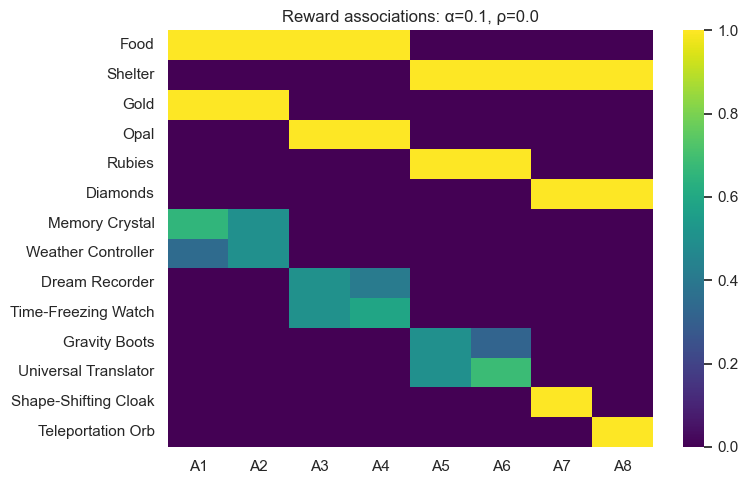

In [ ]:

# 19A · Reward–alien association representations
# Probe each alien after the full scheduled training sequence.
# No additional feedback is supplied.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import product, combinations
from copy import deepcopy

REWARD_LABELS = (
    ["Food", "Shelter"] +
    ["Gold", "Opal", "Rubies", "Diamonds"] +
    ["Memory Crystal", "Weather Controller", "Dream Recorder",
     "Time-Freezing Watch", "Gravity Boots", "Universal Translator",
     "Shape-Shifting Cloak", "Teleportation Orb"]
)
REWARD_LEVELS = np.array([0]*2 + [1]*4 + [2]*8)

# Reward category values corresponding to the true alien relationships.
# Assert expected coding before attaching human-readable labels.
assert np.array_equal(RESOURCE, [0,0,0,0,1,1,1,1])
assert np.array_equal(GEM, [0,0,1,1,2,2,3,3])
assert np.array_equal(GADGET, np.arange(8))

def reward_associations(fit):
    """A[r,a] = P(reward r | alien a), conditioned on identity only."""
    A = np.zeros((14, 8))

    # Avoid modifying the original model's global node registry.
    probe_fit = dict(fit)
    probe_fit["registry"] = deepcopy(fit["registry"])

    for a in range(8):
        values = [a, int(RESOURCE[a]), int(GEM[a]), int(GADGET[a])]
        pr = HOLMES.probe_categorical(
            probe_fit, values, [True, False, False, False]
        )
        A[0:2, a] = pr["family_probs"][1]
        A[2:6, a] = pr["family_probs"][2]
        A[6:14, a] = pr["family_probs"][3]

    return A

RUN_REWARD_GRID = True
REWARD_MODEL = {}

if RUN_REWARD_GRID:
    for sid in ID_SUBJECTS:
        _, task = subject_task(sid)

        for alpha, rho in product(ID_ALPHAS, ID_RHOS):
            print(f"Computing reward associations for {sid} α={alpha:.2f} ρ={rho:.2f} ...")
            for seed in ID_SEEDS:
                fit = model_fit(
                    task, float(alpha), FIXED_OMEGA,
                    rho=float(rho),
                    particles=ID_PARTICLES, seed=seed
                )
                key = (sid, float(alpha), float(rho), seed)
                REWARD_MODEL[key] = reward_associations(fit)

    print(f"Computed {len(REWARD_MODEL)} reward representations.")

    # Display one example.
    key = next(iter(REWARD_MODEL))
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.heatmap(
        REWARD_MODEL[key], ax=ax, cmap="viridis",
        vmin=0, vmax=1,
        xticklabels=[f"A{i}" for i in range(1,9)],
        yticklabels=REWARD_LABELS
    )
    ax.set_title(f"Reward associations: α={key[1]}, ρ={key[2]}")
    plt.tight_layout()
    plt.show()


,subject,alpha,rho,seed,gem_to_resource,gadget_to_gem,resource_discrimination
0,P001,0.1,0.0,13,1.000,1.000,1.000
1,P001,0.1,0.5,13,0.777,0.506,0.848
2,P001,0.1,0.9,13,0.009,0.040,0.024
3,P001,0.4,0.0,13,1.000,0.982,1.000
4,P001,0.4,0.5,13,0.602,0.664,0.708
5,P001,0.4,0.9,13,0.020,0.066,0.070
6,P001,1.6,0.0,13,1.000,1.000,1.000
7,P001,1.6,0.5,13,0.754,0.797,0.819
8,P001,1.6,0.9,13,0.006,0.050,0.091


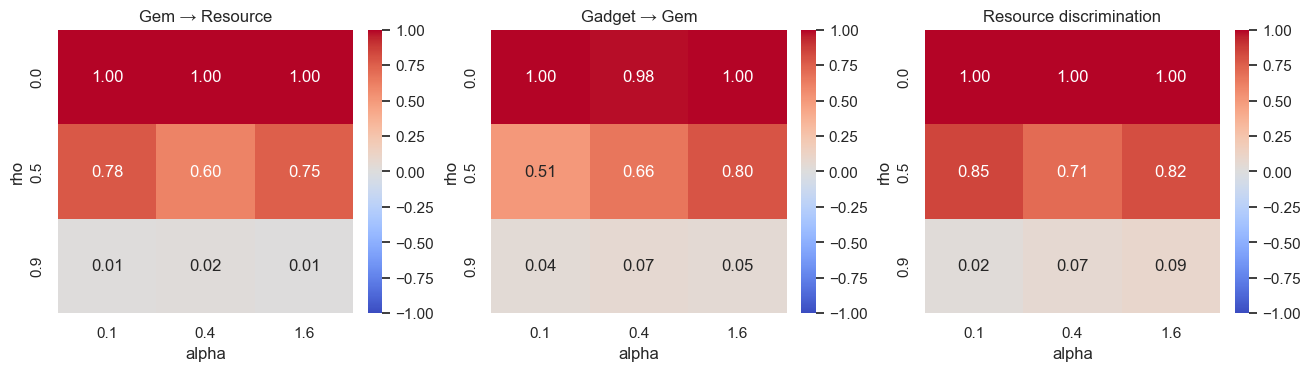

In [ ]:

# 19B · Directional containment and hierarchical parent advantage
# Tests correct gem -> resource and gadget -> gem relationships.

def containment(A, child_row, parent_row):
    """Soft directional containment of child reward in parent reward."""
    child = A[child_row]
    parent = A[parent_row]
    return float(np.dot(child, parent) /
                 max(child.sum(), 1e-12))

def hierarchy_containment(A):
    """Correct-parent advantage at each adjacent hierarchy level."""

    # Each gem's correct resource.
    gem_scores = []
    for g in range(4):
        aliens = np.where(GEM == g)[0]
        correct_resource = int(RESOURCE[aliens[0]])

        child_row = 2 + g
        correct = containment(A, child_row, correct_resource)
        incorrect = containment(A, child_row, 1-correct_resource)

        gem_scores.append(correct - incorrect)

    # Each gadget's correct gem versus the three incorrect gems.
    gadget_scores = []
    for a in range(8):
        correct_gem = int(GEM[a])
        child_row = 6 + a

        correct = containment(A, child_row, 2 + correct_gem)
        incorrect = np.mean([
            containment(A, child_row, 2 + g)
            for g in range(4) if g != correct_gem
        ])
        gadget_scores.append(correct - incorrect)

    # Also measure broad separation of resource categories.
    resource_contrast = []
    for a in range(8):
        correct = A[int(RESOURCE[a]), a]
        incorrect = A[1-int(RESOURCE[a]), a]
        resource_contrast.append(correct - incorrect)

    return dict(
        gem_to_resource=np.mean(gem_scores),
        gadget_to_gem=np.mean(gadget_scores),
        resource_discrimination=np.mean(resource_contrast)
    )

CONTAINMENT_ROWS = []
for (sid, alpha, rho, seed), A in REWARD_MODEL.items():
    CONTAINMENT_ROWS.append(dict(
        subject=sid, alpha=alpha, rho=rho, seed=seed,
        **hierarchy_containment(A)
    ))

CONTAINMENT_GRID = pd.DataFrame(CONTAINMENT_ROWS)
display(CONTAINMENT_GRID.round(3))

# Parameter sensitivity maps.
metrics = [
    ("gem_to_resource", "Gem → Resource"),
    ("gadget_to_gem", "Gadget → Gem"),
    ("resource_discrimination", "Resource discrimination")
]

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6),
                        constrained_layout=True)

for ax, (metric, title) in zip(axs, metrics):
    z = CONTAINMENT_GRID.groupby(
        ["rho", "alpha"]
    )[metric].mean().unstack()

    sns.heatmap(
        z, ax=ax, annot=True, fmt=".2f",
        cmap="coolwarm", center=0,
        vmin=-1, vmax=1
    )
    ax.set_title(title)

plt.show()


In [ ]:

# 19C · Human reward grouping: correct-parent co-grouping
# Reward names correspond to rows of the 14 x 8 matrix above.

import re

ALIASES = {
    "food":0, "shelter":1,
    "gold":2, "opal":3, "opal1":3,
    "ruby":4, "rubies":4, "diamond":5, "diamonds":5,
    "memorycrystal":6, "weathercontroller":7,
    "dreamrecorder":8, "timefreezingwatch":9,
    "gravityboots":10, "universaltranslator":11,
    "shapeshiftingcloak":12, "shapeshiftingcloaks":12,
    "teleportationorb":13
}

def reward_id(name):
    text = re.sub(r"[^a-z0-9]", "", str(name).lower().replace(".png",""))
    return ALIASES.get(text, None)

def human_parent_advantage(sid):
    """Co-grouping of correct parent versus incorrect parents."""
    d = REWARD_PLACEMENTS[
        REWARD_PLACEMENTS.subject == sid
    ].copy()
    groups = {}
    for r in d.itertuples():
        rid = reward_id(r.item)
        if rid is not None:
            groups[rid] = r.box

    def together(i, j):
        if i not in groups or j not in groups:
            return np.nan
        return float(groups[i] == groups[j])

    gem_scores, gadget_scores = [], []

    for g in range(4):
        a = np.where(GEM == g)[0][0]
        parent = int(RESOURCE[a])
        x = together(2+g, parent)
        y = together(2+g, 1-parent)
        if np.isfinite(x) and np.isfinite(y):
            gem_scores.append(x-y)

    for a in range(8):
        parent = int(GEM[a])
        correct = together(6+a, 2+parent)
        incorrect = [
            together(6+a, 2+g)
            for g in range(4) if g != parent
        ]
        if np.isfinite(correct) and all(np.isfinite(incorrect)):
            gadget_scores.append(correct-np.mean(incorrect))

    return dict(
        subject=sid,
        human_gem_to_resource=(
            np.mean(gem_scores) if gem_scores else np.nan
        ),
        human_gadget_to_gem=(
            np.mean(gadget_scores) if gadget_scores else np.nan
        ),
        n_gem_pairs=len(gem_scores),
        n_gadget_pairs=len(gadget_scores)
    )

HUMAN_CONTAINMENT = pd.DataFrame([
    human_parent_advantage(sid)
    for sid in sorted(REWARD_PLACEMENTS.subject.unique())
])
display(HUMAN_CONTAINMENT.round(3))

# Human and model signatures displayed together, not fitted jointly.
COMPARE_CONTAINMENT = CONTAINMENT_GRID.merge(
    HUMAN_CONTAINMENT, on="subject", how="left"
)
display(COMPARE_CONTAINMENT.head(12).round(3))

print("Human co-grouping is a flat partition, not directed containment.")
print("Zero may mean all separate, not necessarily absent knowledge.")
print("These measures should not yet be treated as equivalent likelihoods.")


,subject,human_gem_to_resource,human_gadget_to_gem,n_gem_pairs,n_gadget_pairs
0,P001,0.0,0.333,4,3
1,P002,0.0,0.000,4,8
2,P003,0.0,0.000,4,8
3,P004,0.0,0.000,4,8
4,P005,0.0,0.000,4,8
5,P006,0.0,-0.042,4,8
6,P007,0.0,0.292,4,8
7,P008,0.0,0.000,4,8
8,P009,0.0,0.333,4,8


,subject,alpha,rho,seed,gem_to_resource,gadget_to_gem,resource_discrimination,human_gem_to_resource,human_gadget_to_gem,n_gem_pairs,n_gadget_pairs
0,P001,0.1,0.0,13,1.000,1.000,1.000,0.0,0.333,4,3
1,P001,0.1,0.5,13,0.777,0.506,0.848,0.0,0.333,4,3
2,P001,0.1,0.9,13,0.009,0.040,0.024,0.0,0.333,4,3
3,P001,0.4,0.0,13,1.000,0.982,1.000,0.0,0.333,4,3
4,P001,0.4,0.5,13,0.602,0.664,0.708,0.0,0.333,4,3
5,P001,0.4,0.9,13,0.020,0.066,0.070,0.0,0.333,4,3
6,P001,1.6,0.0,13,1.000,1.000,1.000,0.0,0.333,4,3
7,P001,1.6,0.5,13,0.754,0.797,0.819,0.0,0.333,4,3
8,P001,1.6,0.9,13,0.006,0.050,0.091,0.0,0.333,4,3


Human co-grouping is a flat partition, not directed containment.
Zero may mean all separate, not necessarily absent knowledge.
These measures should not yet be treated as equivalent likelihoods.


In [ ]:

# 19D · Compound outcome predictions across hierarchy levels
# Joint confidence approximation from post-training family marginals.
# No assumption that HOLMES directly predicts panel selection.

FAMILY_OFFSET = {"resource":0, "gem":2, "gadget":6}
FAMILY_TRUTH = {
    "resource":RESOURCE,
    "gem":GEM,
    "gadget":GADGET
}
FAMILY_PAIRS = [
    ("resource", "gem"),
    ("resource", "gadget"),
    ("gem", "gadget")
]

compound_rows = []
for (sid, alpha, rho, seed), A in REWARD_MODEL.items():
    for a in range(8):
        for f1, f2 in FAMILY_PAIRS:
            c1 = int(FAMILY_TRUTH[f1][a])
            c2 = int(FAMILY_TRUTH[f2][a])

            p1 = float(A[FAMILY_OFFSET[f1]+c1, a])
            p2 = float(A[FAMILY_OFFSET[f2]+c2, a])

            compound_rows.append(dict(
                subject=sid, alpha=alpha, rho=rho, seed=seed,
                alien=a+1, pair=f"{f1}+{f2}",
                p_first=p1, p_second=p2,
                p_both_approx=p1*p2,
                p_both_upper=min(p1,p2),
                p_both_lower=max(0.,p1+p2-1.)
            ))

COMPOUND_MODEL = pd.DataFrame(compound_rows)

fig, axs = plt.subplots(1, 3, figsize=(13,3.5),
                        constrained_layout=True)

for ax, pair in zip(axs, COMPOUND_MODEL.pair.unique()):
    d = COMPOUND_MODEL[COMPOUND_MODEL.pair==pair]
    z = d.groupby(["rho","alpha"]).p_both_approx.mean().unstack()
    sns.heatmap(
        z, ax=ax, annot=True, fmt=".2f",
        cmap="viridis", vmin=0, vmax=1
    )
    ax.set_title(pair)

plt.show()

display(
    COMPOUND_MODEL.groupby(["alpha","rho","pair"])
    .agg(
        mean_joint=("p_both_approx","mean"),
        lower_bound=("p_both_lower","mean"),
        upper_bound=("p_both_upper","mean")
    ).round(3)
)

# Compare how strongly each compound condition varies across parameters.
sensitivity = (
    COMPOUND_MODEL.groupby(["alpha","rho","pair"])
    .p_both_approx.mean().reset_index()
    .groupby("pair").p_both_approx
    .agg(["min","max","std"])
)
sensitivity["range"] = sensitivity["max"]-sensitivity["min"]
display(sensitivity.round(3))

print("Joint probabilities are approximated by products of marginals.")
print("Bounds are valid for an unspecified dependence structure.")
print("The model does not directly predict which colored panels are selected.")


,subject,checkpoint,checkpoint_name,n_aliens,complete,n_groups,group_entropy,singleton_fraction,largest_group,mean_group_size,cross_resource_merge,gem_cohesion,resource_only_cohesion,hierarchy_contrast
0,P001,1,Baseline,8,True,8,2.079,1.000,1,1.000,0.000,0.00,0.000,0.000
1,P001,2,Post-learning,8,True,8,2.079,1.000,1,1.000,0.000,0.00,0.000,0.000
2,P001,3,Post-single probes,8,True,8,2.079,1.000,1,1.000,0.000,0.00,0.000,0.000
3,P001,4,Post-multi probes,8,True,8,2.079,1.000,1,1.000,0.000,0.00,0.000,0.000
4,P001,5,Final,7,False,7,1.946,1.000,1,1.000,0.000,0.00,0.000,0.000
5,P002,1,Baseline,8,True,6,1.733,0.667,2,1.333,0.125,0.00,0.000,-0.125
6,P002,2,Post-learning,8,True,5,1.560,0.400,2,1.600,0.125,0.25,0.000,0.125
7,P002,3,Post-single probes,8,True,5,1.560,0.400,2,1.600,0.125,0.25,0.000,0.125
8,P002,4,Post-multi probes,8,True,5,1.560,0.400,2,1.600,0.125,0.25,0.000,0.125
9,P002,5,Final,8,True,6,1.733,0.667,2,1.333,0.125,0.00,0.000,-0.125


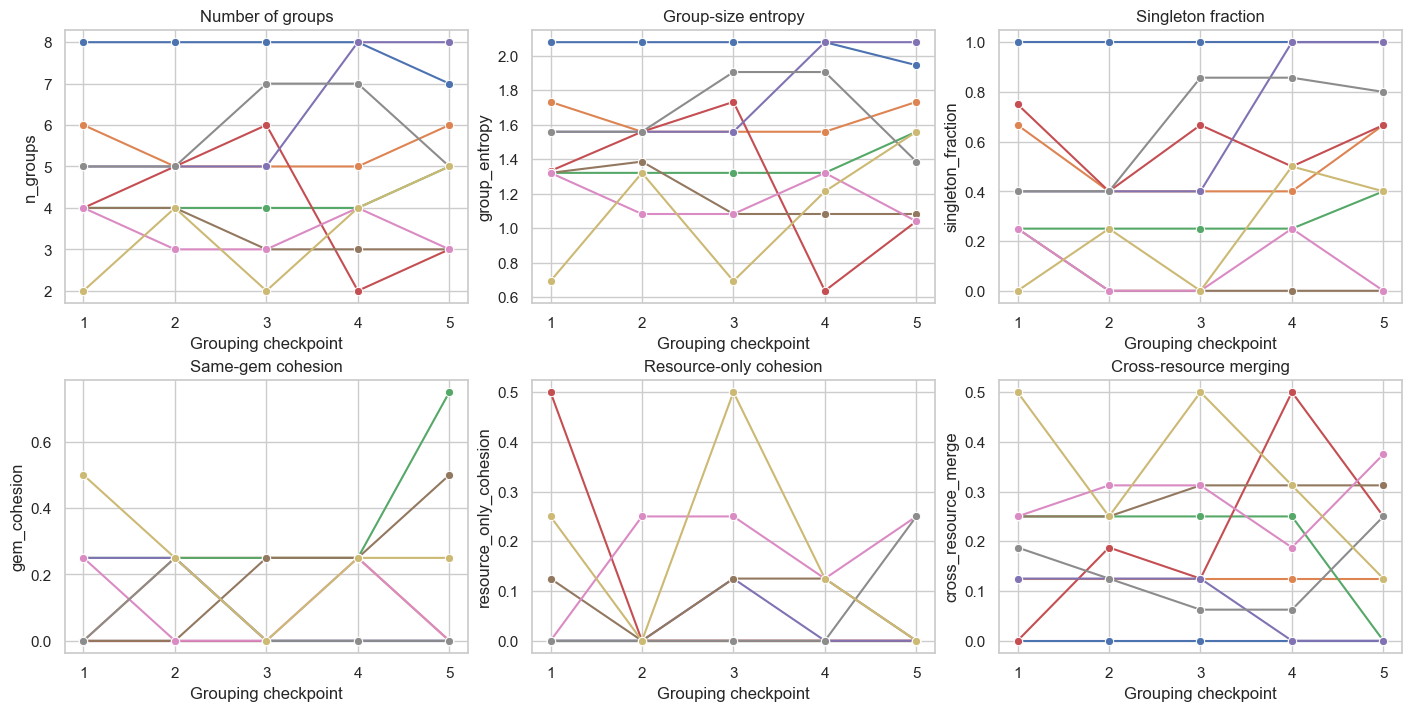

checkpoint,1,2,3,4,5
subject,,,,,
P001,8,8,8,8,7
P002,6,5,5,5,6
P003,4,4,4,4,5
P004,4,5,6,2,3
P005,5,5,5,8,8
P006,4,4,3,3,3
P007,4,3,3,4,3
P008,5,5,7,7,5
P009,2,4,2,4,5


In [ ]:

# 20A · Human explicit-grouping signatures
# Complete eight-alien partitions only for primary comparisons.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CP_ORDER = sorted(GROUPINGS.checkpoint.dropna().unique())
HUMAN_GROUP_ROWS = []

for (sid, cp), d in GROUPINGS.groupby(["subject", "checkpoint"]):
    d = d.drop_duplicates("alien")
    sizes = d.groupby("box").size().to_numpy()
    n = len(d)
    probs = sizes / sizes.sum()
    entropy = -np.sum(probs * np.log(probs))

    HUMAN_GROUP_ROWS.append(dict(
        subject=sid, checkpoint=int(cp),
        checkpoint_name=CHECKPOINT_NAMES.get(int(cp), str(cp)),
        n_aliens=n,
        complete=n == 8,
        n_groups=len(sizes),
        group_entropy=entropy,
        singleton_fraction=np.sum(sizes == 1) / len(sizes),
        largest_group=int(sizes.max()),
        mean_group_size=float(sizes.mean())
    ))

HUMAN_GROUP_SIG = pd.DataFrame(HUMAN_GROUP_ROWS)

# Pairwise alignment with the true task hierarchy.
pair_metrics = (
    PAIRWISE_PROFILE.pivot_table(
        index=["subject", "checkpoint"],
        columns="pair_type", values="p_same"
    )
    .reset_index()
    .rename(columns={
        "same_gem": "gem_cohesion",
        "same_resource_diff_gem": "resource_only_cohesion",
        "different_resource": "cross_resource_merge"
    })
)

HUMAN_GROUP_SIG = HUMAN_GROUP_SIG.merge(
    pair_metrics, on=["subject", "checkpoint"], how="left"
)

HUMAN_GROUP_SIG["hierarchy_contrast"] = (
    HUMAN_GROUP_SIG.gem_cohesion -
    HUMAN_GROUP_SIG.cross_resource_merge
)

display(HUMAN_GROUP_SIG.round(3))

fig, axs = plt.subplots(2, 3, figsize=(14, 7),
                        constrained_layout=True)

metrics = [
    ("n_groups", "Number of groups"),
    ("group_entropy", "Group-size entropy"),
    ("singleton_fraction", "Singleton fraction"),
    ("gem_cohesion", "Same-gem cohesion"),
    ("resource_only_cohesion", "Resource-only cohesion"),
    ("cross_resource_merge", "Cross-resource merging")
]

for ax, (metric, title) in zip(axs.flat, metrics):
    sns.lineplot(
        data=HUMAN_GROUP_SIG, x="checkpoint", y=metric,
        hue="subject", units="subject", estimator=None,
        marker="o", legend=False, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Grouping checkpoint")

plt.show()

# Counts indicate whether group formation is monotonic.
wide = HUMAN_GROUP_SIG.pivot(
    index="subject", columns="checkpoint", values="n_groups"
)
# Primary grouping analysis: complete partitions only
HUMAN_GROUP_COMPLETE = HUMAN_GROUP_SIG[
    HUMAN_GROUP_SIG.complete
].copy()

# Audit incomplete partitions separately
display(
    HUMAN_GROUP_SIG.loc[
        ~HUMAN_GROUP_SIG.complete,
        ["subject", "checkpoint_name", "n_aliens", "n_groups"]
    ]
)


In [ ]:

# 20B · Model-predicted partitions of all eight aliens
# Preserve the shared posterior particle when sampling alien paths.
# This is preferable to independently sampling from marginal path_mass.

from copy import deepcopy

GROUP_CUTS = [1, 2, 3, 4, 5]
GROUP_DRAWS = 100  # draws per parameter setting; increase for confirmation
RUN_GROUP_MODEL = True

def grouping_candidates(fit):
    """Conditional path probabilities for each alien within each particle."""
    reg = deepcopy(fit["registry"])
    par = fit["params"]
    n = par["n_particles"]

    pi, branches, gids, logprior = HOLMES.enumerate_paths_nodestop(
        fit["level_counts"], fit["s_stop"], fit["s_cont"],
        reg, n, par["max_depth"], par["alpha"],
        par["depth_decay"], par["max_children"], par["kappa"]
    )

    lengths = (gids >= 0).sum(axis=1)
    leaves = gids[np.arange(len(gids)), lengths - 1]
    cache = {}

    # Predict identity at each candidate terminal node.
    identity_probs = np.stack([
        HOLMES._node_predictive(
            int(pi[i]), int(leaves[i]), 0,
            fit["family_counts"], fit["family_sizes"],
            reg, par["omega"], par["inheritance_lambda"], cache
        )
        for i in range(len(pi))
    ])

    # For a fixed posterior particle, each alien has its own
    # conditional distribution over candidate hierarchical paths.
    candidates = {}
    for p in range(n):
        ix = np.where(pi == p)[0]
        lp = logprior[ix]

        for a in range(8):
            logw = lp + np.log(np.maximum(identity_probs[ix, a], 1e-300))
            w = np.exp(logw - logw.max())
            w /= w.sum()
            candidates[p, a] = (gids[ix].copy(), w)

    return candidates

def partition_at_cut(paths, cut):
    """Assign grouping labels based on shared path prefix."""
    signatures = []

    for path in paths:
        valid = tuple(int(x) for x in path if x >= 0)
        signatures.append(valid[:cut])

    mapping = {}
    labels = []
    for sig in signatures:
        if sig not in mapping:
            mapping[sig] = len(mapping)
        labels.append(mapping[sig])

    return np.asarray(labels)

def partition_signature(labels):
    """Statistics of a flat eight-alien partition."""
    sizes = np.unique(labels, return_counts=True)[1]
    probs = sizes / sizes.sum()

    pairs = [
        (i, j, int(labels[i] == labels[j]))
        for i in range(8) for j in range(i+1, 8)
    ]

    def cohesion(condition):
        x = [same for i, j, same in pairs if condition(i, j)]
        return float(np.mean(x)) if x else np.nan

    return dict(
        n_groups=len(sizes),
        group_entropy=float(-np.sum(probs * np.log(probs))),
        singleton_fraction=float(np.mean(sizes == 1)),
        gem_cohesion=cohesion(lambda i,j: GEM[i] == GEM[j]),
        resource_only_cohesion=cohesion(
            lambda i,j: RESOURCE[i] == RESOURCE[j] and GEM[i] != GEM[j]
        ),
        cross_resource_merge=cohesion(
            lambda i,j: RESOURCE[i] != RESOURCE[j]
        )
    )

def sample_groupings(fit, draws=100, seed=2026):
    """Sample predictive eight-alien partitions at every hierarchy cut."""
    rng = np.random.default_rng(seed)
    candidates = grouping_candidates(fit)
    weights = np.asarray(fit["particle_weights"], float)
    weights /= weights.sum()

    rows = []
    for draw in range(draws):
        # One shared posterior history per hypothetical grouping.
        p = int(rng.choice(len(weights), p=weights))

        paths = []
        for a in range(8):
            path_array, probs = candidates[p, a]
            k = rng.choice(len(probs), p=probs)
            paths.append(path_array[k])

        for cut in GROUP_CUTS:
            labels = partition_at_cut(paths, cut)
            rows.append(dict(
                draw=draw, cut=cut,
                **partition_signature(labels)
            ))

    return pd.DataFrame(rows)

# Refit only if GROUP_MODEL_CACHE is not already present.
GROUP_MODEL_CACHE = globals().get("GROUP_MODEL_CACHE", {})
GROUP_MODEL_ROWS = []

if RUN_GROUP_MODEL:
    for sid in ID_SUBJECTS:
        _, task = subject_task(sid)

        for alpha in ID_ALPHAS:
            for rho in ID_RHOS:
                for seed in ID_SEEDS:
                    print(f"Sampling groupings for {sid} α={alpha:.2f} ρ={rho:.2f} seed={seed} ...")
                    key = (sid, float(alpha), float(rho), seed)

                    if key not in GROUP_MODEL_CACHE:
                        fit = model_fit(
                            task, float(alpha), FIXED_OMEGA,
                            rho=float(rho),
                            particles=ID_PARTICLES, seed=seed
                        )
                        GROUP_MODEL_CACHE[key] = sample_groupings(
                            fit, draws=GROUP_DRAWS, seed=seed + 100
                        )

                    d = GROUP_MODEL_CACHE[key].copy()
                    d["subject"], d["alpha"] = sid, float(alpha)
                    d["rho"], d["seed"] = float(rho), seed
                    GROUP_MODEL_ROWS.append(d)

    GROUP_MODEL = pd.concat(GROUP_MODEL_ROWS, ignore_index=True)
    display(
        GROUP_MODEL.groupby(["alpha", "rho", "cut"])
        [["n_groups", "gem_cohesion",
          "resource_only_cohesion", "cross_resource_merge"]]
        .mean().round(3)
    )


n_groups  gem_cohesion  resource_only_cohesion  \
alpha rho cut                                                   
0.1   0.0 1        5.00         0.750                   0.000   
          2        5.90         0.525                   0.000   
          3        5.90         0.525                   0.000   
          4        5.90         0.525                   0.000   
          5        5.90         0.525                   0.000   
      0.5 1        2.99         0.965                   0.522   
          2        4.46         0.608                   0.386   
          3        4.47         0.605                   0.386   
          4        4.47         0.605                   0.386   
          5        4.47         0.605                   0.386   
      0.9 1        1.96         0.785                   0.625   
          2        2.58         0.630                   0.511   
          3        2.63         0.628                   0.511   
          4        2.63         0.628                   0.511   
          5        2.63         0.628                   0.511   
0.4   0.0 1        5.00         0.742                   0.008   
          2        6.86         0.280                   0.002   
          3        7.00         0.245                   0.002   
          4        7.00         0.245                   0.002   
          5        7.00         0.245                   0.002   
      0.5 1        4.30         0.838                   0.032   
          2        6.08         0.410                   0.018   
          3        6.24         0.370                   0.018   
          4        6.25         0.368                   0.018   
          5        6.25         0.368                   0.018   
      0.9 1        2.96         0.540                   0.164   
          2        4.61         0.312                   0.095   
          3        4.87         0.292                   0.086   
          4        4.91         0.290                   0.085   
          5        4.91         0.290                   0.085   
1.6   0.0 1        5.00         0.750                   0.000   
          2        7.41         0.148                   0.000   
          3        7.53         0.118                   0.000   
          4        7.53         0.118                   0.000   
          5        7.53         0.118                   0.000   
      0.5 1        4.64         0.802                   0.026   
          2        7.36         0.145                   0.005   
          3        7.60         0.092                   0.002   
          4        7.60         0.092                   0.002   
          5        7.60         0.092                   0.002   
      0.9 1        3.95         0.200                   0.190   
          2        6.86         0.058                   0.054   
          3        7.16         0.040                   0.041   
          4        7.28         0.038                   0.032   
          5        7.35         0.038                   0.031   

               cross_resource_merge  
alpha rho cut                        
0.1   0.0 1                   0.000  
          2                   0.000  
          3                   0.000  
          4                   0.000  
          5                   0.000  
      0.5 1                   0.006  
          2                   0.001  
          3                   0.001  
          4                   0.001  
          5                   0.001  
      0.9 1                   0.636  
          2                   0.534  
          3                   0.531  
          4                   0.531  
          5                   0.531  
0.4   0.0 1                   0.000  
          2                   0.000  
          3                   0.000  
          4                   0.000  
          5                   0.000  
      0.5 1                   0.025  
          2                   0.014  
          3                   0.014  
         

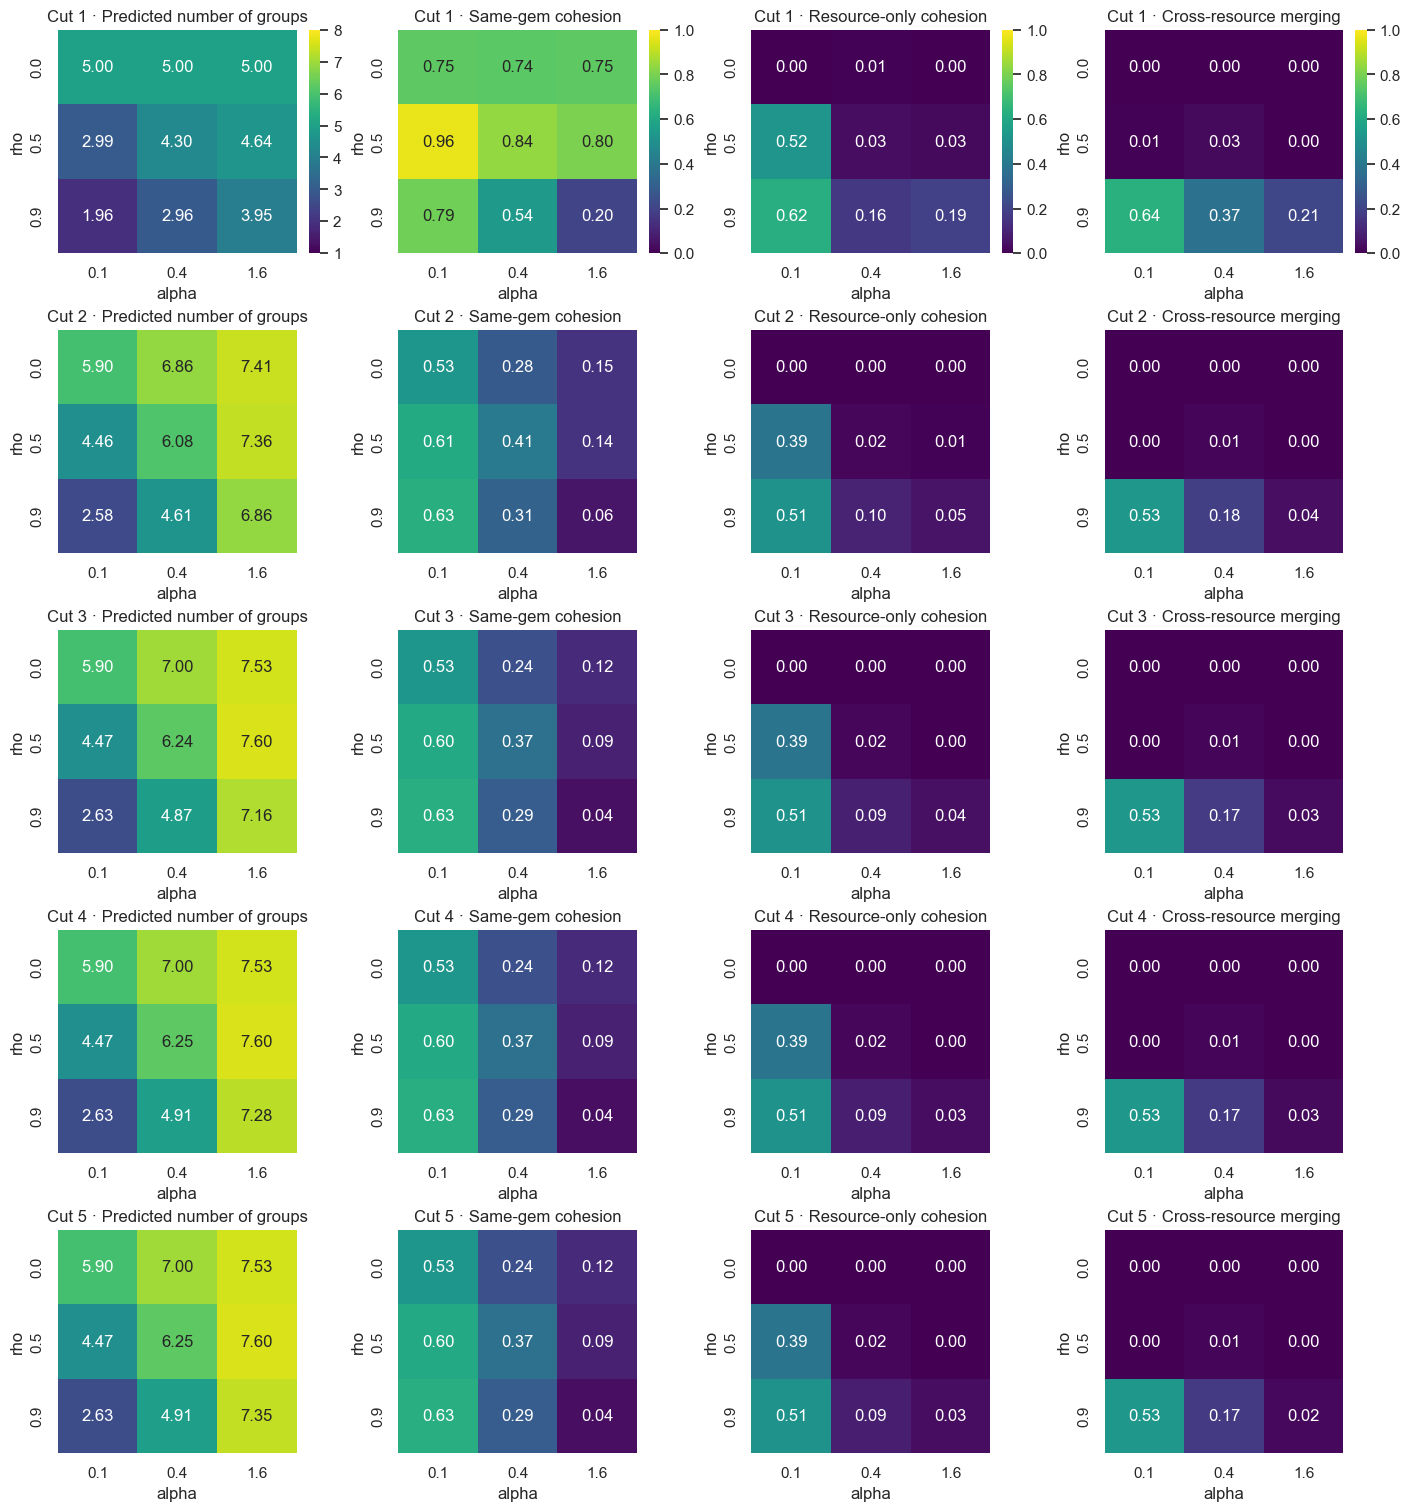

,cut,metric,alpha_sensitivity,rho_sensitivity
0,1,n_groups,1.213,2.043
1,1,gem_cohesion,0.252,0.372
2,1,resource_only_cohesion,0.322,0.324
3,1,cross_resource_merge,0.148,0.408
4,2,n_groups,2.897,2.040
5,2,gem_cohesion,0.471,0.108
6,2,resource_only_cohesion,0.280,0.219
7,2,cross_resource_merge,0.170,0.252
8,3,n_groups,3.097,1.947
9,3,gem_cohesion,0.502,0.102


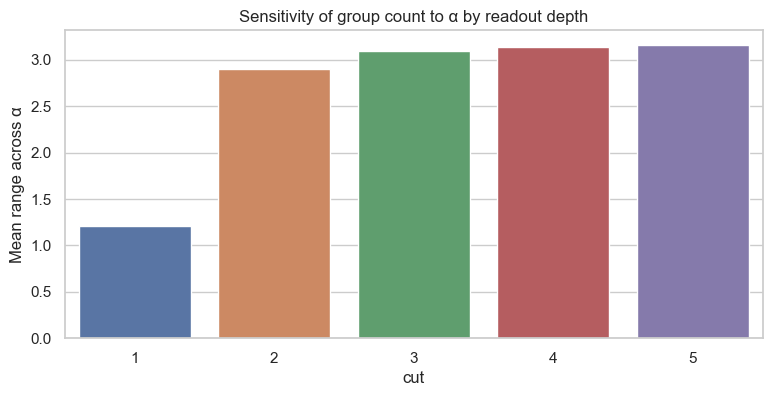

In [ ]:

# 20C · Structural sensitivity maps
# Separate the effects of alpha, rho, and grouping readout depth.

GROUP_MEANS = (
    GROUP_MODEL.groupby(["alpha", "rho", "cut"], as_index=False)
    .agg(
        n_groups=("n_groups", "mean"),
        group_entropy=("group_entropy", "mean"),
        gem_cohesion=("gem_cohesion", "mean"),
        resource_only_cohesion=("resource_only_cohesion", "mean"),
        cross_resource_merge=("cross_resource_merge", "mean")
    )
)

metrics = [
    ("n_groups", "Predicted number of groups"),
    ("gem_cohesion", "Same-gem cohesion"),
    ("resource_only_cohesion", "Resource-only cohesion"),
    ("cross_resource_merge", "Cross-resource merging")
]

fig, axs = plt.subplots(
    len(GROUP_CUTS), len(metrics),
    figsize=(14, 3 * len(GROUP_CUTS)),
    constrained_layout=True
)

for i, cut in enumerate(GROUP_CUTS):
    d = GROUP_MEANS[GROUP_MEANS.cut == cut]

    for j, (metric, label) in enumerate(metrics):
        z = d.pivot(index="rho", columns="alpha", values=metric)

        sns.heatmap(
            z, annot=True, fmt=".2f", cmap="viridis",
            vmin=1 if metric == "n_groups" else 0,
            vmax=8 if metric == "n_groups" else 1,
            cbar=(i == 0), ax=axs[i, j]
        )
        axs[i, j].set_title(f"Cut {cut} · {label}")

plt.show()

# How much does each metric vary with alpha versus rho?
sensitivity_rows = []
for cut in GROUP_CUTS:
    d = GROUP_MEANS[GROUP_MEANS.cut == cut]

    for metric, _ in metrics:
        mat = d.pivot(index="rho", columns="alpha", values=metric)

        alpha_range = mat.max(axis=1) - mat.min(axis=1)
        rho_range = mat.max(axis=0) - mat.min(axis=0)

        sensitivity_rows.append(dict(
            cut=cut, metric=metric,
            alpha_sensitivity=alpha_range.mean(),
            rho_sensitivity=rho_range.mean()
        ))

GROUP_SENSITIVITY = pd.DataFrame(sensitivity_rows)
display(GROUP_SENSITIVITY.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
s = GROUP_SENSITIVITY.pivot(
    index=["cut", "metric"],
    columns=None if False else "cut",
    values="alpha_sensitivity"
) if False else GROUP_SENSITIVITY

sns.barplot(
    data=s[s.metric == "n_groups"],
    x="cut", y="alpha_sensitivity", ax=ax
)
ax.set_title("Sensitivity of group count to α by readout depth")
ax.set_ylabel("Mean range across α")
plt.show()


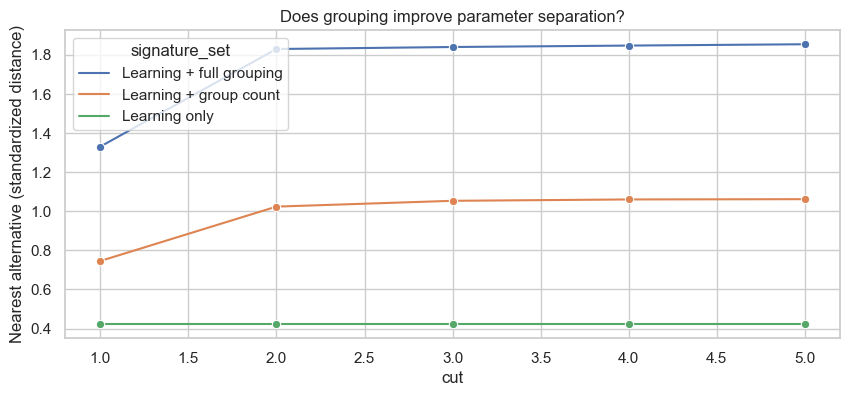

mean    min  median
cut signature_set                                 
1   Learning + full grouping  1.330  0.207   0.817
    Learning + group count    0.745  0.201   0.793
    Learning only             0.422  0.201   0.298
2   Learning + full grouping  1.829  0.791   1.679
    Learning + group count    1.023  0.423   1.107
    Learning only             0.422  0.201   0.298
3   Learning + full grouping  1.840  0.729   1.739
    Learning + group count    1.053  0.403   1.127
    Learning only             0.422  0.201   0.298
4   Learning + full grouping  1.847  0.727   1.723
    Learning + group count    1.060  0.402   1.119
    Learning only             0.422  0.201   0.298
5   Learning + full grouping  1.854  0.726   1.722
    Learning + group count    1.061  0.401   1.116
    Learning only             0.422  0.201   0.298

Comparisons are descriptive, not calibrated grouping likelihoods.
Learning + grouping distances are not yet parameter recovery.
The grouping readout depth has not been identified from behavior.


In [ ]:

# 20D · Incremental identifiability from explicit grouping
# Descriptive signature distances, not likelihood-based parameter recovery.

from scipy.spatial.distance import cdist

# Use averaged model signatures across seeds and schedules.
LEARNING_METRICS = [
    "learn_resource_gain",
    "learn_gem_gain",
    "learn_gadget_gain"
]
GROUPING_METRICS = [
    "n_groups",
    "gem_cohesion",
    "resource_only_cohesion",
    "cross_resource_merge"
]

learning_grid = (
    ID_GRID.groupby(["alpha", "rho"])[LEARNING_METRICS]
    .mean().reset_index()
)

def nearest_parameter_distance(frame, metrics):
    """Distance to nearest different grid setting in standardized space."""
    X = frame[metrics].to_numpy(float)
    means = np.nanmean(X, axis=0)
    scales = np.nanstd(X, axis=0)
    scales = np.where(scales > 1e-8, scales, 1.)
    Z = (X - means) / scales

    D = cdist(Z, Z)
    np.fill_diagonal(D, np.inf)
    return D.min(axis=1)

IDENTIFIABILITY_ROWS = []

for cut in GROUP_CUTS:
    g = GROUP_MEANS[GROUP_MEANS.cut == cut]
    merged = learning_grid.merge(g, on=["alpha", "rho"])

    for model_name, metrics_used in [
        ("Learning only", LEARNING_METRICS),
        ("Learning + group count",
         LEARNING_METRICS + ["n_groups"]),
        ("Learning + full grouping",
         LEARNING_METRICS + GROUPING_METRICS)
    ]:
        distances = nearest_parameter_distance(
            merged, metrics_used
        )
        for (_, r), dist in zip(merged.iterrows(), distances):
            IDENTIFIABILITY_ROWS.append(dict(
                alpha=r.alpha, rho=r.rho,
                cut=cut, signature_set=model_name,
                nearest_distance=dist
            ))

IDENTIFIABILITY = pd.DataFrame(IDENTIFIABILITY_ROWS)

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(
    data=IDENTIFIABILITY.groupby(
        ["cut", "signature_set"], as_index=False
    ).nearest_distance.mean(),
    x="cut", y="nearest_distance",
    hue="signature_set", marker="o", ax=ax
)
ax.set_title("Does grouping improve parameter separation?")
ax.set_ylabel("Nearest alternative (standardized distance)")
plt.show()

display(
    IDENTIFIABILITY.groupby(["cut", "signature_set"])
    .nearest_distance.agg(["mean", "min", "median"]).round(3)
)

# Compare predicted co-grouping with human final partitions.
# For each parameter setting and cut, the model predicts the
# probability that each pair of aliens is grouped together.

def human_partition(sid, checkpoint):
    d = GROUPINGS[
        (GROUPINGS.subject == sid) &
        (GROUPINGS.checkpoint == checkpoint)
    ]
    if d.alien.nunique() != 8:
        return None

    positions = dict(zip(d.alien, d.box))
    return np.array([
        positions[a] == positions[b] for a, b in PAIRS
    ], dtype=float)

# Pairwise grouping predictions require samples of assignments,
# not just summary metrics. Until these are stored, compare
# the four summary measures as a descriptive first approximation.
final_rows = []

for sid in ID_SUBJECTS:
    human = HUMAN_GROUP_SIG[
        (HUMAN_GROUP_SIG.subject == sid) &
        (HUMAN_GROUP_SIG.checkpoint ==
         HUMAN_GROUP_SIG[HUMAN_GROUP_SIG.subject == sid]
         .checkpoint.max())
    ]

    if human.empty or not bool(human.complete.iloc[0]):
        continue

    observed = human.iloc[0]
    for r in GROUP_MEANS.itertuples(index=False):
        model_values = np.array([
            r.n_groups / 8,
            r.gem_cohesion,
            r.resource_only_cohesion,
            r.cross_resource_merge
        ])
        human_values = np.array([
            observed.n_groups / 8,
            observed.gem_cohesion,
            observed.resource_only_cohesion,
            observed.cross_resource_merge
        ])

        final_rows.append(dict(
            subject=sid, alpha=r.alpha, rho=r.rho, cut=r.cut,
            grouping_mse=float(np.nanmean(
                (model_values - human_values)**2
            ))
        ))

GROUP_HUMAN_COMPARISON = pd.DataFrame(final_rows)

if not GROUP_HUMAN_COMPARISON.empty:
    display(
        GROUP_HUMAN_COMPARISON.sort_values("grouping_mse").head(15)
        .round(3)
    )




# Section 21 · Parameter recovery with learning choices and explicit grouping

**Paste these cells after Section 20B** in the existing behavioral-signatures notebook (or execute them there directly). They rely on `model_fit`, `subject_task`, `model_response_vector`, `grouping_candidates`, `TRIALS`, `GROUPINGS`, `KEYS`, `FIXED_OMEGA` from previous sections.

**Design:** Synthetic eight-key responses on actual feedback schedule + synthetic flat eight-alien partitions at grouping checkpoints; distinct generator/evaluator particle-filter seeds; proper normalized probability of all 4,140 partitions; comparison of choices, grouping, and joint parameter recovery. This is conditional-on-feedback recovery under an **auxiliary grouping observation model**, not a full joint generative model of feedback and grouping.

**Quick test:** `REC_RUN=True`, `REC_PARTICLES=10`, `REC_LATENT_DRAWS=50`, `REC_REPS=10`. For stable conclusions increase particles, latent draws, repetitions, seed pairs, and independent participant schedules. Checkpoint 1 is excluded because baseline perceptual grouping is outside HOLMES; checkpoints 4 and 5 are initially excluded because no further feedback enters this HOLMES task model.

**Important caveat:** The Section 20B sampler makes alien routes conditionally independent given a shared posterior particle. Here a separately proposed *new* branch is correctly treated as alien-private instead of spuriously merging all such proposals. This is still not an exact joint eight-alien posterior. Do not use recovery numbers as final model-validity evidence until the grouping observation model is validated.


In [ ]:
# 21A. Recovery design and valid eight-alien partition space.
from itertools import product, combinations
from collections import Counter
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

REC_ALPHAS = np.array([0.1, 0.4, 1.6])
REC_RHOS = np.array([0.0, 0.5, 0.9])
REC_SUBJECTS = ['P008']            # expand to different administered schedules
REC_SEED_PAIRS = [(13, 29)]       # independent generation and evaluation filters
REC_PARTICLES = 50              # smoke test 10; confirmation >=100
REC_LATENT_DRAWS = 200           # simulated latent partitions per setting/checkpoint
REC_REPS = 100                  # synthetic participants per generating setting
REC_CHECKPOINTS = (2, 3)        # baseline is not predicted by HOLMES; 4/5 are redundant
REC_CUT_MIX = {2: 0.5, 3: 0.5}  # FIX this across all parameter settings
REC_GROUP_TAU = 1.0             # log-likelihood penalty per disagreeing alien pair
REC_RANDOM_SEED = 20261015

assert np.isclose(sum(REC_CUT_MIX.values()), 1.0)
assert all(v >= 0 for v in REC_CUT_MIX.values())
assert all(v > 0 for v in REC_ALPHAS)
assert all(0 <= v < 1 for v in REC_RHOS)
assert REC_GROUP_TAU > 0

REC_GRID = [(float(a), float(r)) for a, r in product(REC_ALPHAS, REC_RHOS)]
REC_PAIR_I, REC_PAIR_J = np.triu_indices(8, 1)

# Restricted-growth strings enumerate all set partitions of 8 items (Bell(8)=4140).
def rec_all_partitions(n=8):
    out = []
    def visit(prefix, top):
        if len(prefix) == n:
            out.append(tuple(prefix))
            return
        for k in range(top + 2):
            visit(prefix + [k], max(top, k))
    visit([0], 0)
    return np.asarray(out, dtype=np.int8)

REC_PARTITIONS = rec_all_partitions(8)
REC_PARTITION_INDEX = {tuple(row): i for i, row in enumerate(REC_PARTITIONS)}
REC_SAME = REC_PARTITIONS[:, REC_PAIR_I] == REC_PARTITIONS[:, REC_PAIR_J]
assert REC_PARTITIONS.shape == (4140, 8)
assert REC_SAME.shape == (4140, 28)

# Grouping likelihood will be based on the full eight-alien partition,
# NOT a product of 28 artificially independent pairwise reports.
print('Parameter points:', len(REC_GRID), '| complete partitions:', len(REC_PARTITIONS))
print('Grouping checkpoints:', REC_CHECKPOINTS, '| depth mixture:', REC_CUT_MIX)


Parameter points: 9 | complete partitions: 4140
Grouping checkpoints: (2, 3) | depth mixture: {2: 0.5, 3: 0.5}


In [ ]:
# 21B. Reconstruct checkpoint-specific states and generate *joint* eight-alien
# partitions conditional on a common posterior particle. New/unoccupied paths
# must not be spuriously shared between independently sampled alien probes.

def rec_prefix_task(task, n):
    """Prefix without future feedback; preserves weights and response masks."""
    n = int(n)
    return {
        'schedule': task['schedule'].iloc[:n].copy().reset_index(drop=True),
        'data': task['data'][:, :n].copy(),
        'feedback_mask': task['feedback_mask'][:, :n].copy(),
        'prediction_mask': task['prediction_mask'][:, :n].copy(),
        'family_weights': task['family_weights'][:, :n].copy(),
    }


def rec_checkpoint_positions(sid):
    """Number of learning/single-probe trials before each grouping checkpoint."""
    events = TRIALS.loc[
        TRIALS.subject.eq(sid) & TRIALS.trial_type.isin(['learning', 'single_probe'])
    ].sort_values('event')['event'].to_numpy(float)
    positions = {}
    for cp in REC_CHECKPOINTS:
        g = GROUPINGS.loc[
            GROUPINGS.subject.eq(sid) & GROUPINGS.checkpoint.eq(cp), 'event'
        ]
        if g.empty:
            raise ValueError(f'Missing grouping checkpoint {cp} for {sid}')
        positions[cp] = int(np.sum(events < float(g.min())))
    if any(t <= 0 for t in positions.values()):
        raise ValueError('Baseline/no-training grouping needs an explicit prior readout.')
    if any(t > len(events) for t in positions.values()):
        raise AssertionError('Checkpoint appears after unknown task indices')
    return positions


def rec_canonical(labels):
    """Map any eight integer group labels to a restricted-growth string."""
    mapping, result = {}, []
    for x in labels:
        if x not in mapping:
            mapping[x] = len(mapping)
        result.append(mapping[x])
    return tuple(result)


def rec_one_partition(fit, candidates, rng, cut):
    """Draw a partition, using ONE shared posterior particle for all aliens.

    This remains a conditional-independence approximation for eight alien probes.
    IMPORTANT: an unoccupied candidate node is a *new* branch proposal, not a
    shared existing node. Give it an alien-private identity so independent
    new-branch proposals cannot be falsely co-assigned.
    """
    w = np.asarray(fit['particle_weights'], float).copy()
    w /= w.sum()
    particle = int(rng.choice(len(w), p=w))
    labels = []
    for a in range(8):
        paths, pp = candidates[particle, a]  # grouping_candidates from section 20B
        k = int(rng.choice(len(pp), p=pp))
        path = paths[k]
        signature = []
        for node in path:
            node = int(node)
            if node < 0 or len(signature) >= cut:
                break
            if fit['family_counts'][0][particle, node].sum() == 0:
                # This candidate does not belong to an instantiated branch.
                signature.append(('proposed_new', a))
                break
            signature.append(('existing', node))
        labels.append(tuple(signature))
    return REC_PARTITION_INDEX[rec_canonical(labels)]


def rec_latent_partition_samples(fit, n_draws, cut_mix, seed):
    """Draw latent eight-item partitions with prespecified common depth mixture."""
    if 'grouping_candidates' not in globals():
        raise RuntimeError('Run Section 20B first to define grouping_candidates(fit).')
    rng = np.random.default_rng(seed)
    candidates = grouping_candidates(fit)
    cuts = np.asarray(list(cut_mix), int)
    cut_w = np.asarray(list(cut_mix.values()), float)
    cut_w /= cut_w.sum()
    return np.array([
        rec_one_partition(fit, candidates, rng,
                          int(rng.choice(cuts, p=cut_w)))
        for _ in range(n_draws)
    ], dtype=np.int32)


def rec_choice_matrix(fit, task):
    """Pre-feedback physical-key distributions on all administered single-family trials."""
    Q = []
    for t, r in task['schedule'].iterrows():
        p = np.asarray(fit['pred_probs'][int(r.query_family)][t], float)
        Q.append(model_response_vector(p, str(r.family_name)))
    P = np.stack(Q)
    assert P.shape == (len(task['schedule']), len(KEYS))
    assert np.allclose(P.sum(axis=1), 1, atol=1e-8)
    return P


In [ ]:

# Reuse this cache between inference passes; changing particles/cut mixture/tau
# requires clearing or rebuilding it.
REC_CACHE = {}
REC_RUN = True                  # switch True to build the recovery prediction library

def rec_build_cache():
    for sid in REC_SUBJECTS:
        _, task = subject_task(sid)
        positions = rec_checkpoint_positions(sid)
        print(f'{sid}: total trials={len(task["schedule"])}, '
              f'checkpoint prefixes={positions}')
        for alpha, rho in REC_GRID:
            for seed in sorted(set(x for pair in REC_SEED_PAIRS for x in pair)):
                key = (sid, alpha, rho, int(seed))
                if key in REC_CACHE:
                    continue
                # First obtain all pre-feedback choice probabilities.
                full = model_fit(task, alpha, FIXED_OMEGA, rho=rho,
                                 particles=REC_PARTICLES, seed=int(seed))
                choice_P = rec_choice_matrix(full, task)
                latent = {}
                fit_by_position = {len(task['schedule']): full}
                for cp, n in positions.items():
                    if n not in fit_by_position:
                        fit_by_position[n] = model_fit(
                            rec_prefix_task(task, n), alpha, FIXED_OMEGA,
                            rho=rho, particles=REC_PARTICLES, seed=int(seed)
                        )
                    # Vary random numbers used for observations, NOT the PF fit.
                    draw_seed = (int(seed) * 100003 + int(cp) * 97 +
                                 int(round(alpha * 1000)) * 11 +
                                 int(round(rho * 1000))) % (2**32)
                    latent[cp] = rec_latent_partition_samples(
                        fit_by_position[n], REC_LATENT_DRAWS,
                        REC_CUT_MIX, draw_seed
                    )
                REC_CACHE[key] = {'choice': choice_P, 'latent': latent,
                                  'positions': positions}
                del fit_by_position, full
    print('Cached model settings:', len(REC_CACHE))

if REC_RUN:
    rec_build_cache()
else:
    print('Set REC_RUN=True to compute independent-seed recovery predictions.')


P008: total trials=107, checkpoint prefixes={2: 86, 3: 107}
Cached model settings: 18


In [ ]:
# 21C. A PROPER likelihood for a complete eight-alien flat partition.
# For a latent partition Z and observed grouping G,
# P(G|Z) = exp(-tau * #discordant alien pairs) / sum_H exp(-tau * d(H,Z)),
# where H runs over all 4,140 possible partitions. This normalization is vital.
# The kernel is an auxiliary model of participants' explicit grouping reports.

def rec_grouping_distribution(latent_indices, tau=REC_GROUP_TAU):
    counts = np.bincount(latent_indices, minlength=len(REC_PARTITIONS))
    unique = np.flatnonzero(counts)
    freq = counts[unique] / counts.sum()
    # [4140 possible observed partitions, U unique latent partitions]
    distances = np.count_nonzero(
        REC_SAME[:, None, :] != REC_SAME[None, unique, :], axis=2
    )
    logweights = -float(tau) * distances.astype(float)
    kernel = np.exp(logweights - logweights.max(axis=0, keepdims=True))
    kernel /= kernel.sum(axis=0, keepdims=True)
    result = kernel @ freq
    result /= result.sum()
    assert np.isclose(result.sum(), 1.0, atol=1e-9)
    return result


def rec_model_tables(cache=REC_CACHE, tau=REC_GROUP_TAU):
    """Build likelihood tables without rerunning HOLMES; useful for tau sensitivity."""
    return {
        key: {'choice': val['choice'],
              'group': {cp: rec_grouping_distribution(draws, tau)
                        for cp, draws in val['latent'].items()}}
        for key, val in cache.items()
    }

if REC_RUN:
    REC_TABLES = rec_model_tables()
    key = next(iter(REC_TABLES))
    print('Example:', key)
    print('Choice likelihoods:', REC_TABLES[key]['choice'].shape)
    print('Group likelihood shapes:',
          {cp: p.shape for cp, p in REC_TABLES[key]['group'].items()})


Example: ('P008', 0.1, 0.0, 13)
Choice likelihoods: (107, 8)
Group likelihood shapes: {2: (4140,), 3: (4140,)}


,method,exact,alpha_correct,rho_correct,alpha_log_mae,rho_mae,n
0,choices,0.506,0.506,0.977,0.878,0.010,900
1,combined,0.509,0.509,0.979,0.846,0.009,900
2,grouping,0.206,0.451,0.402,0.946,0.350,900


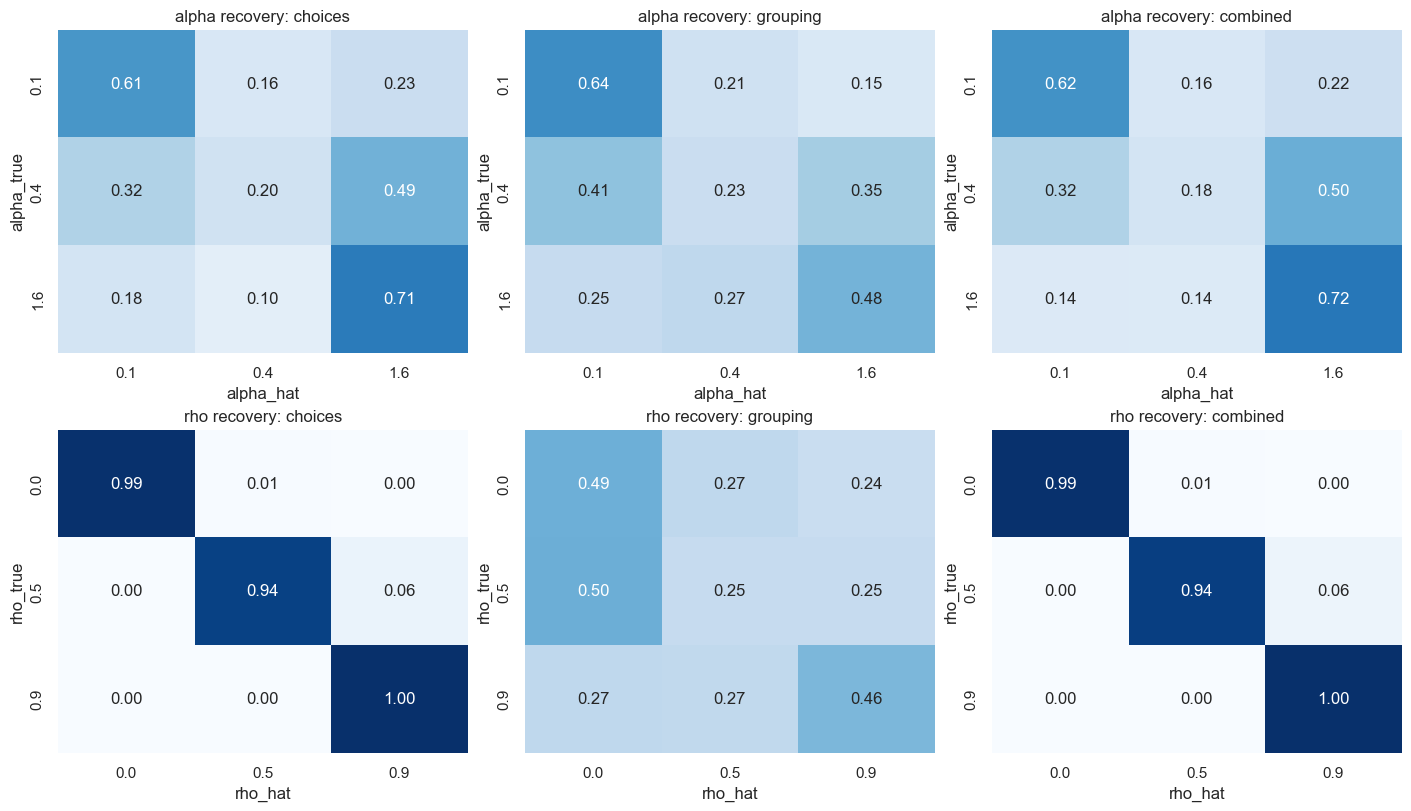

In [ ]:
# 21D. Generate NEW responses at each grid point and recover parameters.
# The generating and evaluation filters have different seeds. The same synthetic
# responses are evaluated for choice-only, grouping-only, and joint likelihoods.

def rec_simulate_and_recover(tables, reps=REC_REPS, seed=REC_RANDOM_SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for sid in REC_SUBJECTS:
        for gen_seed, eval_seed in REC_SEED_PAIRS:
            candidate_keys = [(sid, a, r, eval_seed) for a, r in REC_GRID]
            missing = [k for k in candidate_keys if k not in tables]
            if missing:
                raise ValueError(f'Missing candidate likelihoods, e.g. {missing[0]}')
            # Log probabilities are finite because lapse > 0 and tau > 0.
            cand_choice = np.stack([tables[k]['choice'] for k in candidate_keys])
            cand_group = {
                cp: np.stack([tables[k]['group'][cp] for k in candidate_keys])
                for cp in REC_CHECKPOINTS
            }
            n_trials = cand_choice.shape[1]
            for alpha, rho in REC_GRID:
                true_key = (sid, alpha, rho, gen_seed)
                if true_key not in tables:
                    raise ValueError(f'Missing generating setting: {true_key}')
                gp = tables[true_key]
                assert gp['choice'].shape[0] == n_trials
                for rep in range(reps):
                    # Conditional-on-feedback responses, not new feedback sequences.
                    y = np.array([
                        rng.choice(len(KEYS), p=p) for p in gp['choice']
                    ], dtype=np.int32)
                    g = {cp: int(rng.choice(len(REC_PARTITIONS), p=gp['group'][cp]))
                         for cp in REC_CHECKPOINTS}
                    ll_choice = np.log(np.maximum(
                        cand_choice[:, np.arange(n_trials), y], 1e-300
                    )).sum(axis=1)
                    ll_group = sum(
                        np.log(np.maximum(cand_group[cp][:, label], 1e-300))
                        for cp, label in g.items()
                    )
                    for method, ll in [
                        ('choices', ll_choice),
                        ('grouping', ll_group),
                        ('combined', ll_choice + ll_group)
                    ]:
                        best = int(np.argmax(ll))
                        a_hat, r_hat = REC_GRID[best]
                        rows.append(dict(
                            subject=sid, gen_seed=gen_seed, eval_seed=eval_seed,
                            alpha_true=alpha, rho_true=rho,
                            alpha_hat=a_hat, rho_hat=r_hat,
                            rep=rep, method=method,
                            exact=(a_hat == alpha and r_hat == rho),
                            alpha_correct=(a_hat == alpha),
                            rho_correct=(r_hat == rho),
                            alpha_abs_log_error=abs(np.log(a_hat / alpha)),
                            rho_abs_error=abs(r_hat-rho),
                            true_grid_loglik=float(ll[REC_GRID.index((alpha, rho))]),
                            max_loglik=float(ll[best])
                        ))
    return pd.DataFrame(rows)

if REC_RUN:
    REC_RECOVERY = rec_simulate_and_recover(REC_TABLES)
    REC_SUMMARY = REC_RECOVERY.groupby('method', as_index=False).agg(
        exact=('exact', 'mean'),
        alpha_correct=('alpha_correct', 'mean'),
        rho_correct=('rho_correct', 'mean'),
        alpha_log_mae=('alpha_abs_log_error', 'mean'),
        rho_mae=('rho_abs_error', 'mean'),
        n=('exact', 'size')
    )
    display(REC_SUMMARY.round(3))
    fig, axs = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
    for i, parameter in enumerate(['alpha', 'rho']):
        for j, method in enumerate(['choices', 'grouping', 'combined']):
            d = REC_RECOVERY[REC_RECOVERY.method.eq(method)]
            tab = pd.crosstab(d[f'{parameter}_true'],
                              d[f'{parameter}_hat'], normalize='index')
            tab = tab.reindex(index=REC_ALPHAS if parameter=='alpha' else REC_RHOS,
                              columns=REC_ALPHAS if parameter=='alpha' else REC_RHOS,
                              fill_value=0)
            sns.heatmap(tab, vmin=0, vmax=1, annot=True, fmt='.2f',
                        cmap='Blues', ax=axs[i,j], cbar=False)
            axs[i,j].set_title(f'{parameter} recovery: {method}')
    plt.show()


In [ ]:
# 21E. Recovery diagnostic: parameter-specific failure modes and checks.
# A gain in correct classification is insufficient if it comes from shared
# PF randomness, an incorrectly specified readout rule, or a biased estimator.

if REC_RUN:
    print('Parameter-specific exact recovery by generating point:')
    pivot = (REC_RECOVERY.groupby(['alpha_true', 'rho_true', 'method'])
             .exact.mean().unstack('method'))
    display(pivot.round(3))
    print('Mean error by generating point and estimator:')
    display(REC_RECOVERY.groupby(['alpha_true','rho_true','method'])
            [['alpha_abs_log_error','rho_abs_error']].mean().round(3))

    # Matched synthetic dataset: improvement from adding grouping.
    rates = REC_RECOVERY.pivot(
        index=['subject','gen_seed','eval_seed','alpha_true','rho_true','rep'],
        columns='method', values='exact'
    )
    print('Combined minus choice-only exact-recovery rate:',
          round(float(rates['combined'].mean()-rates['choices'].mean()),3))
    print('Combined better on:',
          int(((rates['combined']==1)&(rates['choices']==0)).sum()),
          'synthetic datasets; worse on:',
          int(((rates['combined']==0)&(rates['choices']==1)).sum()))

    # tau robustness without refitting the model; generator and estimator use
    # the SAME changed tau for this sensitivity pass (not misspecification).
    REC_TAU_CHECK = False
    if REC_TAU_CHECK:
        checks = []
        for tau in [0.5, 1.0, 2.0]:
            tab = rec_model_tables(REC_CACHE, tau=tau)
            rr = rec_simulate_and_recover(tab, reps=30, seed=REC_RANDOM_SEED)
            s = rr.groupby('method').exact.mean()
            checks.append(dict(tau=tau, choices=s['choices'],
                               grouping=s['grouping'], combined=s['combined']))
        display(pd.DataFrame(checks).round(3))

print('Scope: conditional-on-feedback recovery under a prespecified grouping readout.')
print('Not yet: a fully joint latent-traj/choice/grouping generative model.')
print('For validation: increase particle count; use >=2 seed pairs and schedules;')
print('vary grouping noise and the FIXED readout-depth mixture.')


Parameter-specific exact recovery by generating point:


method               choices  combined  grouping
alpha_true rho_true                             
0.1        0.0          0.94      0.94      0.50
           0.5          0.25      0.27      0.18
           0.9          0.63      0.66      0.35
0.4        0.0          0.01      0.01      0.04
           0.5          0.00      0.00      0.06
           0.9          0.58      0.53      0.18
1.6        0.0          0.75      0.77      0.30
           0.5          1.00      1.00      0.14
           0.9          0.39      0.40      0.10

Mean error by generating point and estimator:


alpha_abs_log_error  rho_abs_error
alpha_true rho_true method                                      
0.1        0.0      choices                 0.152          0.000
                    combined                0.152          0.000
                    grouping                0.776          0.262
           0.5      choices                 1.733          0.072
                    combined                1.622          0.064
                    grouping                0.665          0.332
           0.9      choices                 0.721          0.000
                    combined                0.693          0.000
                    grouping                0.665          0.280
0.4        0.0      choices                 1.372          0.010
                    combined                1.372          0.010
                    grouping                1.040          0.377
           0.5      choices                 1.386          0.004
                    combined                1.386          0.004
                    grouping                1.081          0.352
           0.9      choices                 0.582          0.000
                    combined                0.652          0.000
                    grouping                1.067          0.330
1.6        0.0      choices                 0.638          0.000
                    combined                0.555          0.000
                    grouping                0.984          0.405
           0.5      choices                 0.000          0.000
                    combined                0.000          0.000
                    grouping                1.026          0.361
           0.9      choices                 1.317          0.000
                    combined                1.178          0.000
                    grouping                1.206          0.448

Combined minus choice-only exact-recovery rate: 0.003
Combined better on: 27 synthetic datasets; worse on: 24
Scope: conditional-on-feedback recovery under a prespecified grouping readout.
Not yet: a fully joint latent-traj/choice/grouping generative model.
For validation: increase particle count; use >=2 seed pairs and schedules;
vary grouping noise and the FIXED readout-depth mixture.


In [ ]:

# 21F FIX · Derive group-count probabilities from cached partitions
# No HOLMES reruns required.

import numpy as np

def rec_partition_group_counts():
    """Number of groups in each enumerated partition."""
    counts = np.array([
        len(set(partition))
        for partition in REC_PARTITIONS
    ], dtype=int)

    assert len(counts) == len(REC_PARTITIONS)
    assert counts.min() >= 1
    assert counts.max() <= 8
    return counts

REC_N_GROUPS = rec_partition_group_counts()

def rec_count_distribution(partition_probs):
    """
    Convert a probability distribution over partitions into
    a probability distribution over numbers of groups.

    Output indices 0,...,8; index 0 has probability zero.
    """
    probs = np.asarray(partition_probs, dtype=float)

    return np.bincount(
        REC_N_GROUPS,
        weights=probs,
        minlength=9
    )

# Add count distributions to all existing cached model predictions.
for key, table in REC_TABLES.items():
    if "count" not in table:
        table["count"] = {
            cp: rec_count_distribution(table["group"][cp])
            for cp in REC_CHECKPOINTS
        }

# Validate probability normalization.
for key, table in REC_TABLES.items():
    for cp in REC_CHECKPOINTS:
        assert np.isclose(
            table["count"][cp].sum(), 1.0,
            atol=1e-6
        ), (key, cp)

print("Group-count distributions added to", len(REC_TABLES), "cached models.")
print("No model refitting required.")


REC_COMPARE_REPS = 100
REC_COMPARE_SEED = 20261016

REC_COMPARE_METHODS = [
    "choices",
    "count_only",
    "full_grouping",
    "choices+count",
    "choices+grouping"
]

def rec_candidate_arrays(tables, sid, evaluation_seed):
    """Likelihood arrays for all candidate alpha-rho combinations."""
    keys = [
        (sid, a, r, evaluation_seed)
        for a, r in REC_GRID
    ]
    missing = [k for k in keys if k not in tables]
    if missing:
        raise KeyError(
            f"Missing model prediction {missing[0]}. "
            "Rebuild the Section 21B/C cache with both seeds."
        )

    return {
        "choice": np.stack([
            tables[k]["choice"] for k in keys
        ]),
        "group": {
            cp: np.stack([
                tables[k]["group"][cp] for k in keys
            ])
            for cp in REC_CHECKPOINTS
        },
        "count": {
            cp: np.stack([
                tables[k]["count"][cp] for k in keys
            ])
            for cp in REC_CHECKPOINTS
        }
    }


def rec_loglikelihoods(candidate, choices, groupings):
    """Five log-likelihood vectors, one entry per grid point."""
    n = len(choices)
    rows = np.arange(n)

    ll_choices = np.log(np.maximum(
        candidate["choice"][:, rows, choices], 1e-300
    )).sum(axis=1)

    ll_grouping = sum(
        np.log(np.maximum(
            candidate["group"][cp][:, groupings[cp]], 1e-300
        ))
        for cp in REC_CHECKPOINTS
    )

    ll_count = sum(
        np.log(np.maximum(
            candidate["count"][cp][
                :, int(REC_N_GROUPS[groupings[cp]])
            ], 1e-300
        ))
        for cp in REC_CHECKPOINTS
    )

    return {
        "choices": ll_choices,
        "count_only": ll_count,
        "full_grouping": ll_grouping,
        "choices+count": ll_choices + ll_count,
        "choices+grouping": ll_choices + ll_grouping
    }


def rec_matched_vs_independent(
    tables=REC_TABLES,
    reps=REC_COMPARE_REPS,
    random_seed=REC_COMPARE_SEED
):
    rng = np.random.default_rng(random_seed)
    results = []

    for sid in REC_SUBJECTS:
        for gen_seed, independent_seed in REC_SEED_PAIRS:

            # Both conditions use the same true model and responses.
            eval_arrays = {
                "matched": rec_candidate_arrays(
                    tables, sid, gen_seed
                ),
                "independent": rec_candidate_arrays(
                    tables, sid, independent_seed
                )
            }

            for true_alpha, true_rho in REC_GRID:
                true_key = (
                    sid, true_alpha, true_rho, gen_seed
                )
                if true_key not in tables:
                    raise KeyError(
                        f"Missing generating model: {true_key}"
                    )

                generator = tables[true_key]
                true_idx = REC_GRID.index(
                    (true_alpha, true_rho)
                )

                for rep in range(reps):

                    # Generate synthetic responses ONCE.
                    choices = np.array([
                        rng.choice(len(KEYS), p=p)
                        for p in generator["choice"]
                    ], dtype=int)

                    groupings = {
                        cp: int(rng.choice(
                            len(REC_PARTITIONS),
                            p=generator["group"][cp]
                        ))
                        for cp in REC_CHECKPOINTS
                    }

                    for condition, candidate in eval_arrays.items():
                        likelihoods = rec_loglikelihoods(
                            candidate, choices, groupings
                        )

                        for method, ll in likelihoods.items():
                            best = int(np.argmax(ll))
                            alpha_hat, rho_hat = REC_GRID[best]

                            results.append({
                                "subject": sid,
                                "gen_seed": gen_seed,
                                "independent_seed": independent_seed,
                                "alpha_true": true_alpha,
                                "rho_true": true_rho,
                                "rep": rep,
                                "condition": condition,
                                "method": method,
                                "alpha_hat": alpha_hat,
                                "rho_hat": rho_hat,
                                "exact": int(best == true_idx),
                                "alpha_correct": int(
                                    alpha_hat == true_alpha
                                ),
                                "rho_correct": int(
                                    rho_hat == true_rho
                                ),
                                "alpha_log_error": abs(
                                    np.log(alpha_hat / true_alpha)
                                ),
                                "rho_error": abs(
                                    rho_hat - true_rho
                                ),
                                "true_loglik": float(ll[true_idx]),
                                "best_loglik": float(ll[best]),
                                "loglik_gap": float(
                                    ll[best] - ll[true_idx]
                                )
                            })

    return pd.DataFrame(results)


REC_SEED_COMPARISON = rec_matched_vs_independent()

REC_SEED_SUMMARY = (
    REC_SEED_COMPARISON
    .groupby(["condition", "method"], as_index=False)
    .agg(
        exact=("exact", "mean"),
        alpha_correct=("alpha_correct", "mean"),
        rho_correct=("rho_correct", "mean"),
        alpha_log_mae=("alpha_log_error", "mean"),
        rho_mae=("rho_error", "mean"),
        mean_loglik_gap=("loglik_gap", "mean"),
        n=("exact", "size")
    )
)

display(REC_SEED_SUMMARY.round(3))

# Show how much performance changes when the evaluation seed differs.
wide = REC_SEED_SUMMARY.pivot(
    index="method",
    columns="condition",
    values=["exact", "alpha_correct", "rho_correct",
            "alpha_log_mae", "rho_mae"]
)

REC_SEED_DELTA = pd.DataFrame(index=wide.index)

for metric in [
    "exact", "alpha_correct", "rho_correct",
    "alpha_log_mae", "rho_mae"
]:
    REC_SEED_DELTA[f"{metric}_independent_minus_matched"] = (
        wide[(metric, "independent")] -
        wide[(metric, "matched")]
    )

print("Independent minus matched:")
display(REC_SEED_DELTA.round(3))


Group-count distributions added to 18 cached models.
No model refitting required.


,condition,method,exact,alpha_correct,rho_correct,alpha_log_mae,rho_mae,mean_loglik_gap,n
0,independent,choices,0.514,0.516,0.973,0.858,0.011,2.644,900
1,independent,choices+count,0.524,0.526,0.973,0.832,0.011,2.589,900
2,independent,choices+grouping,0.520,0.521,0.973,0.835,0.011,2.686,900
3,independent,count_only,0.178,0.437,0.391,1.086,0.347,0.303,900
4,independent,full_grouping,0.190,0.440,0.398,0.990,0.359,0.912,900
5,matched,choices,0.933,0.933,1.000,0.105,0.000,0.096,900
6,matched,choices+count,0.932,0.932,1.000,0.106,0.000,0.095,900
7,matched,choices+grouping,0.942,0.942,1.000,0.091,0.000,0.079,900
8,matched,count_only,0.178,0.438,0.424,1.078,0.362,0.300,900
9,matched,full_grouping,0.304,0.536,0.482,0.823,0.311,0.571,900


Independent minus matched:


,exact_independent_minus_matched,alpha_correct_independent_minus_matched,rho_correct_independent_minus_matched,alpha_log_mae_independent_minus_matched,rho_mae_independent_minus_matched
method,,,,,
choices,-0.419,-0.418,-0.027,0.753,0.011
choices+count,-0.408,-0.407,-0.027,0.725,0.011
choices+grouping,-0.422,-0.421,-0.027,0.744,0.011
count_only,0.000,-0.001,-0.033,0.008,-0.015
full_grouping,-0.114,-0.096,-0.084,0.168,0.049


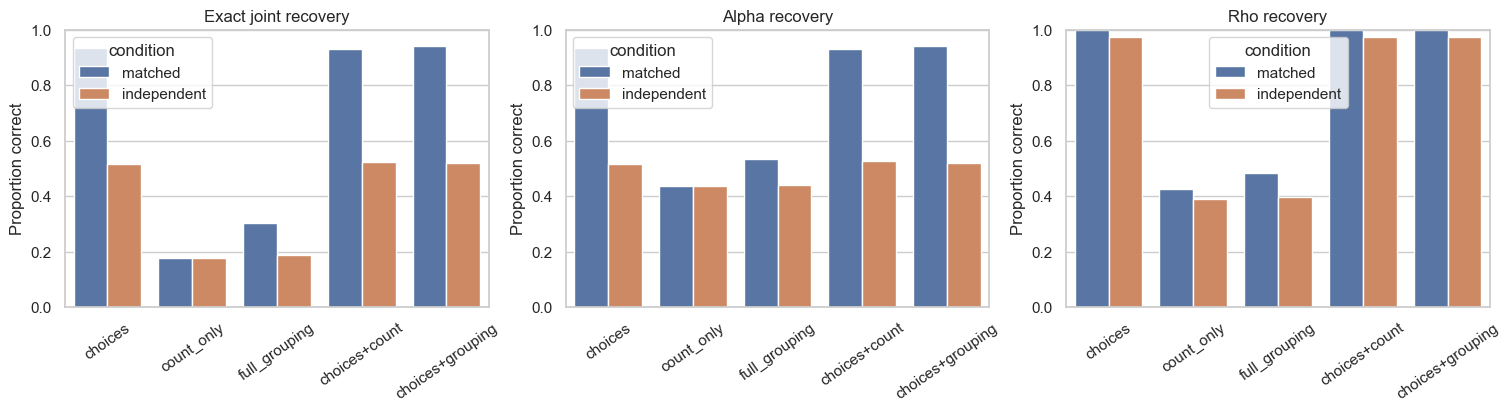

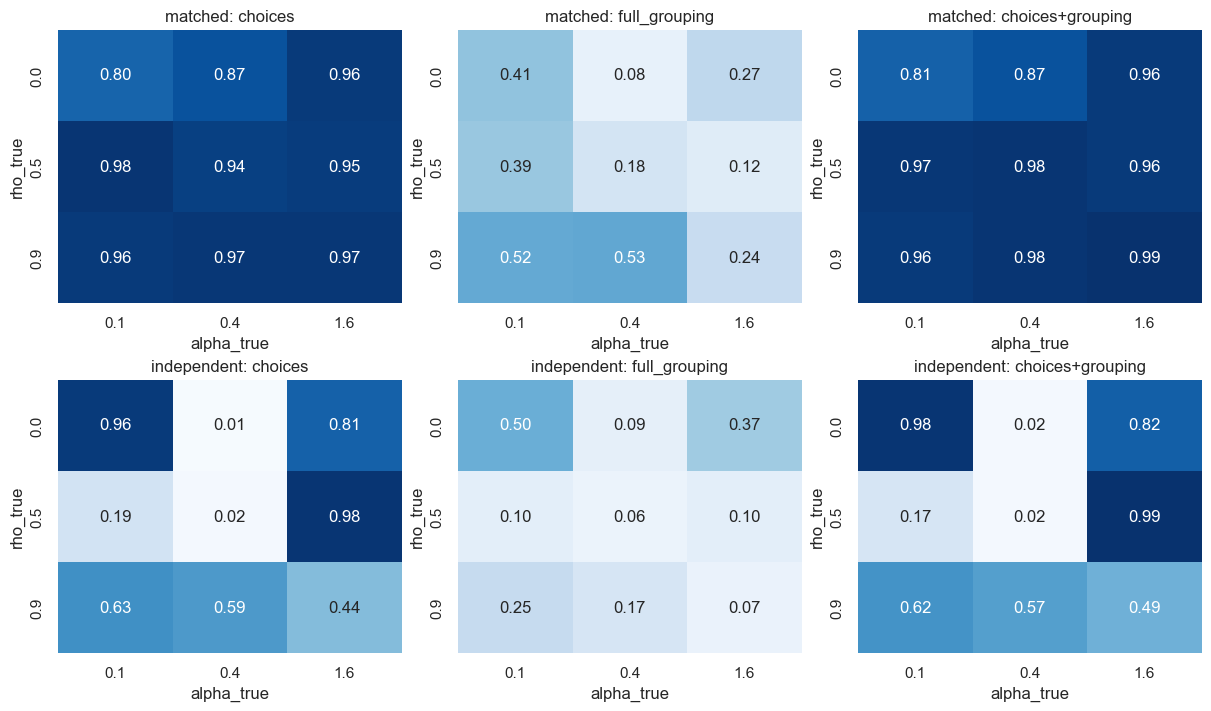

Paired evaluation-seed sensitivity:


,alpha_estimate_changed,rho_estimate_changed,matched_correct,independent_correct,matched_only_correct,independent_only_correct
method,,,,,,
choices,0.488,0.027,0.933,0.514,0.447,0.028
choices+count,0.480,0.027,0.932,0.524,0.437,0.029
choices+grouping,0.487,0.027,0.942,0.520,0.449,0.027
count_only,0.099,0.290,0.178,0.178,0.039,0.039
full_grouping,0.478,0.497,0.304,0.190,0.209,0.094


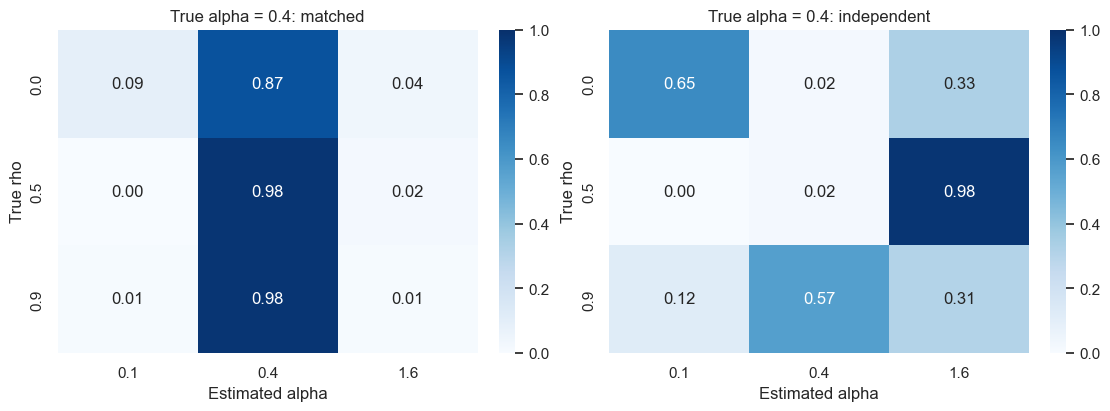

In [ ]:

# 21G · Recovery diagnostics for matched vs independent predictions

# 1. Overall recovery accuracy by method and condition.
fig, axs = plt.subplots(
    1, 3, figsize=(15, 4), constrained_layout=True
)

for ax, (metric, title) in zip(axs, [
    ("exact", "Exact joint recovery"),
    ("alpha_correct", "Alpha recovery"),
    ("rho_correct", "Rho recovery")
]):
    sns.barplot(
        data=REC_SEED_COMPARISON,
        x="method", y=metric,
        hue="condition",
        errorbar=None, ax=ax
    )
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=35)
    ax.set_xlabel("")
    ax.set_ylabel("Proportion correct")

plt.show()


# 2. Recovery accuracy for each true parameter combination.
point_summary = (
    REC_SEED_COMPARISON
    .groupby([
        "condition", "method", "alpha_true", "rho_true"
    ], as_index=False)
    .agg(exact=("exact", "mean"))
)

fig, axs = plt.subplots(
    2, 3, figsize=(12, 7), constrained_layout=True
)

methods_to_plot = [
    "choices",
    "full_grouping",
    "choices+grouping"
]

for i, condition in enumerate(["matched", "independent"]):
    for j, method in enumerate(methods_to_plot):
        d = point_summary[
            (point_summary.condition == condition) &
            (point_summary.method == method)
        ]
        z = d.pivot(
            index="rho_true",
            columns="alpha_true",
            values="exact"
        )

        sns.heatmap(
            z, ax=axs[i, j],
            annot=True, fmt=".2f",
            vmin=0, vmax=1,
            cmap="Blues", cbar=False
        )
        axs[i, j].set_title(f"{condition}: {method}")

plt.show()


# 3. How often does the selected parameter change solely because
#    the candidate model was evaluated using a different PF seed?
paired = REC_SEED_COMPARISON.pivot(
    index=[
        "subject", "gen_seed", "independent_seed",
        "alpha_true", "rho_true", "rep", "method"
    ],
    columns="condition",
    values=[
        "alpha_hat", "rho_hat",
        "exact", "alpha_correct", "rho_correct"
    ]
)

paired_change = pd.DataFrame(index=paired.index)

paired_change["alpha_estimate_changed"] = (
    paired[("alpha_hat", "matched")] !=
    paired[("alpha_hat", "independent")]
)

paired_change["rho_estimate_changed"] = (
    paired[("rho_hat", "matched")] !=
    paired[("rho_hat", "independent")]
)

paired_change["matched_correct"] = paired[
    ("exact", "matched")
]

paired_change["independent_correct"] = paired[
    ("exact", "independent")
]

paired_change["matched_only_correct"] = (
    paired_change.matched_correct.eq(1) &
    paired_change.independent_correct.eq(0)
)

paired_change["independent_only_correct"] = (
    paired_change.matched_correct.eq(0) &
    paired_change.independent_correct.eq(1)
)

print("Paired evaluation-seed sensitivity:")
display(
    paired_change.groupby(level="method").mean().round(3)
)

# 4. Is the true intermediate alpha systematically confused?
alpha_middle = REC_SEED_COMPARISON[
    REC_SEED_COMPARISON.alpha_true.eq(0.4)
]

fig, axs = plt.subplots(
    1, 2, figsize=(11, 4), constrained_layout=True
)

for ax, condition in zip(
    axs, ["matched", "independent"]
):
    d = alpha_middle[
        (alpha_middle.condition == condition) &
        (alpha_middle.method == "choices+grouping")
    ]

    z = pd.crosstab(
        d.rho_true, d.alpha_hat,
        normalize="index"
    ).reindex(
        index=REC_RHOS,
        columns=REC_ALPHAS,
        fill_value=0
    )

    sns.heatmap(
        z, annot=True, fmt=".2f",
        cmap="Blues", vmin=0, vmax=1,
        ax=ax
    )
    ax.set_title(
        f"True alpha = 0.4: {condition}"
    )
    ax.set_xlabel("Estimated alpha")
    ax.set_ylabel("True rho")

plt.show()


In [ ]:

# 21H.1 · Seed averaging at a fixed number of particles
# Run after Section 21C.
#
# IMPORTANT: Existing REC_CACHE must have been built with 50 particles.
# If it contains results from earlier particle counts, reset REC_CACHE
# and rebuild it before running this experiment.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

REC_PARTICLES = 50

AVG_GEN_SEED = 13
AVG_EVAL_SEEDS = [29, 31, 37, 41, 43, 47, 53, 59, 61, 67]
AVG_SEED_COUNTS = [1, 3, 5, 10]
AVG_REPS = 100
AVG_RESPONSE_SEED = 20261016

# Start with one schedule (P008), as in your latest experiment.
AVG_SUBJECTS = ["P008"]

# Ensure the cached generator is independent of every evaluation seed.
assert AVG_GEN_SEED not in AVG_EVAL_SEEDS
assert max(AVG_SEED_COUNTS) <= len(AVG_EVAL_SEEDS)

# Reuse the Section 21 cache-building functions.
# Temporarily tell rec_build_cache() which seeds to calculate.
_old_subjects = REC_SUBJECTS
_old_seed_pairs = REC_SEED_PAIRS

try:
    REC_SUBJECTS = AVG_SUBJECTS
    REC_SEED_PAIRS = [
        (AVG_GEN_SEED, s) for s in AVG_EVAL_SEEDS
    ]

    print("Building/reusing model predictions...")
    rec_build_cache()

finally:
    REC_SUBJECTS = _old_subjects
    REC_SEED_PAIRS = _old_seed_pairs

# Convert only the relevant cached entries into likelihood tables.
avg_keys = [
    (sid, a, r, seed)
    for sid in AVG_SUBJECTS
    for a, r in REC_GRID
    for seed in [AVG_GEN_SEED] + AVG_EVAL_SEEDS
]

AVG_CACHE = {k: REC_CACHE[k] for k in avg_keys}
AVG_TABLES = rec_model_tables(cache=AVG_CACHE, tau=REC_GROUP_TAU)

def avg_candidate_tables(subject, seeds):
    """
    Average complete predictive distributions over evaluation seeds.

    The result has the same structure as an individual REC_TABLES entry,
    except candidate parameters are stacked along axis 0.
    """
    keys_by_parameter = [
        [(subject, a, r, s) for s in seeds]
        for a, r in REC_GRID
    ]

    choices = np.stack([
        np.mean(
            [AVG_TABLES[k]["choice"] for k in keys],
            axis=0
        )
        for keys in keys_by_parameter
    ])

    groups = {}
    counts = {}

    for cp in REC_CHECKPOINTS:
        groups[cp] = np.stack([
            np.mean(
                [AVG_TABLES[k]["group"][cp] for k in keys],
                axis=0
            )
            for keys in keys_by_parameter
        ])

        # Derive count probabilities from the averaged full
        # partition probabilities to preserve consistency.
        counts[cp] = np.stack([
            np.bincount(
                REC_N_GROUPS,
                weights=p,
                minlength=9
            )
            for p in groups[cp]
        ])

    assert np.allclose(choices.sum(axis=-1), 1)
    for cp in REC_CHECKPOINTS:
        assert np.allclose(groups[cp].sum(axis=-1), 1)
        assert np.allclose(counts[cp].sum(axis=-1), 1)

    return {"choice": choices, "group": groups, "count": counts}


AVG_CANDIDATES = {
    (sid, n): avg_candidate_tables(
        sid, AVG_EVAL_SEEDS[:n]
    )
    for sid in AVG_SUBJECTS
    for n in AVG_SEED_COUNTS
}

print("Ready.")
print("Parameter combinations:", len(REC_GRID))
print("Particle count per fit:", REC_PARTICLES)
print("Evaluation seed counts:", AVG_SEED_COUNTS)
print("Candidate tables:", len(AVG_CANDIDATES))


Building/reusing model predictions...
P008: total trials=107, checkpoint prefixes={2: 86, 3: 107}
Cached model settings: 99
Ready.
Parameter combinations: 9
Particle count per fit: 50
Evaluation seed counts: [1, 3, 5, 10]
Candidate tables: 4


In [ ]:

# 21H.2 · Controlled recovery with 1, 3, 5, 10 evaluation seeds
# Same synthetic responses in every condition.

rng = np.random.default_rng(AVG_RESPONSE_SEED)

AVG_DATASETS = []

for sid in AVG_SUBJECTS:
    for true_alpha, true_rho in REC_GRID:
        true_key = (
            sid, true_alpha, true_rho, AVG_GEN_SEED
        )
        generator = AVG_TABLES[true_key]

        for rep in range(AVG_REPS):

            # Draw choices once from the generating model.
            choices = np.array([
                rng.choice(len(KEYS), p=p)
                for p in generator["choice"]
            ], dtype=int)

            # Draw one complete eight-alien grouping response
            # for each selected checkpoint.
            groupings = {
                cp: int(rng.choice(
                    len(REC_PARTITIONS),
                    p=generator["group"][cp]
                ))
                for cp in REC_CHECKPOINTS
            }

            AVG_DATASETS.append(dict(
                subject=sid,
                alpha_true=true_alpha,
                rho_true=true_rho,
                rep=rep,
                choices=choices,
                groupings=groupings
            ))

print("Synthetic datasets:", len(AVG_DATASETS))


def avg_score_candidates(candidate, choices, groupings):
    """Return five log-likelihood vectors over REC_GRID."""
    t = np.arange(len(choices))

    ll_choice = np.log(np.maximum(
        candidate["choice"][:, t, choices], 1e-300
    )).sum(axis=1)

    ll_group = sum(
        np.log(np.maximum(
            candidate["group"][cp][:, groupings[cp]],
            1e-300
        ))
        for cp in REC_CHECKPOINTS
    )

    ll_count = sum(
        np.log(np.maximum(
            candidate["count"][cp][
                :, int(REC_N_GROUPS[groupings[cp]])
            ],
            1e-300
        ))
        for cp in REC_CHECKPOINTS
    )

    return {
        "choices": ll_choice,
        "count_only": ll_count,
        "full_grouping": ll_group,
        "choices+count": ll_choice + ll_count,
        "choices+grouping": ll_choice + ll_group
    }


AVG_ROWS = []

for dataset in AVG_DATASETS:
    sid = dataset["subject"]
    a_true = dataset["alpha_true"]
    r_true = dataset["rho_true"]
    true_index = REC_GRID.index((a_true, r_true))

    for n_seeds in AVG_SEED_COUNTS:
        candidate = AVG_CANDIDATES[(sid, n_seeds)]

        likelihoods = avg_score_candidates(
            candidate,
            dataset["choices"],
            dataset["groupings"]
        )

        for method, ll in likelihoods.items():
            best = int(np.argmax(ll))
            a_hat, r_hat = REC_GRID[best]

            AVG_ROWS.append(dict(
                subject=sid,
                alpha_true=a_true,
                rho_true=r_true,
                rep=dataset["rep"],
                n_seeds=n_seeds,
                method=method,
                alpha_hat=a_hat,
                rho_hat=r_hat,
                exact=int(best == true_index),
                alpha_correct=int(a_hat == a_true),
                rho_correct=int(r_hat == r_true),
                alpha_log_error=abs(np.log(a_hat / a_true)),
                rho_error=abs(r_hat - r_true),
                loglik_gap=float(
                    ll[best] - ll[true_index]
                )
            ))

AVG_RECOVERY = pd.DataFrame(AVG_ROWS)

AVG_SUMMARY = (
    AVG_RECOVERY
    .groupby(["n_seeds", "method"], as_index=False)
    .agg(
        exact=("exact", "mean"),
        alpha_correct=("alpha_correct", "mean"),
        rho_correct=("rho_correct", "mean"),
        alpha_log_mae=("alpha_log_error", "mean"),
        rho_mae=("rho_error", "mean"),
        mean_loglik_gap=("loglik_gap", "mean"),
        n=("exact", "size")
    )
)

display(AVG_SUMMARY.round(3))


Synthetic datasets: 900


,n_seeds,method,exact,alpha_correct,rho_correct,alpha_log_mae,rho_mae,mean_loglik_gap,n
0,1,choices,0.514,0.516,0.973,0.858,0.011,2.644,900
1,1,choices+count,0.524,0.526,0.973,0.832,0.011,2.589,900
2,1,choices+grouping,0.520,0.521,0.973,0.835,0.011,2.686,900
3,1,count_only,0.178,0.437,0.391,1.086,0.347,0.303,900
4,1,full_grouping,0.190,0.440,0.398,0.990,0.359,0.912,900
5,3,choices,0.549,0.549,1.000,0.709,0.000,1.085,900
6,3,choices+count,0.566,0.566,1.000,0.667,0.000,1.047,900
7,3,choices+grouping,0.557,0.557,1.000,0.682,0.000,1.124,900
8,3,count_only,0.170,0.437,0.391,1.086,0.364,0.344,900
9,3,full_grouping,0.192,0.439,0.418,0.935,0.327,0.811,900


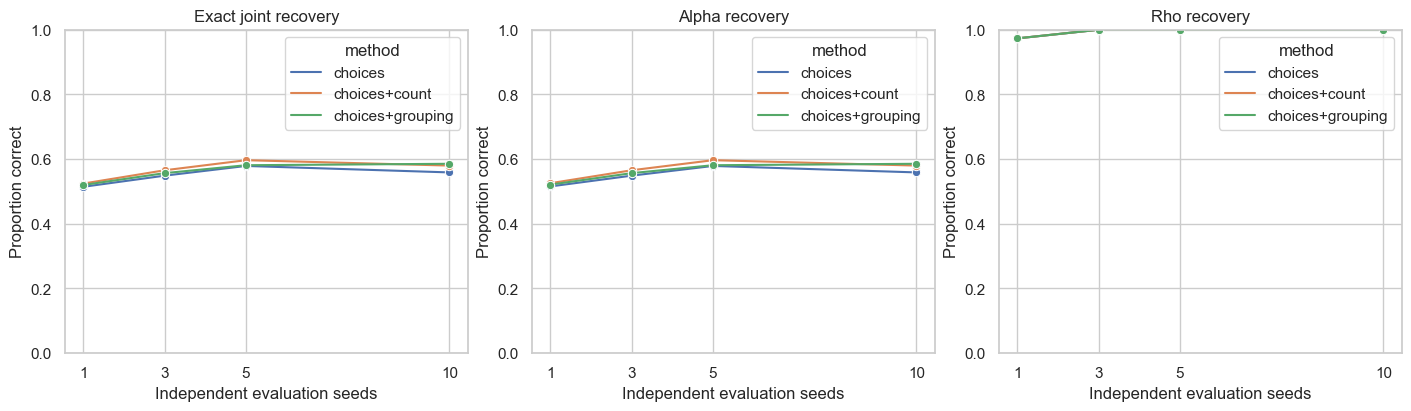

,n_seeds,method,alpha_correct,exact
0,1,choices,0.207,0.207
1,1,choices+count,0.210,0.210
2,1,choices+grouping,0.203,0.203
3,1,count_only,0.087,0.013
4,1,full_grouping,0.257,0.107
5,3,choices,0.397,0.397
6,3,choices+count,0.433,0.433
7,3,choices+grouping,0.437,0.437
8,3,count_only,0.087,0.013
9,3,full_grouping,0.330,0.143


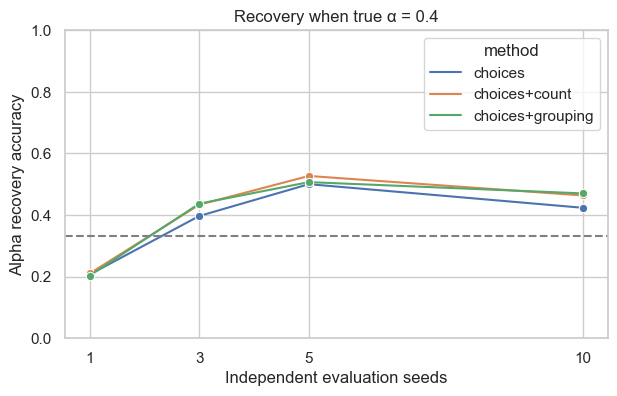

method,choices,choices+count,choices+grouping,count_only,full_grouping
n_seeds,,,,,
1,0.593,0.591,0.578,0.752,0.498
3,0.706,0.703,0.720,0.900,0.564
5,0.796,0.797,0.823,0.780,0.689
10,1.000,1.000,1.000,1.000,1.000


In [ ]:

# 21H.3 · Recovery convergence and intermediate-alpha diagnostics

methods = ["choices", "choices+count", "choices+grouping"]

fig, axs = plt.subplots(
    1, 3, figsize=(14, 4),
    constrained_layout=True
)

for ax, (metric, title) in zip(axs, [
    ("exact", "Exact joint recovery"),
    ("alpha_correct", "Alpha recovery"),
    ("rho_correct", "Rho recovery")
]):
    sns.lineplot(
        data=AVG_SUMMARY[
            AVG_SUMMARY.method.isin(methods)
        ],
        x="n_seeds", y=metric,
        hue="method", marker="o", ax=ax
    )
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_xticks(AVG_SEED_COUNTS)
    ax.set_xlabel("Independent evaluation seeds")
    ax.set_ylabel("Proportion correct")

plt.show()


# Recovery when the true alpha is the intermediate value 0.4.
middle = AVG_RECOVERY[
    AVG_RECOVERY.alpha_true == 0.4
]

mid_summary = (
    middle.groupby(
        ["n_seeds", "method"], as_index=False
    )
    .agg(
        alpha_correct=("alpha_correct", "mean"),
        exact=("exact", "mean")
    )
)

display(mid_summary.round(3))

fig, ax = plt.subplots(figsize=(7, 4))

sns.lineplot(
    data=mid_summary[
        mid_summary.method.isin(methods)
    ],
    x="n_seeds",
    y="alpha_correct",
    hue="method",
    marker="o",
    ax=ax
)

ax.axhline(1/3, linestyle="--", color="gray",
           label="Uniform-guess baseline")
ax.set_title("Recovery when true α = 0.4")
ax.set_xlabel("Independent evaluation seeds")
ax.set_ylabel("Alpha recovery accuracy")
ax.set_ylim(0, 1)
ax.set_xticks(AVG_SEED_COUNTS)
plt.show()


# Numerical disagreement with the 10-seed reference.
# This measures stability of parameter estimates for the same
# response dataset, rather than correctness.

ref = AVG_RECOVERY[
    AVG_RECOVERY.n_seeds == max(AVG_SEED_COUNTS)
][["subject", "alpha_true", "rho_true", "rep",
   "method", "alpha_hat", "rho_hat"]].rename(
    columns={
        "alpha_hat": "alpha_ref",
        "rho_hat": "rho_ref"
    }
)

stability = AVG_RECOVERY.merge(
    ref,
    on=["subject", "alpha_true", "rho_true",
        "rep", "method"],
    how="left"
)

stability["same_as_10_seed"] = (
    (stability.alpha_hat == stability.alpha_ref) &
    (stability.rho_hat == stability.rho_ref)
)

display(
    stability.groupby(
        ["n_seeds", "method"]
    ).same_as_10_seed.mean().unstack().round(3)
)


choice_jsd                 grouping_jsd                
                    mean  median     max         mean  median     max
ensemble_size                                                        
1                 0.0141  0.0131  0.0307       0.0621  0.0263  0.2894
2                 0.0108  0.0074  0.0345       0.0651  0.0157  0.3253
3                 0.0077  0.0069  0.0207       0.0471  0.0150  0.2427
5                 0.0031  0.0026  0.0054       0.0263  0.0098  0.1459

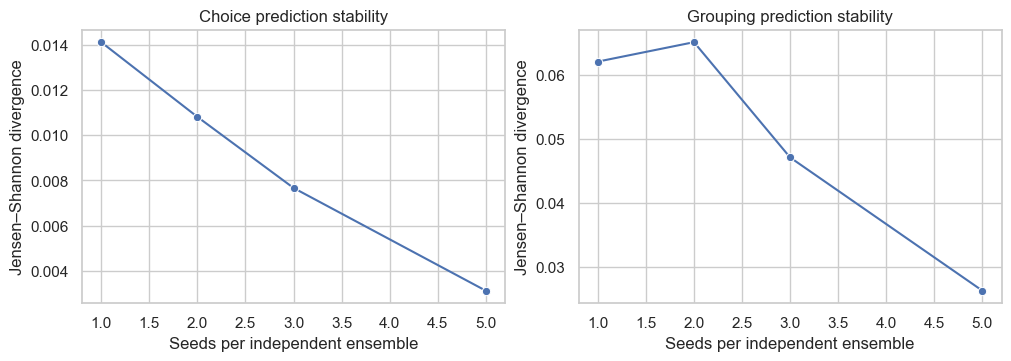

In [ ]:

# 21H.4 · Independent-ensemble prediction stability
# Jensen-Shannon divergence between nonoverlapping seed ensembles.
# Smaller values imply better agreement between numerical predictions.

from scipy.special import rel_entr

def avg_jsd(P, Q):
    P = np.asarray(P, float)
    Q = np.asarray(Q, float)

    M = 0.5 * (P + Q)

    return float(
        np.mean(
            0.5 * np.sum(rel_entr(P, M), axis=-1) +
            0.5 * np.sum(rel_entr(Q, M), axis=-1)
        )
    )

STABILITY_ROWS = []

for sid in AVG_SUBJECTS:
    for alpha, rho in REC_GRID:
        for ensemble_size in [1, 2, 3, 5]:
            first = AVG_EVAL_SEEDS[:ensemble_size]
            second = AVG_EVAL_SEEDS[
                ensemble_size:2*ensemble_size
            ]

            if len(second) < ensemble_size:
                continue

            key = lambda seed: (
                sid, alpha, rho, seed
            )

            p_first = np.mean(
                [AVG_TABLES[key(s)]["choice"] for s in first],
                axis=0
            )
            p_second = np.mean(
                [AVG_TABLES[key(s)]["choice"] for s in second],
                axis=0
            )

            choice_jsd = avg_jsd(p_first, p_second)

            group_jsds = []
            for cp in REC_CHECKPOINTS:
                g_first = np.mean(
                    [AVG_TABLES[key(s)]["group"][cp]
                     for s in first],
                    axis=0
                )
                g_second = np.mean(
                    [AVG_TABLES[key(s)]["group"][cp]
                     for s in second],
                    axis=0
                )
                group_jsds.append(
                    avg_jsd(g_first, g_second)
                )

            STABILITY_ROWS.append(dict(
                subject=sid, alpha=alpha, rho=rho,
                ensemble_size=ensemble_size,
                choice_jsd=choice_jsd,
                grouping_jsd=np.mean(group_jsds)
            ))

AVG_STABILITY = pd.DataFrame(STABILITY_ROWS)

display(
    AVG_STABILITY.groupby("ensemble_size")[
        ["choice_jsd", "grouping_jsd"]
    ].agg(["mean", "median", "max"]).round(4)
)

fig, axs = plt.subplots(
    1, 2, figsize=(10, 3.5),
    constrained_layout=True
)

for ax, metric, title in zip(
    axs,
    ["choice_jsd", "grouping_jsd"],
    ["Choice prediction stability", "Grouping prediction stability"]
):
    sns.lineplot(
        data=AVG_STABILITY,
        x="ensemble_size", y=metric,
        marker="o", errorbar=None, ax=ax
    )
    ax.set_title(title)
    ax.set_ylabel("Jensen–Shannon divergence")
    ax.set_xlabel("Seeds per independent ensemble")

plt.show()
